# 22542695 PREDICTION OF FOOTBALL MATCH RESULTS USING MACHINE LEARNING MODELS

## 1. UPLOAD ESSENTIAL LIBRARIES AND THE EPL DATA

In [1]:
pip install --upgrade scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install --user numpy==1.24.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
conda create -n myenv python=3.8 numpy-1.24.0 scipy

Solving environment: ...working... failed with repodata from current_repodata.json, will retry with next repodata source.
Solving environment: ...working... failed

Note: you may need to restart the kernel to use updated packages.



PackagesNotFoundError: The following packages are not available from current channels:

  - numpy-1.24.0

Current channels:

  - https://repo.anaconda.com/pkgs/main/win-64
  - https://repo.anaconda.com/pkgs/main/noarch
  - https://repo.anaconda.com/pkgs/r/win-64
  - https://repo.anaconda.com/pkgs/r/noarch
  - https://repo.anaconda.com/pkgs/msys2/win-64
  - https://repo.anaconda.com/pkgs/msys2/noarch

To search for alternate channels that may provide the conda package you're
looking for, navigate to

    https://anaconda.org

and use the search bar at the top of the page.




In [4]:
#!pip install --user numpy==1.21.0

In [5]:
import numpy as np
print(np.__version__)

1.24.0


In [6]:
#!pip install --upgrade scikit-learn -q --user

In [7]:
#!pip install --upgrade scikit-learn scipy

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from scipy.stats import poisson
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import balanced_accuracy_score, accuracy_score, classification_report
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
import os
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import seaborn as sns
sns.set(
    style='ticks', 
    context='talk', 
    font_scale=0.8, 
    rc={'figure.figsize': (8,6)}
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

from functools import partial


rmse = partial(mean_squared_error, squared=False)
from sklearn.model_selection import cross_val_score
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score
from sklearn.model_selection import cross_val_score


import random
seed = 42
random.seed(seed)
np.random.seed(seed)

In [9]:
!pip install pandas seaborn matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [10]:
!pip install --upgrade --user tensorflow

In [11]:
print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)

NumPy version: 1.24.0
pandas version: 1.4.2


In [12]:
# folder_path = 'F:/MSc Data Science MMU/Semister 3/Project/THESIS/Football data/fbpdata'
# # Grouped the appropriate csv files
# csv_files = ['0506E0.csv', '0506E1.csv', '0506E2.csv', '0506E3.csv', '0506EC.csv',
#             '0607E0.csv', '0607E1.csv', '0607E2.csv', '0607E3.csv', '0607EC.csv',
#             '0708E0.csv', '0708E1.csv', '0708E2.csv', '0708E3.csv', '0708EC.csv',
#             '0809E0.csv', '0809E1.csv', '0809E2.csv', '0809E3.csv', '0809EC.csv',
#             '0910E0.csv', '0910E1.csv', '0910E2.csv', '0910E3.csv', '0910EC.csv',
#             '1011E0.csv', '1011E1.csv', '1011E2.csv', '1011E3.csv', '1011EC.csv',
#             '1112E0.csv', '1112E1.csv', '1112E2.csv', '1112E3.csv', '1112EC.csv',
#             '1213E0.csv', '1213E1.csv', '1213E2.csv', '1213E3.csv', '1213EC.csv',
#             '1314E0.csv', '1314E1.csv', '1314E2.csv', '1314E3.csv', '1314EC.csv',
#             '1415E0.csv', '1415E1.csv', '1415E2.csv', '1415E3.csv', '1415EC.csv',
#             '1516E0.csv', '1516E1.csv', '1516E2.csv', '1516E3.csv', '1516EC.csv',
#             '1617E0.csv', '1617E1.csv', '1617E2.csv', '1617E3.csv', '1617EC.csv',
#             '1718E0.csv', '1718E1.csv', '1718E2.csv', '1718E3.csv', '1718EC.csv', The
#             '2122E0.csv', '2122E1.csv', '2122E2.csv', '2122E3.csv', '2122EC.csv',
#             '2223E0.csv', '2223E1.csv', '2223E2.csv', '2223E3.csv', '2223EC.csv']


In [13]:
# folder_path = 'F:/MSc Data Science MMU/Semister 3/Project/THESIS/Football data/fbpdata'
# # Grouped the appropriate csv files
# csv_files = ['1011E0.csv', '1011E1.csv', '1011E2.csv', '1011E3.csv', '1011EC.csv',
#             '1112E0.csv', '1112E1.csv', '1112E2.csv', '1112E3.csv', '1112EC.csv',
#             '1213E0.csv', '1213E1.csv', '1213E2.csv', '1213E3.csv', '1213EC.csv',
#             '1314E0.csv', '1314E1.csv', '1314E2.csv', '1314E3.csv', '1314EC.csv',
#             '1415E0.csv', '1415E1.csv', '1415E2.csv', '1415E3.csv', '1415EC.csv',
#             '1516E0.csv', '1516E1.csv', '1516E2.csv', '1516E3.csv', '1516EC.csv',
#             '1617E0.csv', '1617E1.csv', '1617E2.csv', '1617E3.csv', '1617EC.csv',
#             '1718E0.csv', '1718E1.csv', '1718E2.csv', '1718E3.csv', '1718EC.csv',
#             '1819E0.csv', '1819E1.csv', '1819E2.csv', '1819E3.csv', '1819EC.csv',
#             '1920E0.csv', '1920E1.csv', '1920E2.csv', '1920E3.csv', '1920EC.csv',
#             '2021E0.csv', '2021E1.csv', '2021E2.csv', '2021E3.csv', '2021EC.csv',
#             '2122E0.csv', '2122E1.csv', '2122E2.csv', '2122E3.csv', '2122EC.csv',
#             '2223E0.csv', '2223E1.csv', '2223E2.csv', '2223E3.csv', '2223EC.csv']


In [14]:
folder_path = 'F:/MSc Data Science MMU/Semister 3/Project/THESIS/Football data/fbpdata'
# It is decided to take the data after 2010, considering the credibility assured to meet the contemporary need and to avoid the mismatches with old data fomats and missing values before 2010

# Grouped the appropriate csv files
csv_files = ['1314E0.csv', '1314E1.csv', '1314E2.csv', '1314E3.csv', '1314EC.csv',
            '1415E0.csv', '1415E1.csv', '1415E2.csv', '1415E3.csv', '1415EC.csv',
            '1516E0.csv', '1516E1.csv', '1516E2.csv', '1516E3.csv', '1516EC.csv',
            '1617E0.csv', '1617E1.csv', '1617E2.csv', '1617E3.csv', '1617EC.csv',
            '1718E0.csv', '1718E1.csv', '1718E2.csv', '1718E3.csv', '1718EC.csv',
            '1819E0.csv', '1819E1.csv', '1819E2.csv', '1819E3.csv', '1819EC.csv',
            '1920E0.csv', '1920E1.csv', '1920E2.csv', '1920E3.csv', '1920EC.csv',
            '2021E0.csv', '2021E1.csv', '2021E2.csv', '2021E3.csv', '2021EC.csv',
            '2122E0.csv', '2122E1.csv', '2122E2.csv', '2122E3.csv', '2122EC.csv',
            '2223E0.csv', '2223E1.csv', '2223E2.csv', '2223E3.csv', '2223EC.csv']


In [15]:
file_paths = [folder_path + '/' + file for file in csv_files]

In [16]:
# Load and concatenate the CSV files into a single DataFrame
fb_df = pd.concat([pd.read_csv(file, encoding='cp1252') for file in file_paths])

In [17]:
fb_df = pd.DataFrame(fb_df)

In [18]:
#total_features = fb_df.shape[1]
#print("Total number of features in fb_df:"), total_features
#pd.set_option('display.max_columns', None)

In [19]:
fb_df.head()

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
0,E0,17/08/13,Arsenal,Aston Villa,1.0,3.0,A,1.0,1.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,17/08/13,Liverpool,Stoke,1.0,0.0,H,1.0,0.0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,17/08/13,Norwich,Everton,2.0,2.0,D,0.0,0.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,17/08/13,Sunderland,Fulham,0.0,1.0,A,0.0,0.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,17/08/13,Swansea,Man United,1.0,4.0,A,0.0,2.0,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
fb_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25398 entries, 0 to 551
Columns: 130 entries, Div to AvgCAHA
dtypes: float64(121), object(9)
memory usage: 25.4+ MB


In [21]:
fb_df.info

<bound method DataFrame.info of     Div        Date      HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG  \
0    E0    17/08/13       Arsenal  Aston Villa   1.0   3.0   A   1.0   1.0   
1    E0    17/08/13     Liverpool        Stoke   1.0   0.0   H   1.0   0.0   
2    E0    17/08/13       Norwich      Everton   2.0   2.0   D   0.0   0.0   
3    E0    17/08/13    Sunderland       Fulham   0.0   1.0   A   0.0   0.0   
4    E0    17/08/13       Swansea   Man United   1.0   4.0   A   0.0   2.0   
..   ..         ...           ...          ...   ...   ...  ..   ...   ...   
547  EC  29/04/2023  Notts County         York   1.0   1.0   D   1.0   0.0   
548  EC  29/04/2023        Oldham      Bromley   1.0   1.0   D   1.0   0.0   
549  EC  29/04/2023      Solihull       Woking   0.0   1.0   A   0.0   0.0   
550  EC  29/04/2023      Southend   Wealdstone   2.0   1.0   H   0.0   1.0   
551  EC  29/04/2023       Torquay      Wrexham   1.0   1.0   D   0.0   0.0   

    HTR  ... AvgC<2.5  AHCh  B3

## 3. DATA PROCESSING

### 3.1. Addressing missing values, Outliers and the Noises

In [22]:
fb_df.isnull().sum()

Div            14
Date           14
HomeTeam       14
AwayTeam       14
FTHG           14
            ...  
PCAHA       15557
MaxCAHH     15542
MaxCAHA     15542
AvgCAHH     15542
AvgCAHA     15542
Length: 130, dtype: int64

In [23]:
fb_df.head(1)

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
0,E0,17/08/13,Arsenal,Aston Villa,1.0,3.0,A,1.0,1.0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
# Let's see the total columns
pd.set_option('display.max_columns', None)
print(fb_df)

    Div        Date      HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG  \
0    E0    17/08/13       Arsenal  Aston Villa   1.0   3.0   A   1.0   1.0   
1    E0    17/08/13     Liverpool        Stoke   1.0   0.0   H   1.0   0.0   
2    E0    17/08/13       Norwich      Everton   2.0   2.0   D   0.0   0.0   
3    E0    17/08/13    Sunderland       Fulham   0.0   1.0   A   0.0   0.0   
4    E0    17/08/13       Swansea   Man United   1.0   4.0   A   0.0   2.0   
..   ..         ...           ...          ...   ...   ...  ..   ...   ...   
547  EC  29/04/2023  Notts County         York   1.0   1.0   D   1.0   0.0   
548  EC  29/04/2023        Oldham      Bromley   1.0   1.0   D   1.0   0.0   
549  EC  29/04/2023      Solihull       Woking   0.0   1.0   A   0.0   0.0   
550  EC  29/04/2023      Southend   Wealdstone   2.0   1.0   H   0.0   1.0   
551  EC  29/04/2023       Torquay      Wrexham   1.0   1.0   D   0.0   0.0   

    HTR      Referee    HS    AS   HST  AST    HF    AF    HC  

#### 3.1.1. See the different diamentions of data

In [25]:
# Get the list of categorical data
fb_df[['HomeTeam', 'AwayTeam', 'FTR', 'HTR', 'Referee']].head(2)


,HomeTeam,AwayTeam,FTR,HTR,Referee
0,Arsenal,Aston Villa,A,D,A Taylor
1,Liverpool,Stoke,H,H,M Atkinson


In [26]:
fb_df[['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A']].head(2)

,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A
0,16.0,9.0,4.0,4.0,15.0,18.0,4.0,3.0,4.0,5.0,1.0,0.0,1.44,4.75,8.0
1,26.0,10.0,11.0,4.0,11.0,11.0,12.0,6.0,1.0,1.0,0.0,0.0,1.40,5.00,9.5


In [27]:
fb_df[['BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'WHH', 'WHD', 'WHA']].head(2)

,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,WHH,WHD,WHA
0,1.36,5.00,7.75,1.37,4.6,7.5,1.40,4.5,7.5,1.36,4.8,8.5
1,1.40,4.33,8.25,1.40,4.4,7.3,1.44,4.2,7.5,1.36,4.6,9.0


In [28]:
fb_df[['VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5']].head(2)

,VCH,VCD,VCA,Bb1X2,BbMxH,BbAvH,BbMxD,BbAvD,BbMxA,BbAvA,BbOU,BbMx>2.5,BbAv>2.5,BbMx<2.5,BbAv<2.5
0,1.44,4.8,7.5,33.0,1.44,1.40,5.20,4.68,9.7,7.87,22.0,1.62,1.56,2.56,2.37
1,1.40,5.0,9.5,32.0,1.44,1.38,4.95,4.54,10.0,8.88,30.0,1.86,1.79,2.12,2.02


In [29]:
fb_df[['BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA']].tail(2)

,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSH,PSD,PSA,PSCH,PSCD,PSCA
550,NaN,NaN,NaN,NaN,NaN,NaN,1.50,4.39,6.39,1.45,4.37,6.37
551,NaN,NaN,NaN,NaN,NaN,NaN,6.02,4.65,1.50,4.57,4.85,1.54


In [30]:
fb_df[['Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA']].tail(2)

,Time,MaxH,MaxD,MaxA,AvgH,AvgD,AvgA,B365>2.5,B365<2.5,P>2.5,P<2.5,Max>2.5,Max<2.5,Avg>2.5,Avg<2.5,AHh,B365AHH,B365AHA,PAHH,PAHA
550,17:30,1.51,4.75,7.00,1.47,4.23,6.06,1.80,2.0,1.81,2.03,1.81,2.03,1.77,1.96,-1.00,1.77,2.02,1.83,2.03
551,17:30,7.50,5.05,1.54,5.95,4.56,1.44,1.53,2.4,1.60,2.38,1.60,2.50,1.52,2.40,1.25,1.82,1.98,1.83,2.03


In [31]:
fb_df[['MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA']].tail(2)

,MaxAHH,MaxAHA,AvgAHH,AvgAHA,B365CH,B365CD,B365CA,BWCH,BWCD,BWCA,IWCH,IWCD,IWCA,WHCH,WHCD,WHCA,VCCH,VCCD,VCCA
550,1.83,2.06,1.78,1.97,1.45,4.75,5.75,1.43,4.1,5.75,1.45,4.2,6.00,NaN,NaN,NaN,1.44,4.33,6.5
551,1.87,2.03,1.81,1.94,7.00,4.33,1.45,4.80,4.4,1.46,5.75,4.5,1.43,NaN,NaN,NaN,5.25,4.50,1.5


In [32]:
fb_df[['MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']].tail(2)

,MaxCH,MaxCD,MaxCA,AvgCH,AvgCD,AvgCA,B365C>2.5,B365C<2.5,PC>2.5,PC<2.5,MaxC>2.5,MaxC<2.5,AvgC>2.5,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA
550,1.55,4.77,6.50,1.45,4.31,6.16,1.73,2.08,1.73,2.05,1.81,2.14,1.73,2.02,-1.0,1.75,2.05,1.76,2.05,1.91,2.09,1.78,1.98
551,7.00,5.15,1.61,5.25,4.57,1.49,1.44,2.70,1.41,2.75,1.53,3.00,1.43,2.67,1.0,2.08,1.73,1.95,1.83,2.10,1.86,1.99,1.76


In [33]:
fb_df[['BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'WHCH', 'WHCD', 'WHCH', 'WHCD']].head(2)

,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,WHCH,WHCD,WHCH,WHCD
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
#['SJH', 'SJD', 'SJA',]

#### 3.1.2. Handling Categorical Features

Accordingly, it is identified that the categorical features of the dataset are Division (Div), Home Team, Away Team, FTR, HTR, Referee, where the match result FTR would be the categorical target. Also, the 'Date'is not an scaled feature. Hence, all others would be numerical features. The categories of features to be handled appropriately.

In [35]:
fb_df[['HomeTeam', 'AwayTeam', 'FTR', 'HTR', 'Referee']].head()

,HomeTeam,AwayTeam,FTR,HTR,Referee
0,Arsenal,Aston Villa,A,D,A Taylor
1,Liverpool,Stoke,H,H,M Atkinson
2,Norwich,Everton,D,D,M Oliver
3,Sunderland,Fulham,A,D,N Swarbrick
4,Swansea,Man United,A,A,P Dowd


In [36]:
fb_df[['FTR', 'HTR','HomeTeam', 'AwayTeam', 'Referee']].isnull().sum()

FTR         14
HTR         15
HomeTeam    14
AwayTeam    14
Referee     22
dtype: int64

In [37]:
# Lets resolve the index first
fb_df['Div'].isnull().sum()

14

In [38]:
fb_df['Div'] = fb_df['Div'].fillna(method= 'bfill')

In [39]:
fb_df['Div'].isnull().sum()

0

In [40]:
fb_df.set_index('Div', inplace=True)

In [41]:
fb_df['FTR'].isnull().sum()

14

In [42]:
# Replace the missing value of FTR with its mode
mode_htr = fb_df['FTR'].mode().values[0]
fb_df['FTR'].fillna(mode_htr, inplace=True)

In [43]:
fb_df['FTR'].isnull().sum()

0

In [44]:
# Replace the missing value of HTR with its mode
mode_htr = fb_df['HTR'].mode().values[0]
fb_df['HTR'].fillna(mode_htr, inplace=True)

In [45]:
fb_df['HTR'].isnull().sum()

0

In [46]:
fb_df['HomeTeam'].unique()

array(['Arsenal', 'Liverpool', 'Norwich', 'Sunderland', 'Swansea',
       'West Brom', 'West Ham', 'Chelsea', 'Crystal Palace', 'Man City',
       'Aston Villa', 'Everton', 'Fulham', 'Hull', 'Newcastle',
       'Southampton', 'Stoke', 'Cardiff', 'Tottenham', 'Man United',
       'Barnsley', 'Birmingham', 'Bournemouth', 'Burnley', 'Doncaster',
       'Leeds', 'Middlesbrough', 'Millwall', "Nott'm Forest", 'QPR',
       'Reading', 'Derby', 'Blackburn', 'Blackpool', 'Bolton', 'Brighton',
       'Charlton', 'Huddersfield', 'Ipswich', 'Sheffield Weds', 'Watford',
       'Yeovil', 'Leicester', 'Wigan', 'Sheffield United', 'Bristol City',
       'Carlisle', 'Crawley Town', 'Crewe', 'Gillingham', 'Peterboro',
       'Port Vale', 'Preston', 'Shrewsbury', 'Stevenage', 'Walsall',
       'Bradford', 'Brentford', 'Colchester', 'Leyton Orient',
       'Milton Keynes Dons', 'Notts County', 'Oldham', 'Rotherham',
       'Swindon', 'Tranmere', 'Wolves', 'Coventry', 'Bury', 'Cheltenham',
       'Exeter',

In [47]:
# Rather than dropinng the 14 missing values of HomeTeam, it is more logical to replace it with the mode refree, sinnce the impact wont be detrimental
mode_home_team = fb_df['HomeTeam'].mode().values[0]
fb_df['HomeTeam'].fillna(mode_home_team, inplace=True)

In [48]:
fb_df['HomeTeam'].isnull().sum()

0

In [49]:
# Rather than dropinng the 2231 missing values of referee, it is more logical to replace it with the mode refree, sinnce the impact wont be detrimental
mode_away_team = fb_df['AwayTeam'].mode().values[0]
fb_df['AwayTeam'].fillna(mode_away_team, inplace=True)

In [50]:
fb_df['AwayTeam'].isnull().sum()

0

In [51]:
# Rather than dropinng the 14 missing values of referee, it is more logical to replace it with the mode refree, sinnce the impact wont be detrimental
mode_referee = fb_df['Referee'].mode().values[0]
fb_df['Referee'].fillna(mode_referee, inplace=True)

In [52]:
fb_df['Referee'].isnull().sum()

0

#### 3.1.3. Handling Neumerical data

##### 3.1.3.1. Addressing Outliers and the Noises

Note: let's remove the outliers of the slected features only to avoid computational complexity. Please refer the Feature Selection.

In [53]:
# # removal of outlliers from the selected featureds 
# add_features = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HR', 'AR',
#        'AvgCH', 'AvgCA']

# # calculate the quntiles
# Q1_add = fb_df[add_features].quantile(0.05)
# Q3_add = fb_df[add_features].quantile(0.95)

# # Calculate the inter quantile range (IQR)
# IQR_add = Q3_add- Q1_add

# # Define the multiplier
# outlier_multiplier_add = 1.5

# # Create addoitional boolean mask to indicate whether the rows should be removed or not
# outlier_mask_add = ((fb_df[add_features] < (Q1_add * IQR_add)) | (fb_df[add_features] > (Q3_add + outlier_multiplier_add * IQR_add))).any(axis=1)

# # Calculate the number of observations that would be removed with extra outliers
# num_rows_removes_add = outlier_mask_add.sum()
# print("number of observations that would be removed with extra outliers:", num_rows_removes_add)

# # Removed the extra outliers from the data frame
# #fb_df = fb_df.loc[~outlier_mask_add]

# # Display the shape of the data frame cleaned after extra outliers
# print("Shape of 'fb_df' after removing extra outliers:", fb_df.shape)

In [54]:
fb_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25398 entries, E0 to EC
Columns: 129 entries, Date to AvgCAHA
dtypes: float64(121), object(8)
memory usage: 25.2+ MB


In [55]:
all_features = fb_df.columns.tolist()
print(all_features)

['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA', 'Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC

In [56]:
fb_df['Date'].isnull().sum()

14

In [57]:
fb_df['Date'] = fb_df['Date'].fillna(method= 'bfill')

In [58]:
fb_df['Date'].isnull().sum()

0

In [59]:
# Considerinng the nnnumbber of features use the for loop to iterate as a loop to replace the missinng values by respective mean values.
# Create the list of features
features = ['Bb1X2', 'BbOU', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'Time']
            
# Iterate over the features annd replace missing values with mode
for feature in features:
    # Check whether feature coloumn contains numeric values
    if np.issubdtype(fb_df[feature].dtype, np.number):
        mean_value = fb_df[feature].mean()
        fb_df[feature].fillna(mean_value, inplace=True)

In [60]:
# Considerinng the nnnumbber of features use the for loop to iterate as a loop to replace the missinng values by respective mean values.
# Create the list of features
features = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA','IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA','WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAHh', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']
            
# Iterate over the features annd replace missing values with mean
for feature in features:
    # Check whether feature coloumn contains numeric values
    if np.issubdtype(fb_df[feature].dtype, np.number):
        mean_value = fb_df[feature].mean()
        fb_df[feature].fillna(mean_value, inplace=True)

In [61]:
# Veryfy the replacemment of mmissing values whether ok?
missinng_values_after_replacement = fb_df.isnull().sum()

if missinng_values_after_replacement.sum() > 0:
    print("There are still missing values in the dataset")
    print("features with missing values:")
    print(missinng_values_after_replacement[missinng_values_after_replacement > 0])
else:
    print("All missing values been replaced with the respective means")

There are still missing values in the dataset
features with missing values:
BbAH     9928
Time    15542
dtype: int64


In [62]:
# Convert the 'BbAH to numeric
#fb_df['BbAH'] = pd.to_n

#It is more logical to replace the missing values in the 'BbAH' with its mode value.
mode_bbah = fb_df['BbAH'].mode().values[0]
fb_df['BbAH'].fillna(mode_bbah, inplace=True)

In [63]:
#It is more loical to replace the missing values in the 'Time' with its mean value.
mode_time = fb_df['Time'].mode().values[0]
fb_df['Time'].fillna(mode_time, inplace=True)

In [64]:
# Veryfy the replacemment of mmissing values whether ok?
missinng_values_after_replacement = fb_df.isnull().sum()

if missinng_values_after_replacement.sum() > 0:
    print("There are still missing values in the dataset")
    print("features with missing values:")
    print(missinng_values_after_replacement[missinng_values_after_replacement > 0])
else:
    print("All missing values been replaced with the respective means/ mode values")

All missing values been replaced with the respective means/ mode values


In [65]:
fb_df.isnull().sum()

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
           ..
PCAHA       0
MaxCAHH     0
MaxCAHA     0
AvgCAHH     0
AvgCAHA     0
Length: 129, dtype: int64

This confirms all the missing values being replaced with respective mean and mode values.

### 3.2 Feature Engineering

Keeping 139 features won't work in proceeding with model and to be shrinked in the way alligne with the project objectives  to predict the football results in future matches usin the given data.

In [66]:
# Recheck the features
all_features = fb_df.columns.tolist()
print(all_features)

['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA', 'Time', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC

In [67]:
# Let's see the total columns
pd.set_option('display.max_columns', None)
print(fb_df)

           Date      HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
Div                                                                          
E0     17/08/13       Arsenal  Aston Villa   1.0   3.0   A   1.0   1.0   D   
E0     17/08/13     Liverpool        Stoke   1.0   0.0   H   1.0   0.0   H   
E0     17/08/13       Norwich      Everton   2.0   2.0   D   0.0   0.0   D   
E0     17/08/13    Sunderland       Fulham   0.0   1.0   A   0.0   0.0   D   
E0     17/08/13       Swansea   Man United   1.0   4.0   A   0.0   2.0   A   
..          ...           ...          ...   ...   ...  ..   ...   ...  ..   
EC   29/04/2023  Notts County         York   1.0   1.0   D   1.0   0.0   H   
EC   29/04/2023        Oldham      Bromley   1.0   1.0   D   1.0   0.0   H   
EC   29/04/2023      Solihull       Woking   0.0   1.0   A   0.0   0.0   D   
EC   29/04/2023      Southend   Wealdstone   2.0   1.0   H   0.0   1.0   A   
EC   29/04/2023       Torquay      Wrexham   1.0   1.0   D   0.0

#### 3.2.1. Shrinking featuers by avaraging betting odds and related features appropriately

In [68]:
# # Keeping 139 columns with features with minute contributions won't be effective in feature manipultation. 
# # Let's get the average of betting oddsto retain the contribution whilst minimising the complexity of the data frame.

# # The key to gthe prediction results features with match statistics are identified as the core and to be left alone as it is.
# ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR','AvgCH', 'AvgCA']

# # Let's categorize betting odd related features  by intorducing avarages of them to minimize the persisting complexisty to improve the model performance.


# # 1Averaging Betting Odds

# # Home win Odds(as BHAvg)
# 'BHAvg' = ['B365H', 'BSH', 'BWH', 'GBH', 'IWH', 'SJH', 'LBH',  'SBH', 'WHH', 'VCH', 'BSH', 'PSH', 'PSCH', 'MaxH', 'AvgH', 'B365AHH', 'PAHH']

# # Draw Odds (as BDAvg)
# 'BDAvg' = ['B365D', 'BSD', 'BWD', 'GBD', 'IWD', 'SJD', 'LBD', 'SBD', 'WHD', 'VCD', 'BSD', 'PSD', 'PSCD', 'MaxD', 'AvgD', 'B365CD']

# # Away Win Odds (as BAAvg)
# 'BAAvg' = ['B365A', 'BSA', 'BWA', 'GBA', 'IWA', 'SJA', 'LBA', 'SBA', 'WHA', 'VCA', 'BSA', 'PSA', 'PSCA', 'MaxA', 'AvgA', 'B365AHA', 'PAHA']



# # 2 Averaging Maximum and avarage Odds

# # Averaging  Max Home Odds (as BmaxH)
# 'BmaxH' = ['BbMxH',  'BbMxAHH', 'MaxAHH', 'BbAvAHH', 'BbAvH','AvgAHH']

# # Averaging  Max Draw Odds (as BmaxD)
# 'BmaxD' = ['BbMxD', 'MaxCD','AvgCD', 'BbAvD']

# # Averaging  Max Away Odds (as BmaxA)
# 'BmaxA' = ['BbMxA', 'BbMxAHA','MaxAHA', 'BbAvAHA','BbAvA', 'AvgAHA']



# # 3.Total goal betting Odds 

# # Max Betting Odds  Over 2.5 goals (as 'MaxB>2.5')
# 'MaxB>2.5' = ['BbMx>2.5', 'B365>2.5', 'P>2.5', 'Max>2.5', 'B365C>2.5','PC>2.5', 'MaxC>2.5',  'BbAv>2.5','Avg>2.5', 'AvgC>2.5']


# # Max Betting Odds Below 2.5 goals (as 'Bo<2.5')

# 'Bo<2.5' = ['BbMx<2.5',  'B365<2.5', 'P<2.5', 'Max<2.5',  'B365C<2.5', 'PC<2.5', 'MaxC<2.5', BbAv<2.5', 'AvgC<2.5', 'Avg<2.5']



# # 4Closing Odds (Last odds before match starts)

# # HomeClosing (as  'HClose')
# 'HClose' = ['BWCH', 'IWCH', 'WHCH', 'VCCH', 'B365CH', 'B365CAHH', 'MaxCH', 'PCAHH', 'MaxCAHH',  'AvgCAHH']

# # DrawClosing (as  'DClose')
# 'DClose' = ['BWCD', 'IWCD', 'WHCD','VCCD']

# # AwayClosing (as 'AClose')
# 'AClose' = ['BWCA', 'IWCA', 'WHCA','VCCA', 'B365CA', 'B365CAHA', 'PCAHA', 'MaxCA', 'MaxCAHA', 'AvgCAHA']

# #Drop Thsease features
# # No of book makers & the Size of Handicap
# 'BbOU','Bb1X2','BbAH','BbAHh', 'AHh'


In [69]:
nan_percentage = fb_df.isnull().mean()* 100
columns_with_more_than_25_percent_nan = nan_percentage[nan_percentage > 15].index
selected_columns = fb_df[columns_with_more_than_25_percent_nan]
selected_columns.head()

""
Div
E0
E0
E0
E0
E0


Its revealed the congession of features, mainly due to the betting odds & related needs. It is intuited that getting average of particular group would reveals the complexity, without diluting the originality of features to ease out the process as found identified groupes of betting odds, important but towards the commercial needs over the predictions.

In [70]:
# Home win Odds(as BHAvg)
cols_to_average = ['B365H', 'BWH','IWH', 'SJH', 'LBH', 'WHH', 'VCH', 'PSH', 'PSCH', 'MaxH', 'AvgH', 'B365AHH', 'PAHH']

fb_df['BHAvg'] = fb_df[cols_to_average].mean(axis=1)

In [71]:
# Draw Odds (as BDAvg)
cols_to_average = ['B365D', 'BWD', 'IWD', 'SJD', 'LBD', 'WHD', 'VCD', 'PSD', 'PSCD', 'MaxD', 'AvgD', 'B365CD']
fb_df['BDAvg'] = fb_df[cols_to_average].mean(axis=1)


In [72]:
# Away Win Odds (as BAAvg)
cols_to_average = ['B365A','BWA', 'IWA', 'SJA', 'LBA', 'WHA', 'VCA','PSA', 'PSCA', 'MaxA', 'AvgA', 'B365AHA', 'PAHA']
fb_df['BAAvg'] = fb_df[cols_to_average].mean(axis=1)

In [73]:
# Averaging  Max Home Odds (as BmaxH)
cols_to_average = ['BbAvAHH', 'BbAvH','AvgAHH']
fb_df['BmaxH'] = fb_df[cols_to_average].mean(axis=1)

In [74]:
# Averaging  Max Home Odds (as BmaxH)
# cols_to_average = ['BbMxH',  'BbMxAHH', 'MaxAHH']
# fb_df['BmaxH'] = fb_df[cols_to_average].mean(axis=1)

In [75]:
# Averaging  Max Draw Odds (as BmaxD)
cols_to_average = ['AvgCD', 'BbAvD']
fb_df['BmaxD'] = fb_df[cols_to_average].mean(axis=1)

In [76]:
# # Averaging  Max Draw Odds (as BmaxD)
# cols_to_average = ['BbMxD', 'MaxCD']
# fb_df['BmaxD'] = fb_df[cols_to_average].mean(axis=1)

In [77]:
# Averaging  Max Away Odds (as BmaxA)
cols_to_average = ['BbAvAHA','BbAvA', 'AvgAHA']
fb_df['BmaxA'] = fb_df[cols_to_average].mean(axis=1)

In [78]:
# # Averaging  Max Away Odds (as BmaxA)
# cols_to_average = ['BbMxA', 'BbMxAHA','MaxAHA']
# fb_df['BmaxA'] = fb_df[cols_to_average].mean(axis=1)

In [79]:
# Max Betting Odds  Over 2.5 goals (as 'MaxB>2.5')
cols_to_average = ['BbMx>2.5', 'B365>2.5', 'P>2.5', 'Max>2.5', 'B365C>2.5','PC>2.5', 'MaxC>2.5',  'BbAv>2.5','Avg>2.5', 'AvgC>2.5']
fb_df['MaxB>2.5'] = fb_df[cols_to_average].mean(axis=1)

In [80]:
# Max Betting Odds Below 2.5 goals (as 'Bo<2.5')
cols_to_average = ['BbMx<2.5',  'B365<2.5', 'P<2.5', 'Max<2.5',  'B365C<2.5', 'PC<2.5', 'MaxC<2.5', 'BbAv<2.5', 'AvgC<2.5', 'Avg<2.5']
fb_df['Bo<2.5'] = fb_df[cols_to_average].mean(axis=1)

In [81]:
# HomeClosing (as  'HClose')
cols_to_average = ['BWCH', 'IWCH', 'WHCH', 'VCCH', 'B365CH', 'B365CAHH', 'MaxCH', 'PCAHH', 'MaxCAHH',  'AvgCAHH']
fb_df['HClose'] = fb_df[cols_to_average].mean(axis=1)

In [82]:
# AwayClosing (as 'AClose')
cols_to_average = ['BWCA', 'IWCA', 'WHCA','VCCA', 'B365CA', 'B365CAHA', 'PCAHA', 'MaxCA', 'MaxCAHA', 'AvgCAHA']
fb_df['AClose'] = fb_df[cols_to_average].mean(axis=1)

In [83]:
# Drop Thsease features
# No of book makers & the Size of Handicap
#'BbOU','Bb1X2','BbAH','BbAHh', 'AHh', 'Referee'


In [84]:
# The key to the prediction results features with match statistics are identified as the core and to be left alone as it is.
#['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR','AvgCH', 'AvgCA']

In [85]:
# Lets derived the new data frame
keep_features = ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR','AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'HClose', 'AClose']
fb_df = fb_df[keep_features]
fb_df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,AvgCH,AvgCA,BHAvg,BDAvg,BAAvg,BmaxH,BmaxD,BmaxA,MaxB>2.5,Bo<2.5,HClose,AClose
Div,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
E0,17/08/13,Arsenal,Aston Villa,1.0,3.0,A,1.0,1.0,D,16.0,9.0,4.0,4.0,15.0,18.0,4.0,3.0,4.0,5.0,1.0,0.0,2.59662,3.67021,1.674155,4.518775,6.309615,1.750440,4.146843,3.897202,1.930387,2.010479,2.346241,3.008373
E0,17/08/13,Liverpool,Stoke,1.0,0.0,H,1.0,0.0,H,26.0,10.0,11.0,4.0,11.0,11.0,12.0,6.0,1.0,1.0,0.0,0.0,2.59662,3.67021,1.671847,4.383775,7.039615,1.743773,4.076843,4.233868,1.977387,1.931479,2.346241,3.008373
E0,17/08/13,Norwich,Everton,2.0,2.0,D,0.0,0.0,D,8.0,19.0,2.0,6.0,13.0,10.0,6.0,8.0,2.0,0.0,0.0,0.0,2.59662,3.67021,2.899540,3.425442,2.483462,2.323773,3.441843,2.043868,2.018387,1.890479,2.346241,3.008373
E0,17/08/13,Sunderland,Fulham,0.0,1.0,A,0.0,0.0,D,20.0,5.0,3.0,1.0,14.0,14.0,6.0,1.0,0.0,3.0,0.0,0.0,2.59662,3.67021,2.278001,3.393775,3.170385,2.023773,3.456843,2.370535,2.030387,1.878479,2.346241,3.008373
E0,17/08/13,Swansea,Man United,1.0,4.0,A,0.0,2.0,A,17.0,15.0,6.0,7.0,13.0,10.0,7.0,4.0,1.0,3.0,0.0,0.0,2.59662,3.67021,3.474155,3.550442,2.238846,2.563773,3.506843,1.937202,1.988387,1.921479,2.346241,3.008373


#### 3.2..2. Derive new features using existing to support the prediction

In [86]:
# Gwet the gap of the goals acquired and conceeded
fb_df['goal_gap'] = fb_df['FTHG']-fb_df['FTAG']

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\3901712335.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['goal_gap'] = fb_df['FTHG']-fb_df['FTAG']


In [87]:
# Lets check on winning streak of the teams making respective cumilative sums
fb_df ['Hwin_streak'] = (fb_df['FTR'] == 'H').astype(int).groupby(fb_df['HomeTeam']).cumsum()
fb_df ['HLost_streak'] = (fb_df['FTR'] == 'A').astype(int).groupby(fb_df['AwayTeam']).cumsum()

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\4039966409.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df ['Hwin_streak'] = (fb_df['FTR'] == 'H').astype(int).groupby(fb_df['HomeTeam']).cumsum()
C:\Users\chint\AppData\Local\Temp\ipykernel_27168\4039966409.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df ['HLost_streak'] = (fb_df['FTR'] == 'A').astype(int).groupby(fb_df['AwayTeam']).cumsum()


In [88]:
# # Get the head to head statistics upon win percentage.
# fbdata['team_b_goals_per_match'] = fbdata[fbdata['HomeTeam'] == 'Team A'] ['FTHG'].gt(fbdata[fbdata['HomeTeam']=='Team A']['FTAG']).mean()
# fbdata['team_b_goals_per_match'] = fbdata[fbdata['AwayTeam'] == 'Team B']['FTAG'].mean()

In [89]:
# Performance of Home and Away teams

# Calculate the home win percentage first
#home_win_percentage = fb_df[fb_df['FTAG'].isnull()]['FTHG'].mean()
#fb_df['home_win_percentage'] = home_win_percentage

# Calculated the average goalds conceeded
#away_goal_conceeded_avg = fb_df['FTAG'].mean()
#fb_df['away_goal_conceeded_avg'] = away_goal_conceeded_avg

In [90]:
# Lets derive the metrics concerned
fb_df['average_goals_scored'] = (fb_df['FTHG'] + fb_df['FTAG']).rolling(window=5, min_periods=1).mean()

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\2429121003.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['average_goals_scored'] = (fb_df['FTHG'] + fb_df['FTAG']).rolling(window=5, min_periods=1).mean()


In [91]:
# Lets predictds the points scored by home and away teams by deriving a factor (λ) for the two teams

def predict(HomeTeam, AwayTeam):
    if HomeTeam in fbdata.index and AwayTeam in fbdata.index:
        lambda_HomeTeam = fb_df.at[HomeTeam, 'FTHG'] * fb_df.at[AwayTeam, FTHG]
        lambda_AwayTeam = fb_df.at[AwayTeam, 'FTAG'] * fb_df.at[HomeTeam, FTAG]
        
        # Over the factor derived we calculate the points 
        points_HomeTeam = calculate_points(lambda_HomeTeam)
        points_AwayTeam = calculate_points(lambda_AwayTeam)
        
        return points_HomeTeam, points_AwayTeam
    else:
        return None, None

In [92]:
# We can calculate the probabilities of winning througb poison distribution

def predict(HomeTeam, AwayTeam):
    if HomeTeam in fbdata.index and AwayTeam in fbdata.index:
        lambda_HomeTeam = fb_df.at[HomeTeam, 'FTHG'] * fb_df.at[AwayTeam, FTHG]
        lambda_AwayTeam = fb_df.at[AwayTeam, 'FTAG'] * fb_df.at[HomeTeam, FTAG]
        
        # Over the factor derived we calculate the points 
        points_HomeTeam = calculate_points(lambda_HomeTeam)
        points_AwayTeam = calculate_points(lambda_AwayTeam)
        
        # Intializing the probabilities
        pr_D = 0
        pr_H = 0
        pr_A = 0
            
        p= poisson.pmf(x, lambda_HomeTeam) * poisson.pmf(y, lambda_AwayTeam)
        if x == y:
            pr_D += p
        elif x > y:
            pr_H += p
        else:
            pr_A += p
        return pr_D, pr_H, pr_A
    else:
        return None, None, None


In [93]:
fb_df.head(5)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,AvgCH,AvgCA,BHAvg,BDAvg,BAAvg,BmaxH,BmaxD,BmaxA,MaxB>2.5,Bo<2.5,HClose,AClose,goal_gap,Hwin_streak,HLost_streak,average_goals_scored
Div,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
E0,17/08/13,Arsenal,Aston Villa,1.0,3.0,A,1.0,1.0,D,16.0,9.0,4.0,4.0,15.0,18.0,4.0,3.0,4.0,5.0,1.0,0.0,2.59662,3.67021,1.674155,4.518775,6.309615,1.750440,4.146843,3.897202,1.930387,2.010479,2.346241,3.008373,-2.0,0,1,4.0
E0,17/08/13,Liverpool,Stoke,1.0,0.0,H,1.0,0.0,H,26.0,10.0,11.0,4.0,11.0,11.0,12.0,6.0,1.0,1.0,0.0,0.0,2.59662,3.67021,1.671847,4.383775,7.039615,1.743773,4.076843,4.233868,1.977387,1.931479,2.346241,3.008373,1.0,1,0,2.5
E0,17/08/13,Norwich,Everton,2.0,2.0,D,0.0,0.0,D,8.0,19.0,2.0,6.0,13.0,10.0,6.0,8.0,2.0,0.0,0.0,0.0,2.59662,3.67021,2.899540,3.425442,2.483462,2.323773,3.441843,2.043868,2.018387,1.890479,2.346241,3.008373,0.0,0,0,3.0
E0,17/08/13,Sunderland,Fulham,0.0,1.0,A,0.0,0.0,D,20.0,5.0,3.0,1.0,14.0,14.0,6.0,1.0,0.0,3.0,0.0,0.0,2.59662,3.67021,2.278001,3.393775,3.170385,2.023773,3.456843,2.370535,2.030387,1.878479,2.346241,3.008373,-1.0,0,1,2.5
E0,17/08/13,Swansea,Man United,1.0,4.0,A,0.0,2.0,A,17.0,15.0,6.0,7.0,13.0,10.0,7.0,4.0,1.0,3.0,0.0,0.0,2.59662,3.67021,3.474155,3.550442,2.238846,2.563773,3.506843,1.937202,1.988387,1.921479,2.346241,3.008373,-3.0,0,1,3.0


In [94]:
# # Calculate pointds for home and away teams seperately and use for the prediction
# points_HomeTeam = 3 * pr_H + pr_D
# points_AwayTeam = 3 * pr_A + pr_D

#### 3.2.3. Derive Age to make the feaure ordinal

In [95]:
# Apply the parse function that convert all observation of 'Date' into "dd/mm/yy"format.
    
from dateutil import parser

def parse_date(date_string):
    try:
        return parser.parse(date_string).strftime('%d/%m/%y')
    except:
        return None

# Apply date parsing function to the 'Date' column
fb_df['Date'] = fb_df['Date'].apply(parse_date)

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\3195286010.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['Date'] = fb_df['Date'].apply(parse_date)


In [96]:
from datetime import datetime, date

In [97]:
def calculate_age(date_string):
    date_format = "%d/%m/%y"
    date = datetime.strptime(date_string, date_format).date()
    current_year= date.today().year
    age= current_year-date.year
    return age

In [98]:
fb_df['Age'] = fb_df['Date'].apply(calculate_age)

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\2029869256.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['Age'] = fb_df['Date'].apply(calculate_age)


In [99]:
# Weight the Age Feature for giving presidence to recent outcome more
max_age = fb_df['Age'].max()
min_age = fb_df['Age'].min()
fb_df['Weighted_Age'] = (fb_df['Age']-min_age) / (max_age- min_age)

C:\Users\chint\AppData\Local\Temp\ipykernel_27168\2457388885.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['Weighted_Age'] = (fb_df['Age']-min_age) / (max_age- min_age)


In [100]:
fb_df.head(10)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,AvgCH,AvgCA,BHAvg,BDAvg,BAAvg,BmaxH,BmaxD,BmaxA,MaxB>2.5,Bo<2.5,HClose,AClose,goal_gap,Hwin_streak,HLost_streak,average_goals_scored,Age,Weighted_Age
Div,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
E0,17/08/13,Arsenal,Aston Villa,1.0,3.0,A,1.0,1.0,D,16.0,9.0,4.0,4.0,15.0,18.0,4.0,3.0,4.0,5.0,1.0,0.0,2.59662,3.67021,1.674155,4.518775,6.309615,1.750440,4.146843,3.897202,1.930387,2.010479,2.346241,3.008373,-2.0,0,1,4.0,10,1.0
E0,17/08/13,Liverpool,Stoke,1.0,0.0,H,1.0,0.0,H,26.0,10.0,11.0,4.0,11.0,11.0,12.0,6.0,1.0,1.0,0.0,0.0,2.59662,3.67021,1.671847,4.383775,7.039615,1.743773,4.076843,4.233868,1.977387,1.931479,2.346241,3.008373,1.0,1,0,2.5,10,1.0
E0,17/08/13,Norwich,Everton,2.0,2.0,D,0.0,0.0,D,8.0,19.0,2.0,6.0,13.0,10.0,6.0,8.0,2.0,0.0,0.0,0.0,2.59662,3.67021,2.899540,3.425442,2.483462,2.323773,3.441843,2.043868,2.018387,1.890479,2.346241,3.008373,0.0,0,0,3.0,10,1.0
E0,17/08/13,Sunderland,Fulham,0.0,1.0,A,0.0,0.0,D,20.0,5.0,3.0,1.0,14.0,14.0,6.0,1.0,0.0,3.0,0.0,0.0,2.59662,3.67021,2.278001,3.393775,3.170385,2.023773,3.456843,2.370535,2.030387,1.878479,2.346241,3.008373,-1.0,0,1,2.5,10,1.0
E0,17/08/13,Swansea,Man United,1.0,4.0,A,0.0,2.0,A,17.0,15.0,6.0,7.0,13.0,10.0,7.0,4.0,1.0,3.0,0.0,0.0,2.59662,3.67021,3.474155,3.550442,2.238846,2.563773,3.506843,1.937202,1.988387,1.921479,2.346241,3.008373,-3.0,0,1,3.0,10,1.0
E0,17/08/13,West Brom,Southampton,0.0,1.0,A,0.0,0.0,D,11.0,7.0,1.0,2.0,14.0,24.0,4.0,8.0,4.0,0.0,0.0,0.0,2.59662,3.67021,2.317232,3.425442,3.066538,2.053773,3.471843,2.297202,2.001387,1.912479,2.346241,3.008373,-1.0,0,1,2.4,10,1.0
E0,17/08/13,West Ham,Cardiff,2.0,0.0,H,1.0,0.0,H,18.0,12.0,4.0,1.0,10.0,7.0,4.0,3.0,0.0,1.0,0.0,0.0,2.59662,3.67021,2.067232,3.537942,3.621154,1.930440,3.541843,2.587202,2.001387,1.907479,2.346241,3.008373,2.0,1,0,2.6,10,1.0
E0,18/08/13,Chelsea,Hull,2.0,0.0,H,2.0,0.0,H,22.0,7.0,5.0,2.0,7.0,16.0,5.0,1.0,0.0,1.0,0.0,0.0,2.59662,3.67021,1.537232,5.818775,12.013462,1.680440,5.146843,6.450535,1.924387,2.025479,2.346241,3.008373,2.0,1,0,2.2,10,1.0
E0,18/08/13,Crystal Palace,Tottenham,0.0,1.0,A,0.0,0.0,D,5.0,17.0,3.0,2.0,6.0,9.0,3.0,7.0,1.0,0.0,0.0,0.0,2.59662,3.67021,4.098770,3.687108,2.102692,2.837106,3.611843,1.863868,1.982387,1.928479,2.346241,3.008373,-1.0,0,1,2.2,10,1.0


In [101]:
pd.set_option('display.max_columns', None)
print(fb_df)

         Date      HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
Div                                                                        
E0   17/08/13       Arsenal  Aston Villa   1.0   3.0   A   1.0   1.0   D   
E0   17/08/13     Liverpool        Stoke   1.0   0.0   H   1.0   0.0   H   
E0   17/08/13       Norwich      Everton   2.0   2.0   D   0.0   0.0   D   
E0   17/08/13    Sunderland       Fulham   0.0   1.0   A   0.0   0.0   D   
E0   17/08/13       Swansea   Man United   1.0   4.0   A   0.0   2.0   A   
..        ...           ...          ...   ...   ...  ..   ...   ...  ..   
EC   29/04/23  Notts County         York   1.0   1.0   D   1.0   0.0   H   
EC   29/04/23        Oldham      Bromley   1.0   1.0   D   1.0   0.0   H   
EC   29/04/23      Solihull       Woking   0.0   1.0   A   0.0   0.0   D   
EC   29/04/23      Southend   Wealdstone   2.0   1.0   H   0.0   1.0   A   
EC   29/04/23       Torquay      Wrexham   1.0   1.0   D   0.0   0.0   D   

           

#### 3.2.4. Improvise new feature, team's Form Indicator

In [102]:
# Establish the Form Indicator of the teams based on Age derived
fb_df.sort_values('Age', inplace=True)

# Create a new column to store the form indicator for each team
fb_df['FormIndicator'] = 0

# Iterate over each raw in the data frame
for index, row in fb_df.iterrows():
    home_team = row['HomeTeam']
    away_team = row['AwayTeam']
    
    # Get the previous 5 matches  for the home and away teams
    previous_home_matches =fb_df[(fb_df['HomeTeam'] == home_team) & (fb_df['Date'] < row['Date'])].tail(5)
    previous_away_matches =fb_df[(fb_df['AwayTeam'] == away_team) & (fb_df['Date'] < row['Date'])].tail(5)
    
    # Calculate the avarage points obtained by the home and away teams in their previous matches.
    home_team_points = previous_home_matches['FTR'].map({'H': 3, 'A': 0, 'D': 1}).sum()
    away_team_points = previous_away_matches['FTR'].map({'H': 3, 'A': 0, 'D': 1}).sum()
    
    # Update the form indicator for home and away teams
    fb_df.at[index, 'FormIndicator'] = home_team_points - away_team_points

# Print the updatad data frame with the form indicator
print(fb_df[['Age', 'HomeTeam', 'AwayTeam', 'FormIndicator']])   


C:\Users\chint\AppData\Local\Temp\ipykernel_27168\1461913672.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df.sort_values('Age', inplace=True)
C:\Users\chint\AppData\Local\Temp\ipykernel_27168\1461913672.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fb_df['FormIndicator'] = 0


     Age        HomeTeam      AwayTeam  FormIndicator
Div                                                  
EC     0         Torquay       Wrexham              6
E2     0           Derby     Morecambe             -7
E2     0          Exeter      Charlton             -7
E2     0  Fleetwood Town        Burton             -7
E2     0    Forest Green     Peterboro             -7
..   ...             ...           ...            ...
E2    10    Crawley Town     Port Vale             -7
E2    10           Crewe     Stevenage             -7
E2    10      Gillingham  Notts County             -7
E2    10          Oldham      Carlisle             -7
E0    10         Arsenal   Aston Villa              7

[25398 rows x 4 columns]


In [103]:
# Establish the different data frames inview of executing the onwards manipulations.

num_data = fb_df.drop(['Date', 'HomeTeam', 'AwayTeam', 'FTR', 'HTR'], axis=1)
cat_data = fb_df[['HomeTeam', 'AwayTeam', 'FTR']]
#encoded_data = cfbdata[['Encoded_HomeTeam', 'Encoded_AwayTeam', 'Encoded_Referee', 'Encoded_HTR', 'Encoded_FTR']]

# Lets combined the data
numcat_data = pd.concat([num_data, cat_data], axis=1)
                           
# Lets combine the numerical and encoded data

# cfbdata = numerical_data.join(encoded_data)

In [104]:
feature_headings = num_data.columns.tolist()
print(feature_headings)

['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'HClose', 'AClose', 'goal_gap', 'Hwin_streak', 'HLost_streak', 'average_goals_scored', 'Age', 'Weighted_Age', 'FormIndicator']


In [105]:
# Lets apply the simple imputer to remove any missing values befor proceeding for the  data.

# Creat the instances of the simple imputer
num_imputer = SimpleImputer(strategy= 'mean')

# Creat the instances of the simple imputer
cat_imputer = SimpleImputer(strategy= 'most_frequent')

# Fill missing values in numerical features if any
num_imputed = num_imputer.fit_transform(num_data)

# Fill missing values in categorical data features if any
cat_imputed = cat_imputer.fit_transform(cat_data)

In [106]:
from sklearn.preprocessing import StandardScaler

# Create an instance of standard scaler
scaler = StandardScaler()

# Scale the selectd numerical features in 'fbdata'.
num_scaled = scaler.fit_transform(num_imputed)


In [107]:
num_features = pd.DataFrame(num_scaled)
print(num_features)

             0         1         2         3             4             5   \
0     -0.352308 -0.155203 -0.791472 -0.713496 -3.887500e-16  4.329327e-16   
1      2.901168 -1.055700  0.447195 -0.713496  2.908153e+00 -1.614987e+00   
2     -0.352308  0.745294  0.447195  2.055932  6.314456e-02 -3.963902e-01   
3      0.461061  1.645791 -0.791472 -0.713496  7.196849e-01  1.309646e+00   
4     -1.165677  0.745294 -0.791472 -0.713496 -1.468783e+00  9.104868e-02   
...         ...       ...       ...       ...           ...           ...   
25393 -1.165677  1.645791 -0.791472  2.055932  9.385317e-01  5.784875e-01   
25394 -1.165677  1.645791 -0.791472  3.440646 -1.906476e+00 -1.526708e-01   
25395  0.461061 -0.155203  1.685861 -0.713496  6.314456e-02  1.309646e+00   
25396 -0.352308 -1.055700  0.447195 -0.713496  2.819913e-01 -3.963902e-01   
25397 -0.352308  1.645791  0.447195  0.671218  7.196849e-01 -3.963902e-01   

             6         7         8             9             10            

In [108]:
# Scale the selectd features in 'cat_imputed data'.
# cat_scaled = scaler.fit_transform(cat_imputed)

#### 3.2.5. Polynomial Features

In [109]:
from sklearn.preprocessing import PolynomialFeatures

In [110]:
# # Extract the data from fb_df
# feature = fb_df.drop(columns=['FTR'])

# # Initialize the polynomial features with the desired degree to suit the work
# degree = 2 
# poly = PolynomialFeatures(degree=degree, interaction_only=True)

# #Transform the feature to the polynomial features
# poly_features = poly.fit_transform(features)

# # Create a new DF with the polynomial features
# poly_feature_names = poly.get_feature_names(feature_columns)
# poly_fbdf = pd.DataFrame(poly_featureds, columns=poly_feature_names)

# # Concatenate the polynomial features with the original data frame
# Final_df = pd.concat([fb_df, poly_df], axis=1)

## 4. FEATURE SELECTION

Feature selection could be diversed but shoud support the trifold outcome of the target. Correlation metric place  a basement role whlist selectKBest would reval the actual selection. PCA would support the work to derive the threshould number of features

### 4.1 Asses corelations

In [111]:
correlation_matrix = fb_df.corr()
high_corelation_features = correlation_matrix['FTHG'][abs(correlation_matrix['FTHG']) > 0.2].index.tolist()
correlation_matrix

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,AvgCH,AvgCA,BHAvg,BDAvg,BAAvg,BmaxH,BmaxD,BmaxA,MaxB>2.5,Bo<2.5,HClose,AClose,goal_gap,Hwin_streak,HLost_streak,average_goals_scored,Age,Weighted_Age,FormIndicator
FTHG,1.000000,-0.038356,0.684192,-0.013076,0.256660,-0.060498,0.513953,-0.060475,-0.038829,-0.030634,0.002269,-0.030601,-0.068280,0.003907,-0.071077,0.092228,-0.135828,0.175707,-0.207863,0.183818,0.256036,-0.156118,0.183814,0.186734,-0.131220,0.140539,-0.134864,0.175634,0.753563,0.028462,-0.041713,0.332022,0.011028,0.011028,0.027483
FTAG,-0.038356,1.000000,-0.026812,0.673971,-0.055663,0.253000,-0.059426,0.501185,-0.014796,-0.009078,-0.018680,0.010092,0.052379,-0.000454,0.112253,-0.078642,0.159050,-0.113760,0.235066,-0.045275,-0.181614,0.171929,-0.043483,-0.144305,-0.045524,0.031275,0.157424,-0.112421,-0.685796,-0.032898,0.040314,0.293044,-0.000854,-0.000854,0.012804
HTHG,0.684192,-0.026812,1.000000,-0.034786,0.112907,0.002990,0.324909,-0.025134,0.003428,-0.030628,-0.056310,0.029331,-0.051335,-0.014128,-0.032949,0.040994,-0.098660,0.125751,-0.141976,0.124480,0.173025,-0.102079,0.122713,0.118462,-0.095329,0.102895,-0.097703,0.126298,0.515956,0.022058,-0.022066,0.214178,0.004130,0.004130,0.019707
HTAG,-0.013076,0.673971,-0.034786,1.000000,0.006140,0.120087,-0.021312,0.324444,-0.014737,0.010005,0.041990,-0.041453,0.039327,0.012293,0.066633,-0.033636,0.108938,-0.075661,0.158352,-0.025710,-0.119000,0.114292,-0.024795,-0.093175,-0.031438,0.022465,0.108021,-0.075018,-0.452902,-0.015590,0.032567,0.198909,-0.007039,-0.007039,0.013484
HS,0.256660,-0.055663,0.112907,0.006140,1.000000,-0.186484,0.632141,-0.148407,-0.085229,0.005511,0.427573,-0.233814,-0.065197,0.056965,-0.094543,0.099100,-0.173743,0.193203,-0.283179,0.220014,0.337777,-0.222794,0.224632,0.281418,-0.135717,0.148110,-0.174040,0.194019,0.223551,0.062865,-0.004456,0.078085,-0.026096,-0.026096,0.075363
AS,-0.060498,0.253000,0.002990,0.120087,-0.186484,1.000000,-0.144545,0.637193,0.042562,-0.051241,-0.229520,0.416427,0.085336,-0.042351,0.109467,-0.109615,0.197583,-0.168163,0.307095,-0.086332,-0.251674,0.230397,-0.078349,-0.185451,-0.025646,0.012380,0.198305,-0.168369,-0.210502,0.032816,0.088904,0.070864,-0.054463,-0.054463,0.040060
HST,0.513953,-0.059426,0.324909,-0.021312,0.632141,-0.144545,1.000000,-0.092531,-0.073309,-0.016797,0.248468,-0.122205,-0.075555,0.025574,-0.074647,0.098546,-0.131360,0.156012,-0.233763,0.188465,0.271445,-0.193931,0.189584,0.224390,-0.143427,0.143955,-0.131511,0.157357,0.413421,-0.026528,-0.083945,0.162623,0.064314,0.064314,0.023305
AST,-0.060475,0.501185,-0.025134,0.324444,-0.148407,0.637193,-0.092531,1.000000,-0.010376,-0.044174,-0.121085,0.248287,0.051683,-0.030762,0.113267,-0.090555,0.158964,-0.119202,0.247612,-0.060899,-0.208326,0.187966,-0.059089,-0.173363,-0.050902,0.035225,0.159581,-0.119419,-0.373755,-0.061898,-0.003298,0.140621,0.046943,0.046943,0.003674
HF,-0.038829,-0.014796,0.003428,-0.014737,-0.085229,0.042562,-0.073309,-0.010376,1.000000,0.120950,-0.101459,-0.002789,0.307842,0.062650,0.043964,0.013812,-0.008179,-0.056068,0.006758,-0.101455,-0.082895,0.014480,-0.099252,-0.060592,0.063253,-0.077508,-0.008107,-0.055666,-0.018547,0.058187,0.067787,-0.031211,-0.070164,-0.070164,-0.059238
AF,-0.030634,-0.009078,-0.030628,0.010005,0.005511,-0.051241,-0.016797,-0.044174,0.120950,1.000000,-0.040037,-0.057525,0.057080,0.309329,0.024058,0.051662,-0.035453,-0.035731,-0.057934,-0.089195,-0.036750,-0.048657,-0.088479,-0.016277,0.058518,-0.074007,-0.035400,-0.035122,-0.016340,0.032020,0.026711,-0.019189,-0.038157,-0.038157,-0.088017


In [112]:
correlation_matrix = fb_df.corr()
high_corelation_features = correlation_matrix['FTAG'][abs(correlation_matrix['FTAG']) > 0.2].index.tolist()
correlation_matrix

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,AvgCH,AvgCA,BHAvg,BDAvg,BAAvg,BmaxH,BmaxD,BmaxA,MaxB>2.5,Bo<2.5,HClose,AClose,goal_gap,Hwin_streak,HLost_streak,average_goals_scored,Age,Weighted_Age,FormIndicator
FTHG,1.000000,-0.038356,0.684192,-0.013076,0.256660,-0.060498,0.513953,-0.060475,-0.038829,-0.030634,0.002269,-0.030601,-0.068280,0.003907,-0.071077,0.092228,-0.135828,0.175707,-0.207863,0.183818,0.256036,-0.156118,0.183814,0.186734,-0.131220,0.140539,-0.134864,0.175634,0.753563,0.028462,-0.041713,0.332022,0.011028,0.011028,0.027483
FTAG,-0.038356,1.000000,-0.026812,0.673971,-0.055663,0.253000,-0.059426,0.501185,-0.014796,-0.009078,-0.018680,0.010092,0.052379,-0.000454,0.112253,-0.078642,0.159050,-0.113760,0.235066,-0.045275,-0.181614,0.171929,-0.043483,-0.144305,-0.045524,0.031275,0.157424,-0.112421,-0.685796,-0.032898,0.040314,0.293044,-0.000854,-0.000854,0.012804
HTHG,0.684192,-0.026812,1.000000,-0.034786,0.112907,0.002990,0.324909,-0.025134,0.003428,-0.030628,-0.056310,0.029331,-0.051335,-0.014128,-0.032949,0.040994,-0.098660,0.125751,-0.141976,0.124480,0.173025,-0.102079,0.122713,0.118462,-0.095329,0.102895,-0.097703,0.126298,0.515956,0.022058,-0.022066,0.214178,0.004130,0.004130,0.019707
HTAG,-0.013076,0.673971,-0.034786,1.000000,0.006140,0.120087,-0.021312,0.324444,-0.014737,0.010005,0.041990,-0.041453,0.039327,0.012293,0.066633,-0.033636,0.108938,-0.075661,0.158352,-0.025710,-0.119000,0.114292,-0.024795,-0.093175,-0.031438,0.022465,0.108021,-0.075018,-0.452902,-0.015590,0.032567,0.198909,-0.007039,-0.007039,0.013484
HS,0.256660,-0.055663,0.112907,0.006140,1.000000,-0.186484,0.632141,-0.148407,-0.085229,0.005511,0.427573,-0.233814,-0.065197,0.056965,-0.094543,0.099100,-0.173743,0.193203,-0.283179,0.220014,0.337777,-0.222794,0.224632,0.281418,-0.135717,0.148110,-0.174040,0.194019,0.223551,0.062865,-0.004456,0.078085,-0.026096,-0.026096,0.075363
AS,-0.060498,0.253000,0.002990,0.120087,-0.186484,1.000000,-0.144545,0.637193,0.042562,-0.051241,-0.229520,0.416427,0.085336,-0.042351,0.109467,-0.109615,0.197583,-0.168163,0.307095,-0.086332,-0.251674,0.230397,-0.078349,-0.185451,-0.025646,0.012380,0.198305,-0.168369,-0.210502,0.032816,0.088904,0.070864,-0.054463,-0.054463,0.040060
HST,0.513953,-0.059426,0.324909,-0.021312,0.632141,-0.144545,1.000000,-0.092531,-0.073309,-0.016797,0.248468,-0.122205,-0.075555,0.025574,-0.074647,0.098546,-0.131360,0.156012,-0.233763,0.188465,0.271445,-0.193931,0.189584,0.224390,-0.143427,0.143955,-0.131511,0.157357,0.413421,-0.026528,-0.083945,0.162623,0.064314,0.064314,0.023305
AST,-0.060475,0.501185,-0.025134,0.324444,-0.148407,0.637193,-0.092531,1.000000,-0.010376,-0.044174,-0.121085,0.248287,0.051683,-0.030762,0.113267,-0.090555,0.158964,-0.119202,0.247612,-0.060899,-0.208326,0.187966,-0.059089,-0.173363,-0.050902,0.035225,0.159581,-0.119419,-0.373755,-0.061898,-0.003298,0.140621,0.046943,0.046943,0.003674
HF,-0.038829,-0.014796,0.003428,-0.014737,-0.085229,0.042562,-0.073309,-0.010376,1.000000,0.120950,-0.101459,-0.002789,0.307842,0.062650,0.043964,0.013812,-0.008179,-0.056068,0.006758,-0.101455,-0.082895,0.014480,-0.099252,-0.060592,0.063253,-0.077508,-0.008107,-0.055666,-0.018547,0.058187,0.067787,-0.031211,-0.070164,-0.070164,-0.059238
AF,-0.030634,-0.009078,-0.030628,0.010005,0.005511,-0.051241,-0.016797,-0.044174,0.120950,1.000000,-0.040037,-0.057525,0.057080,0.309329,0.024058,0.051662,-0.035453,-0.035731,-0.057934,-0.089195,-0.036750,-0.048657,-0.088479,-0.016277,0.058518,-0.074007,-0.035400,-0.035122,-0.016340,0.032020,0.026711,-0.019189,-0.038157,-0.038157,-0.088017


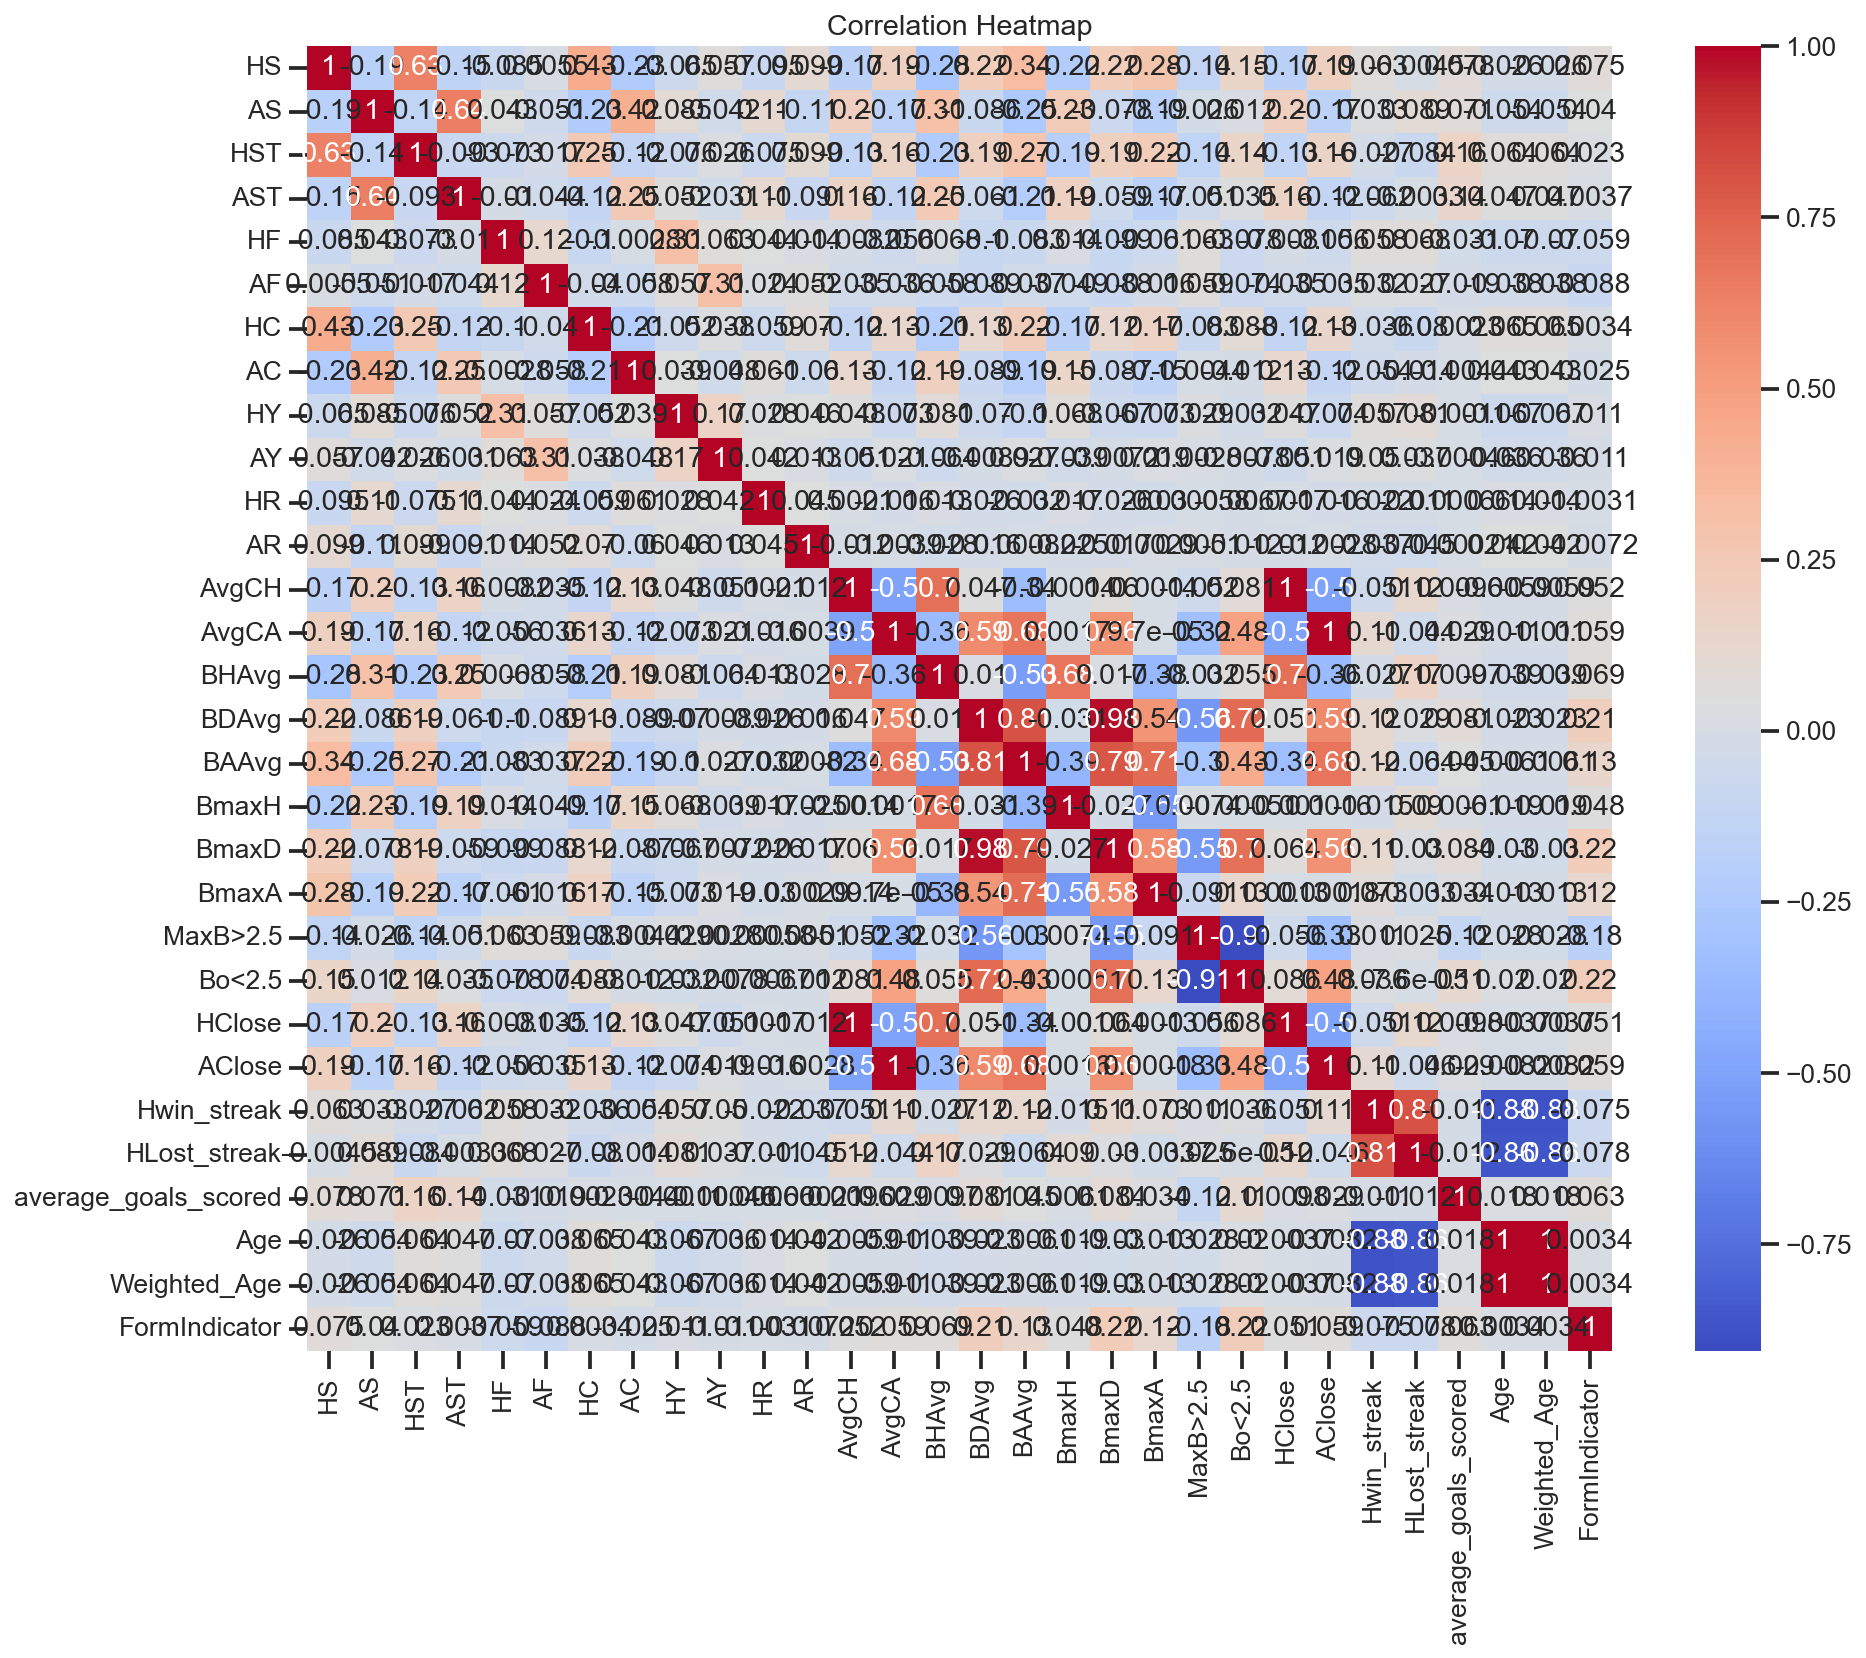

In [113]:
# Let's check the correlation with the aid of the heatmap
correlation_matrix = fb_df.drop(['FTHG', 'FTAG', 'HTHG', 'HTAG', 'goal_gap' ], axis=1).corr()

# Now creat the heat map
plt.figure(figsize=(15, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', square=True)
plt.title('Correlation Heatmap')
plt.show()

In [114]:
selected_columns = ['FTAG', 'FTHG', 'HomeTeam', 'AwayTeam', 'FTR']
subset_df = fb_df[selected_columns]
print(subset_df.head(1))


     FTAG  FTHG HomeTeam AwayTeam FTR
Div                                  
EC    1.0   1.0  Torquay  Wrexham   D


In [115]:
print(fb_df.columns)

Index(['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG',
       'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY',
       'HR', 'AR', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH',
       'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'HClose', 'AClose', 'goal_gap',
       'Hwin_streak', 'HLost_streak', 'average_goals_scored', 'Age',
       'Weighted_Age', 'FormIndicator'],
      dtype='object')


In [116]:
feature_headings = fb_df.columns.tolist()
print(feature_headings)

['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'HClose', 'AClose', 'goal_gap', 'Hwin_streak', 'HLost_streak', 'average_goals_scored', 'Age', 'Weighted_Age', 'FormIndicator']


In [117]:
fb_df = fb_df.drop(['Date'], axis=1)

### 4.2. SelectKBest

In [118]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

# One Hot Encode the target variable
y_encoded = pd.get_dummies(fb_df['FTR'])

# Split the data
X = fb_df.drop(columns=['FTR', 'HTR', 'HomeTeam', 'AwayTeam'])
y = y_encoded

# Handle missing values if any
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Scale the feature using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Initialize the SelectKBest with chi2 to avois negative classifiaction issues
kbest = SelectKBest(score_func=chi2, k=25)

# Fit and transform the scaled features using SelecKBest
X_new = kbest.fit_transform(X_scaled, y)

# Get the top 20 feature indices selected
top_20_feature_indices = kbest.get_support(indices=True)

# Get the top 2- feature names
top_20_feature_names = X.columns[top_20_feature_indices]

# print top_20_features selected
print("Top 20 Selected Feature Names:")
print(top_20_feature_names)

Top 20 Selected Feature Names:
Index(['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST', 'HY', 'HR',
       'AR', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD',
       'BmaxA', 'HClose', 'AClose', 'goal_gap', 'Hwin_streak', 'HLost_streak',
       'average_goals_scored'],
      dtype='object')


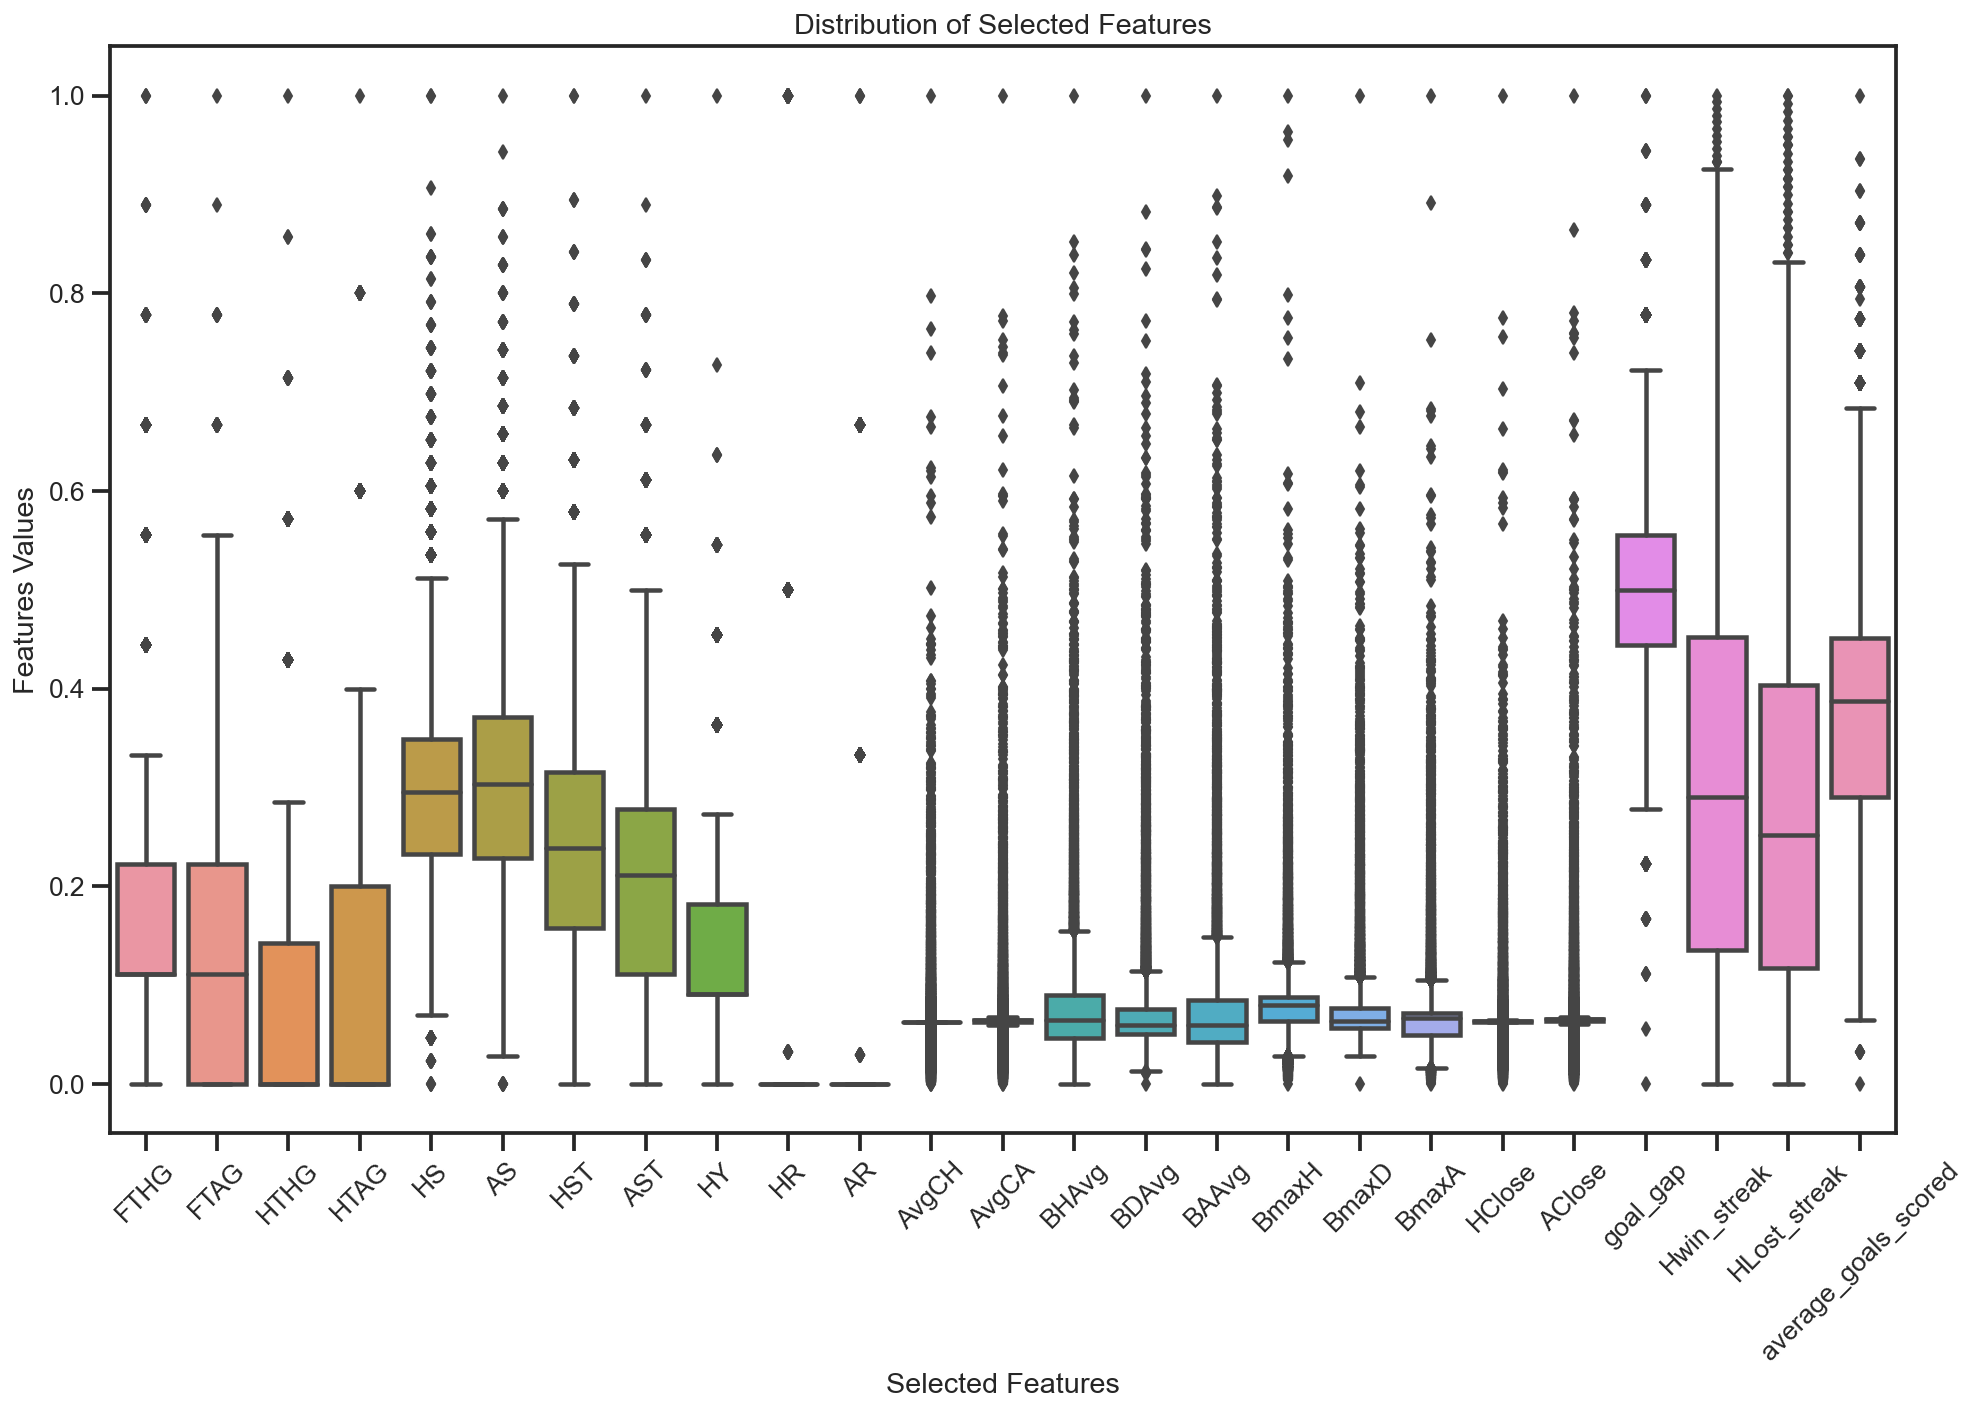

In [119]:
# Establish a data frame wiyth the selected features X_new
selected_features_df =pd.DataFrame(X_new, columns=top_20_feature_names)

# Let's creat a box plot to gain more visibility
plt.figure(figsize=(16,10))
sns.boxplot(data=selected_features_df)
plt.xlabel('Selected Features')
plt.ylabel('Features Values')
plt.title('Distribution of Selected Features')
plt.xticks(rotation=45)
plt.show()

In [120]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

# One Hot Encode the target variable
y_encoded = pd.get_dummies(fb_df['FTR'])

# Split the data
X = fb_df.drop(columns=['FTR', 'HTR', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'HTHG', 'HTAG'])
y = y_encoded


# Scale the feature using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Scale the feature using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Initialize the SelectKBest with chi2 to avois negative classifiaction issues
kbest = SelectKBest(score_func=chi2, k=20)

# Fit and transform the scaled features using SelecKBest
X_new_new = kbest.fit_transform(X_scaled, y)

# Get the top 20 feature indices selected
new_top_20_feature_indices = kbest.get_support(indices=True)

# Get the top 2- feature names
new_top_20_feature_names = X.columns[new_top_20_feature_indices]

# print top_20_features selected
print("New Top 20 Selected Feature Names:")
print(new_top_20_feature_names) 


New Top 20 Selected Feature Names:
Index(['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'BHAvg', 'BDAvg',
       'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'AClose',
       'HLost_streak', 'average_goals_scored', 'Age'],
      dtype='object')


In [121]:
# Accordingly, the tool selected the above features primarily

In [122]:
# # Select feature to be removed with outliers
# OLselected_features4 = ['HS', 'AS', 'HC', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'HClose', 'average_goals_scored']

# #Set the z-scores
# z_scores4 = ((fb_df[OLselected_features4] - fb_df[OLselected_features4].mean()) / fb_df[OLselected_features4].std()).abs()

# # Set the outlier thresould
# outlier_threshold4 = 7

# # Create boolean mask to indicate whether the rows should be removed or not
# outlier_mask4 = (z_scores4 > outlier_threshold4).any(axis=1)

# # Calculate the number of observations that would be removed
# num_rows_removes4 = outlier_mask4.sum()
# print("number of observations that would be removed4:", num_rows_removes1)

# # Removed the outliers from the data frame
# #fb_df = fb_df.loc[~outlier_mask4]

# # Display the shape of the data frame cleaned
# #print("Shape of 'fb_df' after removing outliers4:", fb_df.shape)

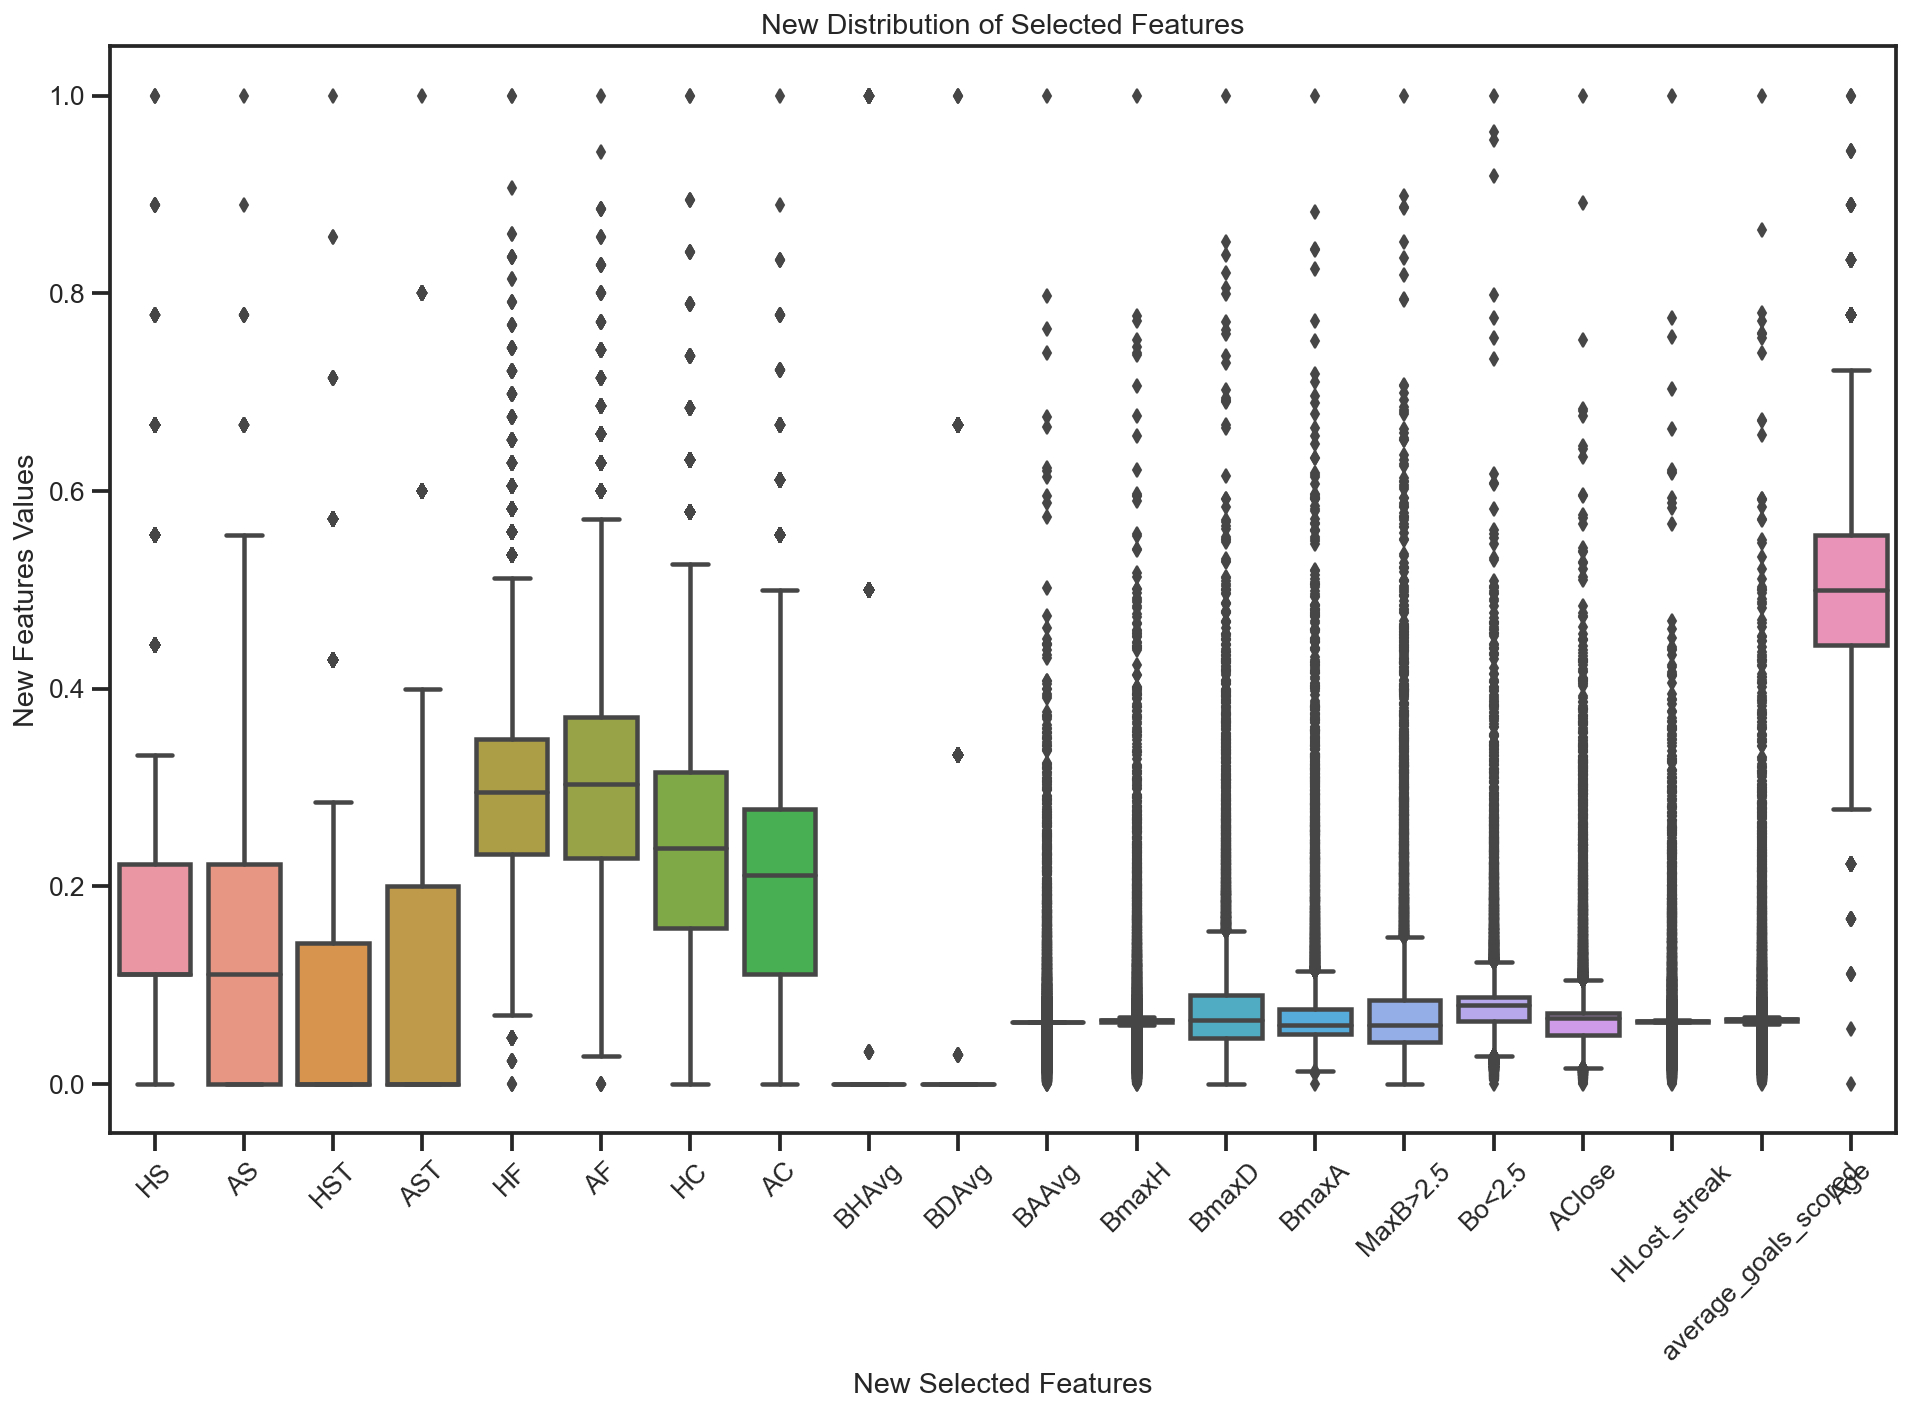

In [123]:
# Establish a data frame with the selected features X_new
new_selected_features_df =pd.DataFrame(X_new_new, columns=new_top_20_feature_names)

# Let's creat a box plot to gain more visibility
plt.figure(figsize=(16,10))
sns.boxplot(data=new_selected_features_df)
plt.xlabel('New Selected Features')
plt.ylabel('New Features Values')
plt.title('New Distribution of Selected Features')
plt.xticks(rotation=45)
plt.show()

In [124]:
# Let's check on best 10 fetures

# One Hot Encode the target variable
y_encoded = pd.get_dummies(fb_df['FTR'])

# Split the data
X = fb_df.drop(columns=['FTR', 'HTR', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'HTHG', 'HTAG'])
y = y_encoded


# Scale the feature using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Scale the feature using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Initialize the SelectKBest with chi2 to avois negative classifiaction issues
kbest = SelectKBest(score_func=chi2, k=10)

# Fit and transform the scaled features using SelecKBest
X_new_new = kbest.fit_transform(X_scaled, y)

# Get the top 20 feature indices selected
new_top_10_feature_indices = kbest.get_support(indices=True)

# Get the top 2- feature names
new_top_10_feature_names = X.columns[new_top_10_feature_indices]

# print top_10_features selected
print("New Top 10 Selected Feature Names:")
print(new_top_10_feature_names) 


New Top 10 Selected Feature Names:
Index(['HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'BHAvg', 'BDAvg', 'MaxB>2.5',
       'Age'],
      dtype='object')


### 4.3. Principle Component Analysis 

In [125]:
# Split the data
# X = fb_df.drop(columns=['FTR', 'HTR', 'HomeTeam', 'AwayTeam'])
# y = y_encoded

In [126]:
# Create the data frame with needed features to apply pca
selected_features_df = X[['HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'MaxB>2.5', 'Bo<2.5', 'HClose', 'AClose', 'goal_gap', 'Hwin_streak', 'HLost_streak', 'average_goals_scored', 'Age', 'average_goals_scored', 'FormIndicator']]

# Initiate the PCA with the desired n componets
n_components = 10
pca = PCA(n_components = n_components)

# Fit and transform the data using pca
pca_results = pca.fit_transform(selected_features_df)

# Create a new dataframe to store pca results gathered
pca_df = pd.DataFrame(data=pca_results, columns=[f"PC{i+1}" for i in range(n_components)])

# Reset the index of the data frames
pca_df.reset_index(drop=True, inplace=True)
y_encoded.reset_index(drop=True, inplace=True)

# Convert y_encoded to a pandas Series 
# y_encoded_series = pd.Series(y_encoded, name= 'Traget')
                                                
# Concatenate the PCA results with the encoded target variable (y_encoded)
new_df = pd.concat([pca_df, y_encoded], axis=1)  
                                                
# Print the new data frame
print(new_df)

             PC1        PC2        PC3        PC4       PC5       PC6  \
0      48.278472 -20.147435   5.014671  -3.752919 -1.385801  0.058082   
1      68.037080  22.324624   8.500066  15.296915  2.632389  1.046336   
2      60.226217   1.711378  -1.704181   7.887853  0.227384 -0.617860   
3      51.903442  -9.345940  -3.049383   4.250364  7.016374 -3.938427   
4      72.522588  -3.078842  -9.716996   2.241886 -3.578629  3.560607   
...          ...        ...        ...        ...       ...       ...   
25393 -50.284624   0.910898  -2.842631   6.425929  7.348318 -4.114665   
25394 -52.526502  -0.138733 -10.781674   3.438919 -3.467752  1.189621   
25395 -53.589146   1.848403  -6.672797   3.593832  7.693655 -1.447447   
25396 -53.046699   1.638664  -3.029440   7.930891  1.704802 -1.119756   
25397 -54.761174   0.685052   5.259994  -2.023364 -1.815390  9.223880   

            PC7       PC8       PC9      PC10  A  D  H  
0      0.309314  0.286294  0.213641 -2.434161  0  1  0  
1      5.

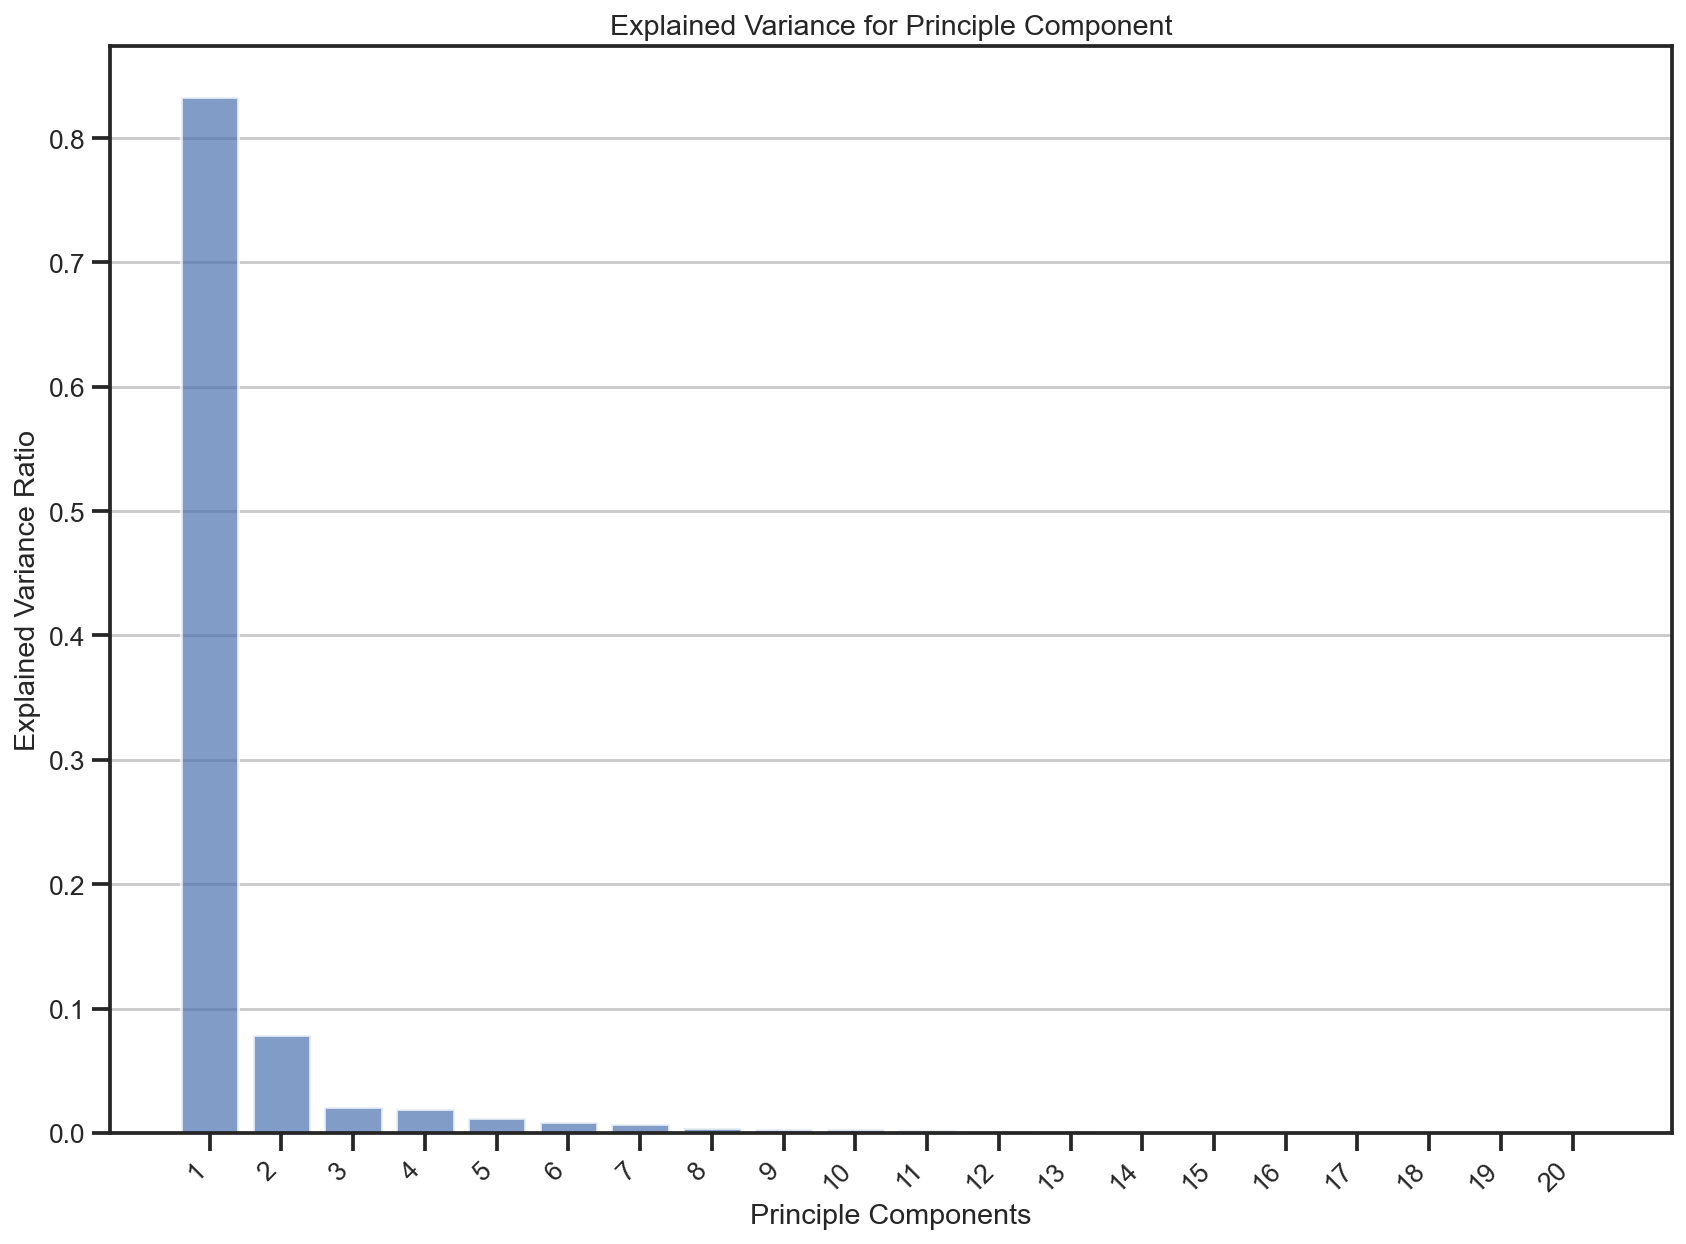

In [127]:
# Initialize the pca with desired no of componets
n_components = 20
pca = PCA(n_components = n_components)

# Fit PCA on the selected features
pca.fit(selected_features_df)

# Get the explained variance ratio for each principal componets
explained_variance = pca.explained_variance_ratio_

# Get the cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# plot the xplained variance for each componets
plt.figure(figsize=(14,10))
plt.bar(range(1, n_components + 1), explained_variance[:n_components], alpha=0.7)
plt.xlabel('Principle Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance for Principle Component')
plt.xticks(range(1, n_components +1), range(1, n_components +1), rotation=45, ha='right')
plt.grid(axis='y')
#plt.tight_layout()
plt.show()

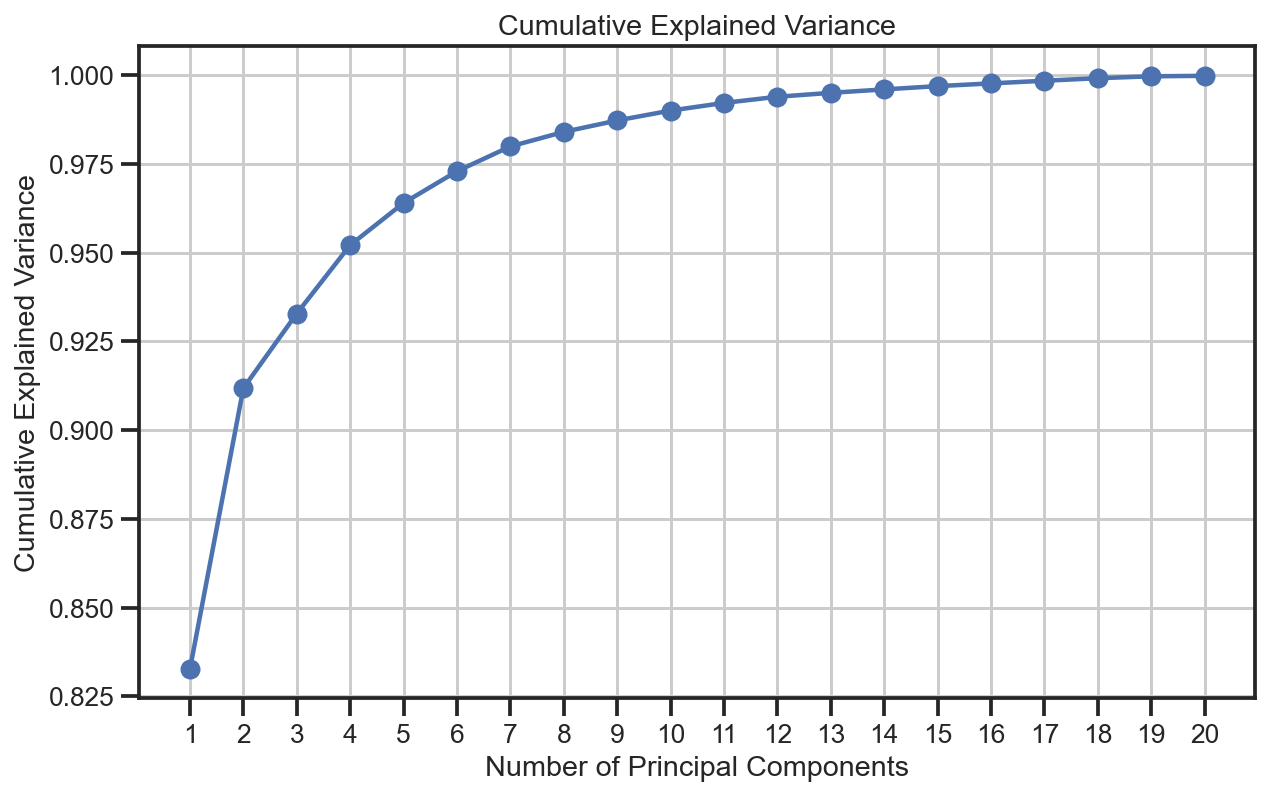

In [128]:
# Plot the cumulative explained variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, n_components + 1), cumulative_variance, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.xticks(range(1, n_components + 1))
plt.grid()
plt.show()

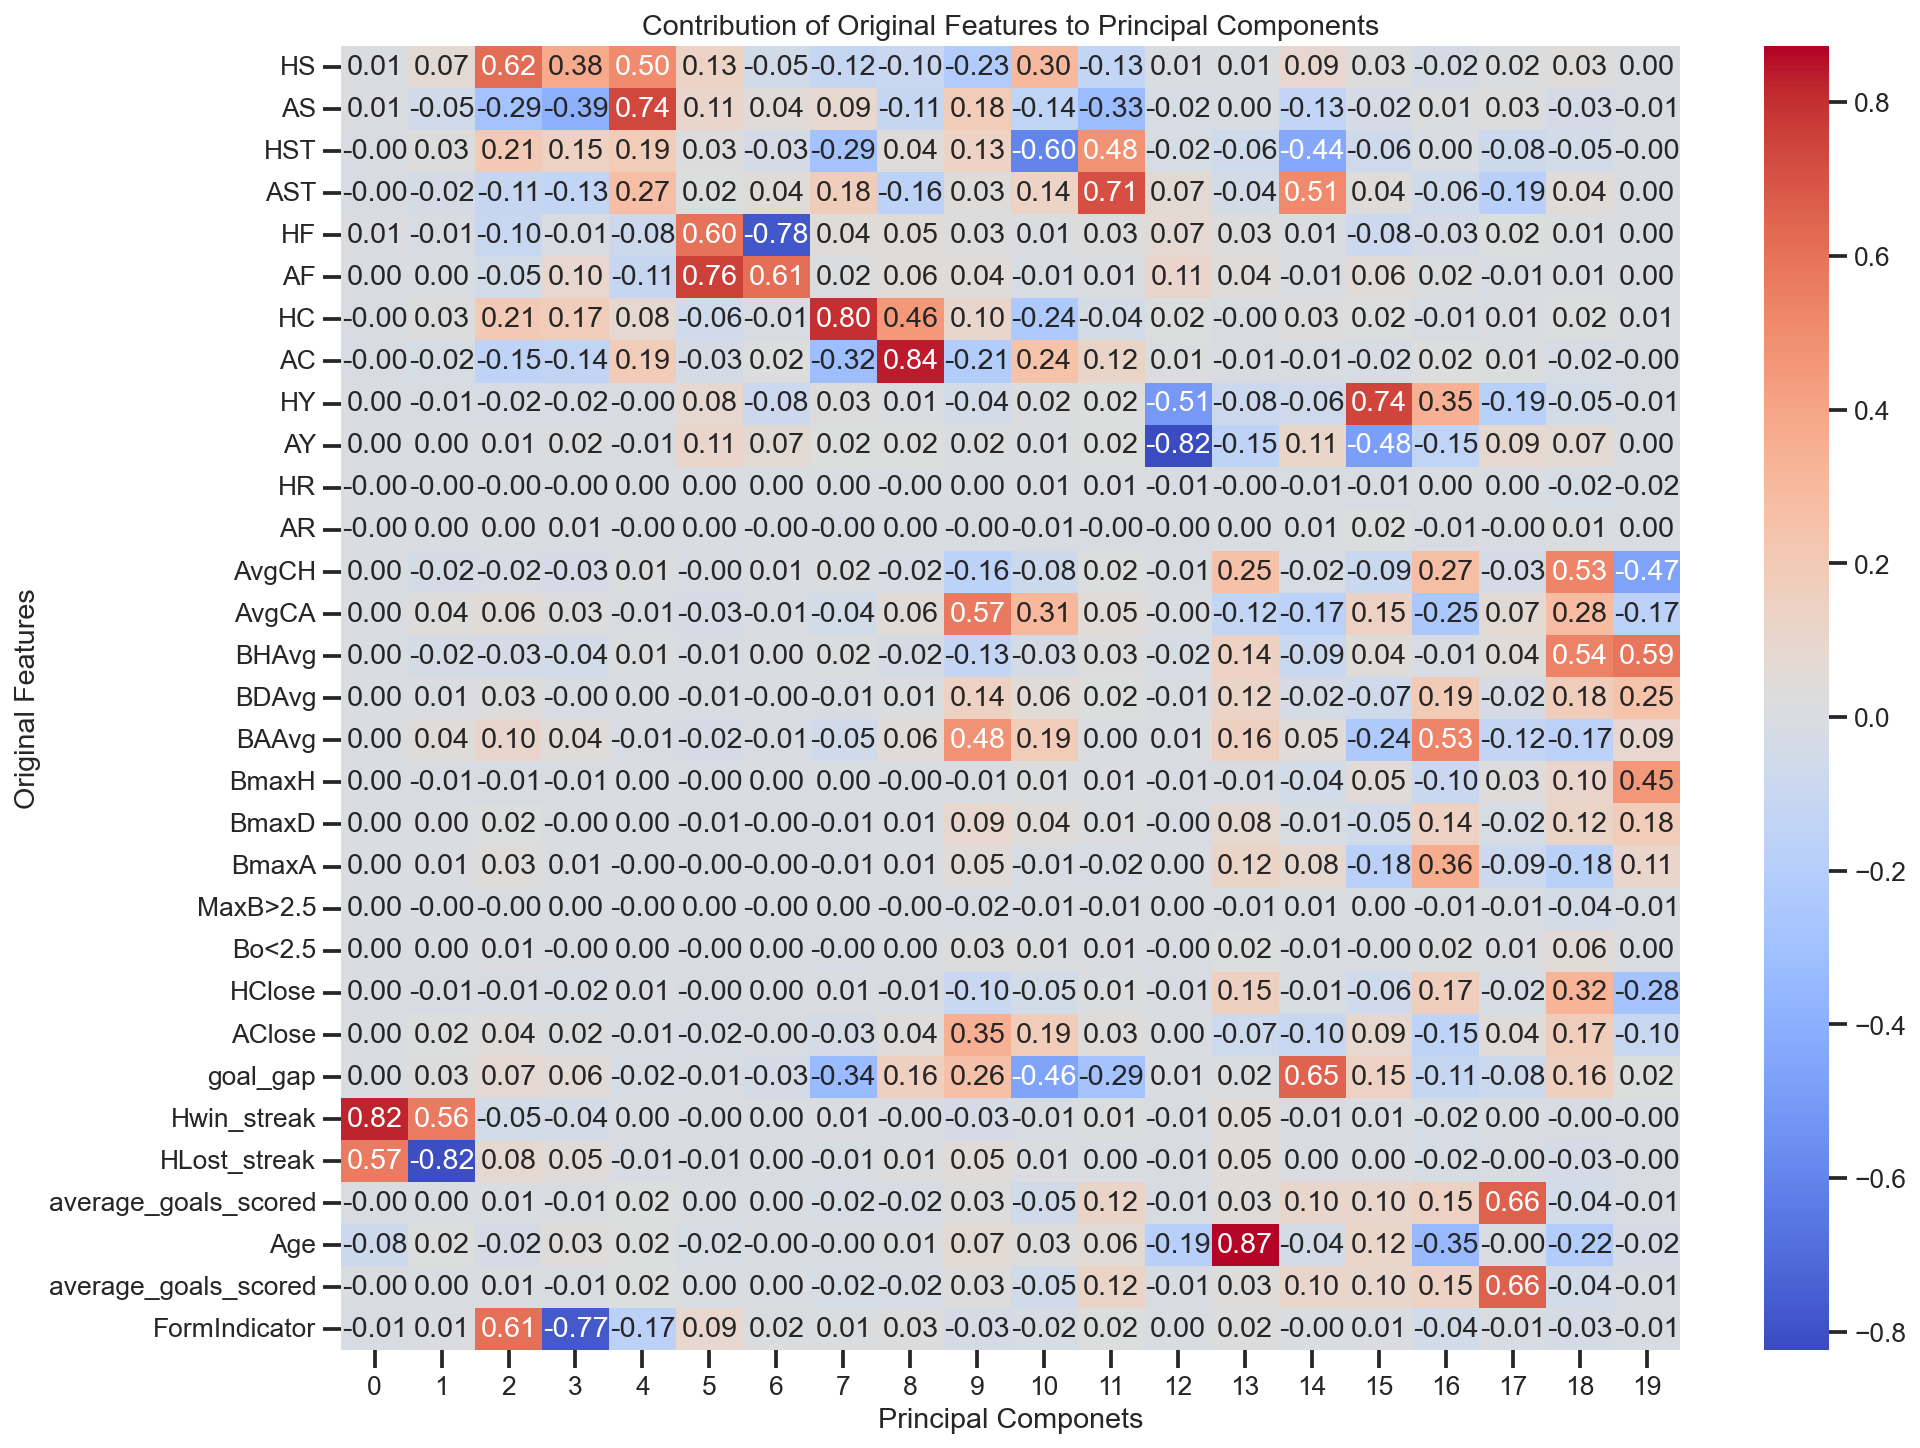

In [129]:
# get the feature loadinng from the pca results to match the PCA componets with original features to identify individual importance
feature_loadings = pca.components_[:n_components]

# Create a data frame to store the feature loading with original features
feature_loadings_df = pd.DataFrame(feature_loadings, columns=selected_features_df.columns)

# Plot the feature loadings for the first few principle componets
plt.figure(figsize=(15,12))
sns.heatmap(feature_loadings_df.iloc[:n_components].T, cmap='coolwarm', annot=True, fmt=".2f")
plt.title("Contribution of Original Features to Principal Components")
plt.xlabel("Principal Componets")
plt.ylabel("Original Features")
plt.show()

It is evident that the prediction could be done team wise. Hence, required to find a interested team firt to make the predictions. hence, the slicing of the data frame to be done  appropriately. I'm Interested with the Man City team prediction where we are living.

In [130]:
# Establish the different data frames inview of executing the onwards manipulations, with the selected data.
num_data = fb_df[['HS', 'AS', 'HST', 'AST', 'HY','HF', 'AF', 'HC', 'AC', 'Age', 'AvgCH', 'AvgCA', 'BHAvg', 'BDAvg', 'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'HClose', 'AClose',
       'HLost_streak','Hwin_streak', 'average_goals_scored', 'FormIndicator']]
cat_data = fb_df[['HomeTeam','AwayTeam']]

##################################################

# Lets apply the simple imputer to remove any missing values befor proceeding for the numerical data.

# Creat the instances of the simple imputer
num_imputer = SimpleImputer(strategy= 'mean')
cat_imputer = SimpleImputer(strategy= 'constant', fill_value = 'Unknown')

# Fill missing values in numerical & categorical features if any
num_imputed = num_imputer.fit_transform(num_data)
cat_imputed = cat_imputer.fit_transform(cat_data)

# Get num_imputed into a data frame
# num_imputed_df = pd.DataFrame(num_imputed, columns)

# Create an instance of standard scaler & scale the numerical data
scaler = StandardScaler()
num_scaled = pd.DataFrame(scaler.fit_transform(num_imputed), columns=num_data.columns)
###################################################
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_teams = encoder.fit_transform(cat_imputed[:,[0,1]]) # Column indices of Home and Away Team.
encoded_team_columns = encoder.get_feature_names_out(['HomeTeam', 'AwayTeam'])
encoded_teams_df= pd.DataFrame(encoded_teams, columns = encoded_team_columns)

# Rest the index of the encoded_team_df
encoded_teams_df.reset_index(drop=True, inplace=True)

# Combined encoded numerical and categorical data
encoded_data = pd.concat([encoded_teams_df, num_scaled], axis=1)

# Print the first few rows of the combined encoded data
print("Encoded Data:")
print(encoded_data.head())

##################################################
# Impute the target
ftr_data = fb_df[['FTR']]
ftr_imputer = SimpleImputer(strategy= 'most_frequent')
ftr_imputed = ftr_imputer.fit_transform(ftr_data)
fb_df_imputed = fb_df.copy()
fb_df_imputed['FTR'] = ftr_imputed

Encoded Data:
   HomeTeam_AFC Wimbledon  HomeTeam_Accrington  HomeTeam_Aldershot  \
0                     0.0                  0.0                 0.0   
1                     0.0                  0.0                 0.0   
2                     0.0                  0.0                 0.0   
3                     0.0                  0.0                 0.0   
4                     0.0                  0.0                 0.0   

   HomeTeam_Alfreton Town  HomeTeam_Altrincham  HomeTeam_Arsenal  \
0                     0.0                  0.0               0.0   
1                     0.0                  0.0               0.0   
2                     0.0                  0.0               0.0   
3                     0.0                  0.0               0.0   
4                     0.0                  0.0               0.0   

   HomeTeam_Aston Villa  HomeTeam_Barnet  HomeTeam_Barnsley  HomeTeam_Barrow  \
0                   0.0              0.0                0.0              0.0

### 4.6. Clustering

In [131]:
# Define features (X) and target (y)
X = encoded_data
y = fb_df_imputed['FTR']

In [132]:
pip install --upgrade scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [133]:
pip install --upgrade threadpoolctl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


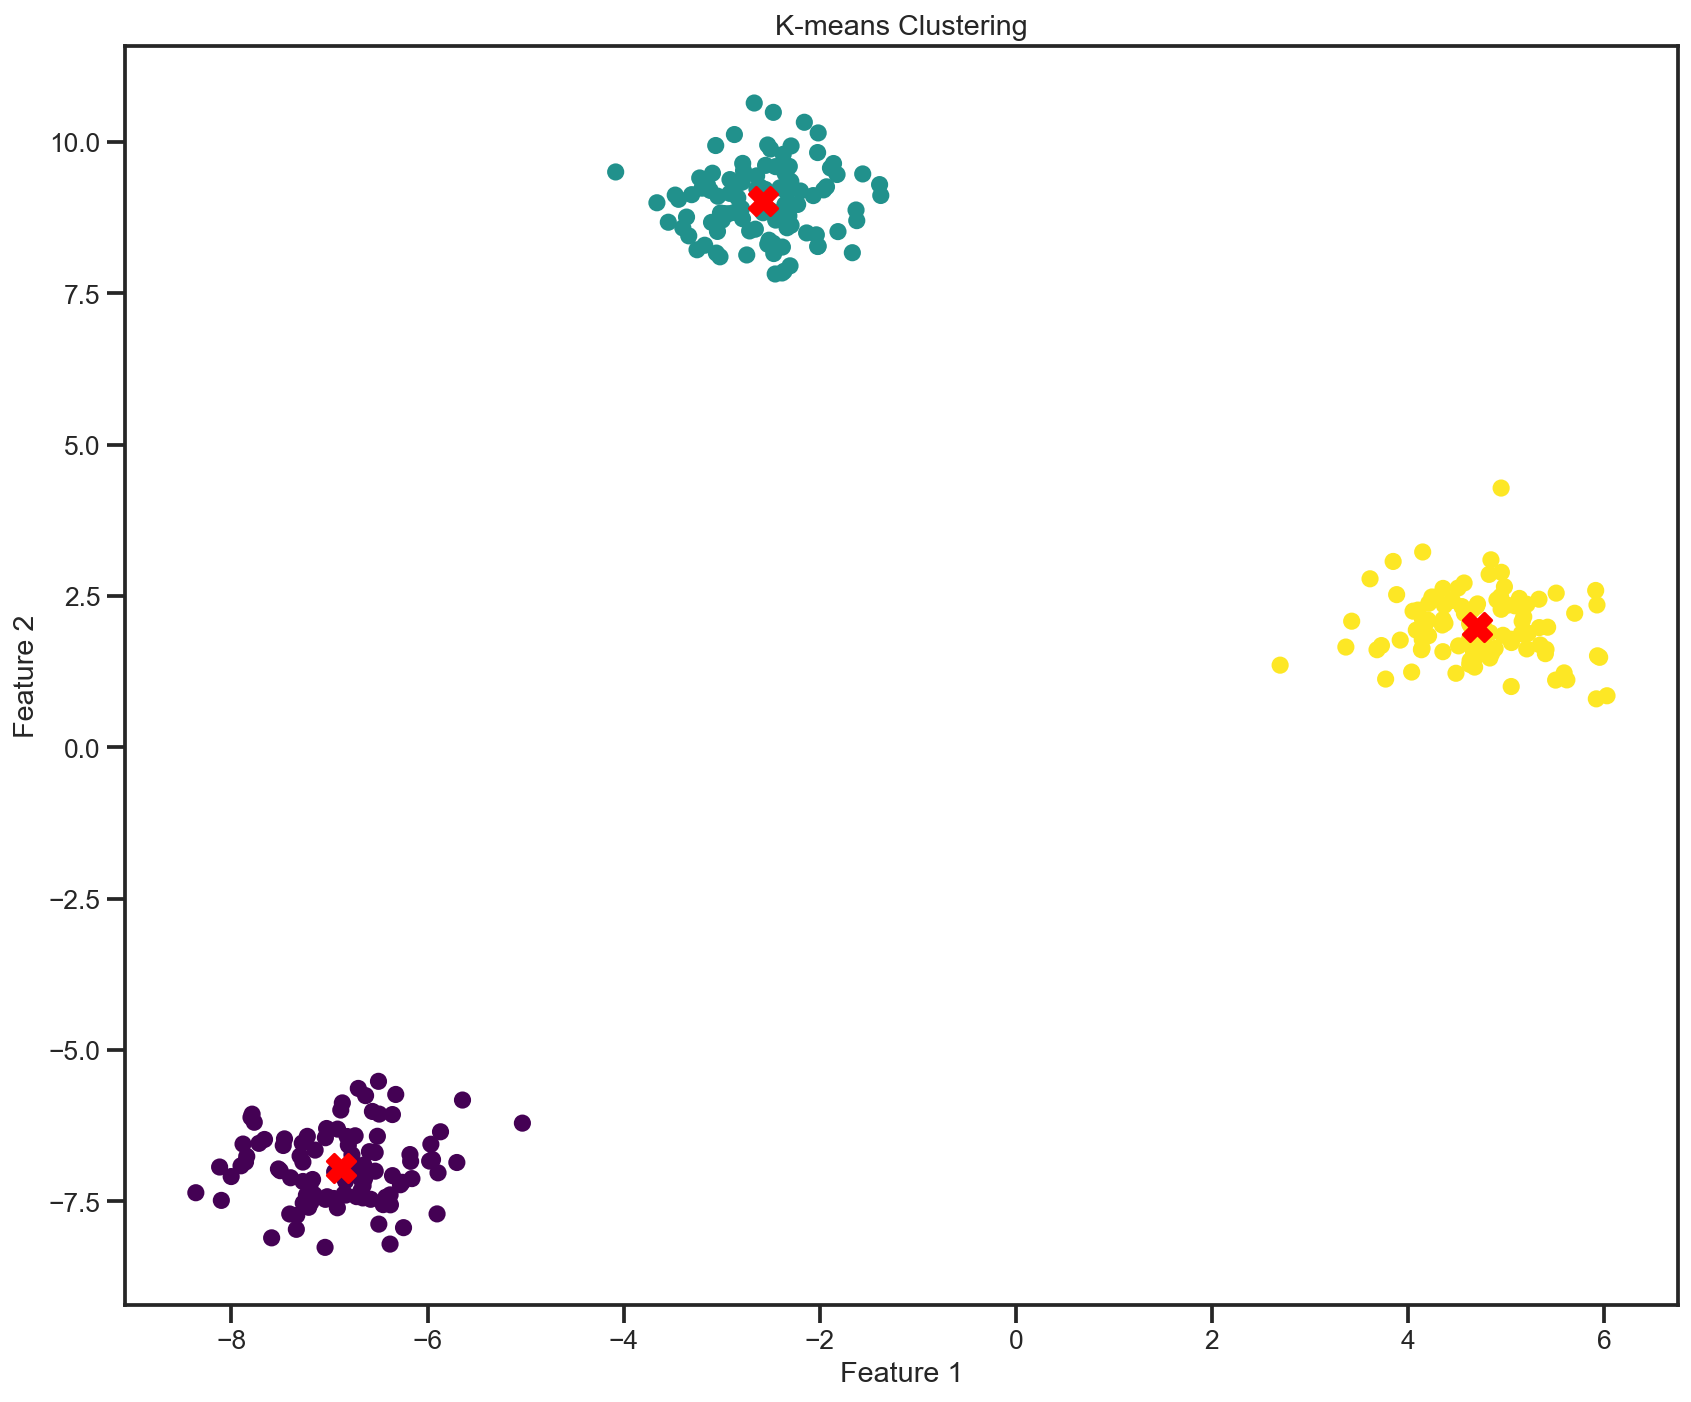

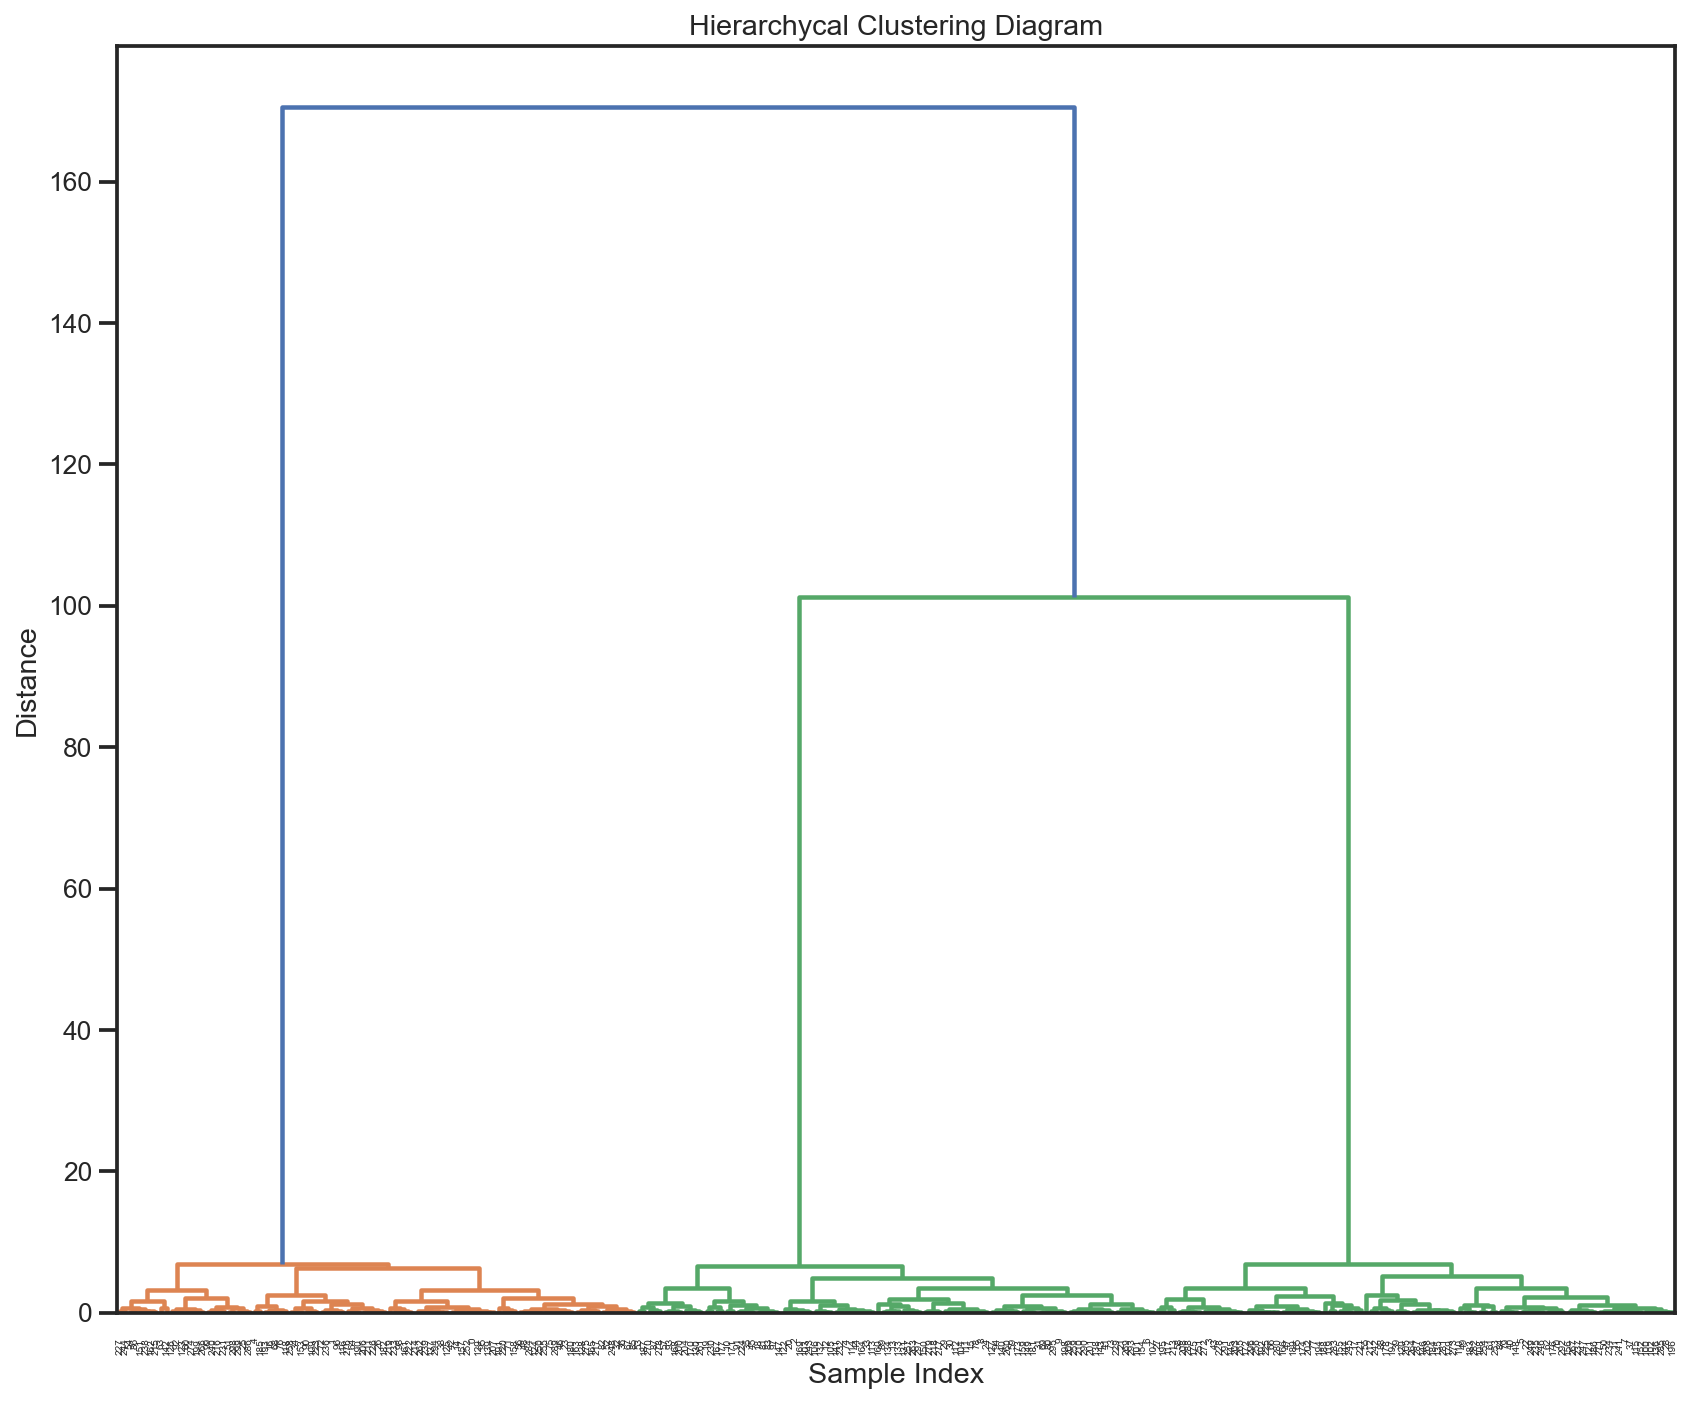

In [134]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

# Create sample data for clustering demonstration
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)

# Get the scatter plots for the k-means clustering
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)
y_means = kmeans.predict(X)

# Scatter plot for K-means Clustering
plt.figure(figsize=(12,10))
plt.scatter(X[:, 0], X[:, 1], c=y_means, s=50, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200)
plt.title('K-means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')


plt.tight_layout()
plt.show()

# Dendrogram for hierarchycal clustering
plt.figure(figsize=(12,10))

linked = linkage(X, method='ward')
dendrogram (linked)
plt.title('Hierarchycal Clustering Diagram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')

plt.tight_layout()
plt.show()

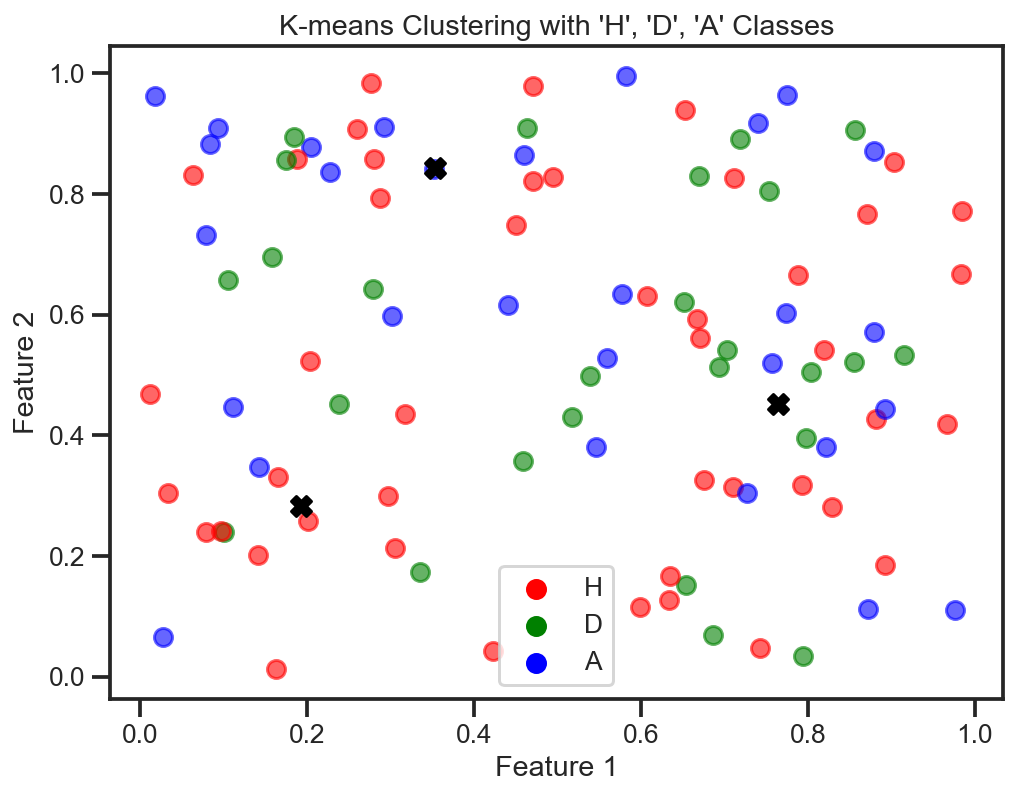

In [135]:
# Set the OMP_NUM_THREDS environment variable to 1
os.environ['OMP_NUM_THREADS']= '1'

# Simulate the data representing features
X = np.random.rand(100,2)

# Label classes (H, D, A)
labels= np.random.choice(['H', 'D', 'A'], size=100)

# Crea a dictionary to map class labels to coluors
class_colors = {'H':'red', 'D': 'green', 'A': 'blue'}

# Transform class labels into numerical values
class_labels = np.array([0 if label == 'H' else 1 if label == 'D' else 2 for label in labels])

# Get the scatter plots for the k-means clustering
kmeans = KMeans(n_clusters=3, n_init=10)
kmeans.fit(X)
cluster_labels = kmeans.labels_ 

# Plot k-means clustering
plt.figure(figsize=(8,6))

# Create custom legend for 'H', 'D', 'A'  
for label, color in class_colors.items():
    plt.scatter([], [], c=color, label=label)

# Scatter plot for data points
for i in range(X.shape[0]):
    plt.scatter(X[i, 0], X[i, 1], color=class_colors[labels[i]], alpha=0.6)


plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='black', marker='X', s=100)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title("K-means Clustering with 'H', 'D', 'A' Classes")

plt.legend()
plt.show()

In [136]:
# # Jut visalize the cluster
# plt.scatter(X_train[:, 0], X_train[:, 1], c=cluster_labels, cmap='viridis')
# plt.xlabel('Feature 1')
# plt.ylabel('Feature 2')
# plt.title('Clustering Visualization')
# plt.show()

In [137]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Assuming X_train contains your feature data, cluster_labels contains cluster assignments,
# # and y_train contains the 'FTR' labels

# # Create a DataFrame combining the feature data, cluster assignments, and 'FTR' labels
# clustered_data = pd.DataFrame({'Cluster': cluster_labels, 'FTR': y_train})

# # Create a scatter plot with seaborn
# sns.scatterplot(data=clustered_data, x='Feature1', y='Feature2', hue='Cluster', palette='viridis')

# plt.xlabel('Feature 1')
# plt.ylabel('Feature 2')
# plt.title('Clustering Visualization')

# # Add a legend to the plot
# plt.legend(title='Cluster')

# plt.show()


### 4.7 Resampling

Handling Sampling Inbalance to Improve Draw Accuracy

During the priliminary process, below observations were made and push to apply resampling technique as figures improves.

According to the categorization depicted, the model performs differently for classes A, D, and H. How effectively the model predicts each class is shown by its precision, recall, and F1-score.

Precision: The precision gauges how accurately the model's optimistic predictions came true. The precision for class A is 0.53, indicates that 53% of examples expected to be class A were accurate. Class D has a precision of 0.47, whereas class H has a precision of 0.57.

Recall: It is often referred to as sensitivity or true positive rate, quantifies the percentage of real positive events that the model accurately detected. The recall for class A is 0.58, which indicates that 58% of all real instances of class A were correctly identified by the model. Recalls for classes D and H are 0.09 and 0.82, respectively.

F1-score: The harmonic mean of recall and precision, the F1-score strikes a balance between the two metrics. When there is an imbalance in the classrooms, it is especially helpful. Class A has an F1 value of 0.55, Class D has an F1 score of 0.16, and Class H has an F1 score of 0.67.

The model looks to be working reasonably well for class H (Home team wins) with a high recall and F1-score based on the classification report. It struggles with class D (Draw), too, and does poorly in terms of recall and F1-score.

Treating Class Imbalance: If the dataset is unbalanced (that is, some classes have noticeably fewer samples than others), you can treat class imbalance by using methods like class weighting, oversampling, or undersampling.

In [138]:
pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [139]:
# Define features (X) and target (y)
X = encoded_data
y = fb_df_imputed['FTR']

In [140]:
# from imblearn.under_sampling import RandomUnderSampler

# # Create the RandomUnderSample Instance
# under_sampler = RandomUnderSampler(sampling_strategy = 'auto', random_state=42)

# # Apply under-sampling on the training data
# X_Usampled, y_Usampled = under_sampler.fit_resample(X, y)

# # Get the value counts
# X_value_counts()
# y_value_counts()
# X_Usampled_counts()
# y_Usampled_counts() 

In [141]:
# from imblearn.over_sampling import RandomOverSampler

# # Create the RandomUnderSample Instance
# over_sampler = RandomOverSampler(sampling_strategy = 'auto', random_state=42)

# # Apply over-sampling on the training data
# X_Osampled, y_Osampled = over_sampler.fit_resample(X, y)

# # Get the value counts
# X_value_counts()
# y_value_counts()
# X_Osampled_counts()
# y_Osampled_counts() 

In [142]:
# Get the value counts
X.value_counts()
y.value_counts()

H    10912
A     7887
D     6599
Name: FTR, dtype: int64

In [143]:
# from imblearn.combine import SMOTEENN

# # Create the SMOTEENN Instance
# smote_enn = SMOTEENN(sampling_strategy = 'auto', random_state=42)

# # Apply over-sampling on the training data
# X_resampled, y_resampled = smote_enn.fit_resample(X, y)

# # Get the value counts

# # X_resampled.value_counts()
# # y_resampled.value_counts()

# # # Convert y_resampled to pandas series
# # y_resampled_series= pd.Series(y_resampled)
# # y_resampled_value_counts = y_resampled_series.value_counts()

# # print(y_resampled_value_counts)

In [144]:
# D    10912
# H    10912
# A    10912
# Name: FTR, dtype: int64

In [145]:
from imblearn.over_sampling import SMOTE

# Create the SMOTEENN Instance
smote = SMOTE(sampling_strategy = 'auto', random_state=42)

# Apply over-sampling on the training data
X_resampled, y_resampled = smote.fit_resample(X, y)

# Get the value counts

# X_resampled.value_counts()
# y_resampled.value_counts()

# Convert y_resampled to pandas series
y_resampled_series= pd.Series(y_resampled)
y_resampled_value_counts = y_resampled_series.value_counts()

print(y_resampled_value_counts)

D    10912
H    10912
A    10912
Name: FTR, dtype: int64


### 4.8. Split the data into features (X) and target variable (y)

In [146]:
X = X_resampled
y = y_resampled

In [147]:
# Let's split the data into 70% training, 20% validation and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.33, stratify=y_temp, random_state=42)

# Print the shape of the training, validation, and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Validationg set shape:", X_val.shape, y_val.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (22915, 304) (22915,)
Validationg set shape: (6580, 304) (6580,)
Testing set shape: (3241, 304) (3241,)


In [148]:
# Value count of observations of Home Teams
home_team_counts = cat_data['HomeTeam']. value_counts()

# Value count of observations of AwayTeams
away_team_counts = cat_data['AwayTeam']. value_counts()

# Get the comined count of both teams
team_counts = home_team_counts.add(away_team_counts, fill_value=0)

# Display the value counts for each team
print(team_counts)

AFC Wimbledon    449
Accrington       449
Aldershot        448
Alfreton Town     92
Altrincham       225
                ... 
Wolves           419
Wrexham          446
Wycombe          448
Yeovil           446
York             230
Length: 140, dtype: int64


In [149]:
all_teams = team_counts.index.tolist()

# Display total list of teams and the number of matches they played as home and away teams
for team in all_teams:
    home_matches = home_team_counts.get(team, 0)
    away_matches = away_team_counts.get(team, 0)
    total_matches = home_matches + away_matches
    print(f"{team}: Home Matches - ({home_matches}, Away Matches- {away_matches}, Total Matches-{total_matches}")

AFC Wimbledon: Home Matches - (225, Away Matches- 224, Total Matches-449
Accrington: Home Matches - (224, Away Matches- 225, Total Matches-449
Aldershot: Home Matches - (223, Away Matches- 225, Total Matches-448
Alfreton Town: Home Matches - (46, Away Matches- 46, Total Matches-92
Altrincham: Home Matches - (112, Away Matches- 113, Total Matches-225
Arsenal: Home Matches - (189, Away Matches- 190, Total Matches-379
Aston Villa: Home Matches - (201, Away Matches- 202, Total Matches-403
Barnet: Home Matches - (220, Away Matches- 224, Total Matches-444
Barnsley: Home Matches - (244, Away Matches- 244, Total Matches-488
Barrow: Home Matches - (180, Away Matches- 179, Total Matches-359
Birmingham: Home Matches - (230, Away Matches- 230, Total Matches-460
Blackburn: Home Matches - (230, Away Matches- 230, Total Matches-460
Blackpool: Home Matches - (224, Away Matches- 225, Total Matches-449
Bolton: Home Matches - (224, Away Matches- 224, Total Matches-448
Boreham Wood: Home Matches - (176, A

## 5. Design Model and Execution

The empherical evidence claim a few important models, and the Random Forest, k_NearestNeighbors(k_NN), Multilayer Peceptron and the Gradient Boost, classifiers were selected, along with Voting Encemble models , considering the classification target and have the diversity in terms of algorithms architecture.

### 5.1. Random Forest Classifier

In [150]:
# Build and train the Random Forest Classifier (base Model)
rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [151]:
# Make prediction on the validation data
rfc_y_pred2 = rf_classifier.predict(X_val)

# Calculate accuracy on validation data
rfc_accuracy = accuracy_score(y_val, rfc_y_pred2)
print(f"Accuracy: {rfc_accuracy:.2f}")

# Generate a classification report for the validation data
print("RFC Base Classification Report for validation data:")
print(classification_report(y_val, rfc_y_pred2))

Accuracy: 0.65
RFC Base Classification Report for validation data:
              precision    recall  f1-score   support

           A       0.66      0.70      0.68      2193
           D       0.67      0.58      0.62      2193
           H       0.64      0.68      0.66      2194

    accuracy                           0.65      6580
   macro avg       0.65      0.65      0.65      6580
weighted avg       0.65      0.65      0.65      6580



In [152]:
# Hyperparameter tuning
# Accuracy=0.55; max_features = 'sqrt', class_weight= None, min_samples_split= 5, min_samples_leaf= 4 ,max_depth = 40, n_estimators=50.
# Accuracy=0.55; max_features = 'sqrt', class_weight= None, min_samples_split= 5, min_samples_leaf= 4 ,max_depth = 10, n_estimators=50.
# Accuracy=0.54; max_features = 'sqrt', class_weight= None, min_samples_split= 5, min_samples_leaf= 4 ,max_depth = 40, n_estimators=80.
# Accuracy=0.55; max_features = 'sqrt', class_weight= None, min_samples_split= 5, min_samples_leaf= 4 ,max_depth = 40, n_estimators=30.
# Accuracy=0.54; max_features = 'sqrt', class_weight= None, min_samples_split= 10, min_samples_leaf= 4 ,max_depth = 40, n_estimators=50.
# Accuracy=0.55; class_weight= None, min_samples_split= 10, min_samples_leaf= 4 ,max_depth = 40, n_estimators=50.
# Accuracy=0.55; max_features = 'sqrt', min_samples_split= 10, min_samples_leaf= 4 ,max_depth = 40, n_estimators=50.

In [153]:
# For tuning hyper parameters, define the grid
rf_param_grid = {
    'n_estimators': [200],   # Number of trees in the forest
    'max_depth' : [40],    # The max depth of trees
    #'min_samples_split': [5,10],  # Max no of samples required to split internal node
    #'min_samples_leaf' : [4, 8],   # Max no of samples required to be at a leaf node
    #'max_features': ['sqrt', None], # No of features in looking fo the best split
    'class_weight' : ['balanced']       # weight to address class imbalance
}

In [154]:
# # Build and train the Random Forest Classifier
# rf_classifier = RandomForestClassifier(max_features = 'sqrt', min_samples_split= 3, min_samples_leaf= 4 , max_depth = 40, n_estimators=50, random_state=42)
# #rf_classifier.fit(X_train, y_train)

In [155]:
# Let's creats the object of gridsearch  & Perform the Grid Search using training data
rf_grid_search = GridSearchCV(rf_classifier, rf_param_grid, cv=2, scoring= 'accuracy')
rf_grid_search.fit(X_train, y_train)

GridSearchCV(cv=2, estimator=RandomForestClassifier(random_state=42),
             param_grid={'class_weight': ['balanced'], 'max_depth': [40],
                         'n_estimators': [200]},
             scoring='accuracy')

In [156]:
# Get the best hyperparameter and correspnding accuracy for the best model
rfc_best_params_ = rf_grid_search.best_params_
rfc_best_accuracy_ = rf_grid_search.best_score_
print("Best RFC Hyperparameters:", rfc_best_params_)
print("Best RFC Accuracy on Training data:", rfc_best_accuracy_)

Best RFC Hyperparameters: {'class_weight': 'balanced', 'max_depth': 40, 'n_estimators': 200}
Best RFC Accuracy on Training data: 0.6104734577686513


In [157]:
# Get the best RF model
best_rf_model= rf_grid_search.best_estimator_

In [158]:
# Train the best model on the combined training data
# Let's concatenate X_train and X_val and y_train and y_val
# X_train = pd.concat([X_train, X_val], axis=0)
# y_train = pd.concat([y_train, y_val], axis=0)

best_rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=40, n_estimators=200,
                       random_state=42)

In [159]:
# Make predictions on Validation data on best model(Check X-val)
rfc_best_pred2 = best_rf_model.predict(X_val)

# Calculate the accuracy on the Validation data
accuracy_rfc = accuracy_score(y_val, rfc_best_pred2)
print(f"Accuracy: {accuracy_rfc: 2f}")

Accuracy:  0.654863


In [160]:
# Generate a classification report for validation data
print(" RFC Classification Report for Validation data:")
print(classification_report(y_val, rfc_best_pred2))

 RFC Classification Report for Validation data:
              precision    recall  f1-score   support

           A       0.65      0.71      0.68      2193
           D       0.68      0.57      0.62      2193
           H       0.64      0.69      0.66      2194

    accuracy                           0.65      6580
   macro avg       0.66      0.65      0.65      6580
weighted avg       0.66      0.65      0.65      6580



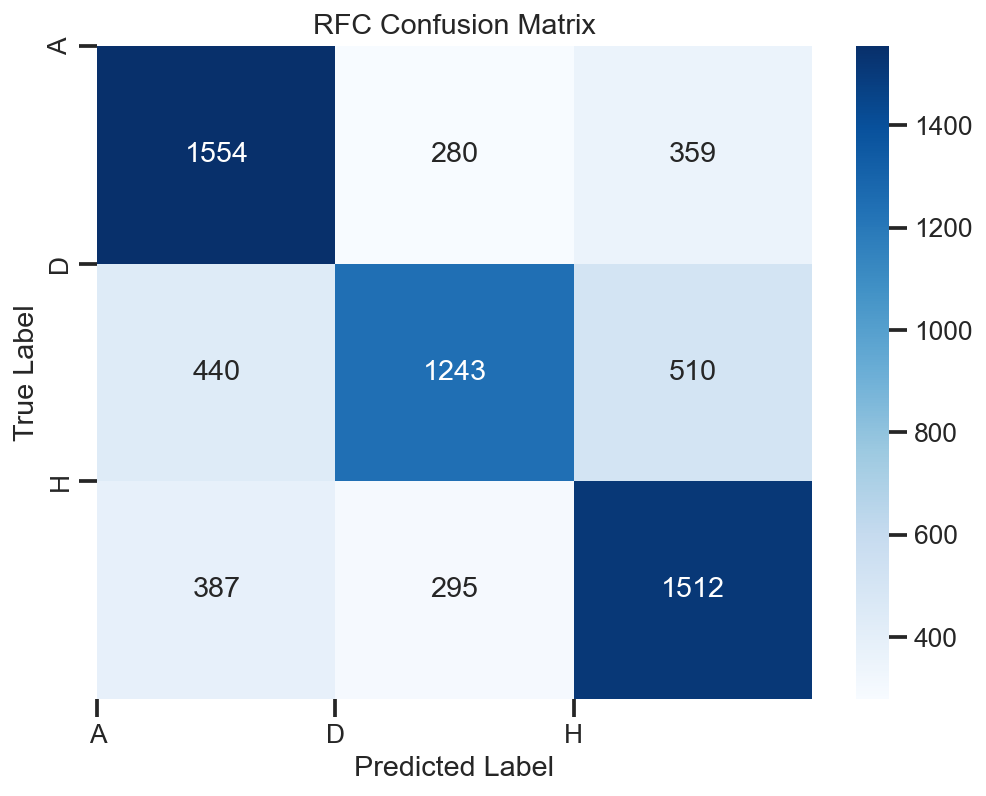

In [161]:
# Assuming you have the y_test and y_pred data

# Define the class names explicitly
class_names = ['A', 'D', 'H']

# Label encode the target variable 'FTR' for y_test and y_pred
label_encoder = LabelEncoder()
encoded_y_val = label_encoder.fit_transform(y_val)
encoded_best_pred2 = label_encoder.transform(rfc_best_pred2)

# Create a confusion matrix
cm_rfc = confusion_matrix(encoded_y_val, encoded_best_pred2)

# Create a heatmap of the confusion matrix
sns.heatmap(cm_rfc, annot=True, fmt="d", cmap="Blues")

# Add labels and title
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("RFC Confusion Matrix")

# Set x and y tick labels as class names
plt.xticks(ticks=range(len(class_names)), labels=class_names)
plt.yticks(ticks=range(len(class_names)), labels=class_names)

# Show the plot
plt.show()


### 5.3. k_NN Classifier

In [162]:
pip install --upgrade threadpoolctl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [163]:
#X_val = X_val.copy(order='C')

In [164]:
# Create the k-NN Classifier
knn_classifier = KNeighborsClassifier() 

# Train the classifier on the training data
knn_classifier.fit(X_train, y_train)

KNeighborsClassifier()

In [165]:
# # Make prediction on the validation data
# knn_y_pred3 = knn_classifier.predict(X_val)

# # Calculate accuracy on validation data
# knn_accuracy = accuracy_score(y_val, knn_y_pred3)
# print(f"Accuracy: {knn_accuracy:.2f}")

# # Generate a classification report for the validation data
# print("kNN Base Classification Report for validation data:")
# print(classification_report(y_val, knn_y_pred3))

In [166]:
# hyperparameter tuning
# Accuracy: 0.54: n_neighbors= 60, weights= 'distance', p=2
# Accuracy: 0.58: n_neighbors= 40, weights= 'distance', p=2
# Accuracy: 0.58: n_neighbors= 20, weights= 'distance', p=2
# Accuracy: 0.53: n_neighbors= 60, weights= 'distance', p=2

In [167]:
# # Create the k-NN Classifier
# knn_classifier = KNeighborsClassifier(n_neighbors= 20, weights= 'distance', p=2) # n may vary to optimize 

# # Train the classifier on the training data
# knn_classifier.fit(X_train, y_train)

n indicates the number of neighbors to consider in predictions of a new data point, that determine the level of complexity of the model and the  how sensitive the model  to the local structure of the data.  The weights spesify   where at 'uniform', all the neighbors with equal weight where closer neighbors have higher influence with 'distance'

In [168]:
# # Make prediction on the validation data
# knn_y_pred3_val = knn_classifier.predict(X_val)

# # Calculate accuracy on validation data
# accuracy_val = accuracy_score(y_val, knn_y_pred3_val)
# print(f"Accuracy: {accuracy:.2f}")

# # Generate a classification report for the validation data
# print("Classification Report for validation data:")
# print(classification_report(y_val, knn_y_pred3_val))

In [169]:
# Let's define the hyperparameter grid
knn_param_grid = {
    'n_neighbors': [20, 40],   # Number of neighbours
    'weights' : ['uniform', 'distance'],      # weight to address prediction
    'p': [.1, 1]                 # power parameter for the Minkowski distance
}

In [170]:
# Let's creats the object of gridsearch CV
knn_grid_search = GridSearchCV(knn_classifier, knn_param_grid, cv=5, scoring= 'accuracy')

In [171]:
# Perform the Grid Search on training data
knn_grid_search.fit(X_train, y_train)

C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neighbors\_base.py:632: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neighbors\_base.py:632: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neighbors\_base.py:632: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neighbors\_base.py:632: UserWarning: Mind that for 0 < p < 1, Minkowski metrics are not distance metrics. Continuing the execution with `algorithm='brute'`.
  warnings.warn(
C:\Users\chint\AppData\Roami

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [20, 40], 'p': [0.1, 1],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [172]:
# # Make prediction on the validation data
# knn_gs_pred3 = knn_grid_search.predict(X_val)

# # Calculate accuracy on validation data
# accuracy_gs = accuracy_score(y_val, knn_gs_pred3)
# print(f"Accuracy: {accuracy_gs:.2f}")

# # Generate a classification report for the validation data
# print("knn GS Classification Report for validation data:")
# print(classification_report(y_val, knn_gs_pred3))

In [173]:
# Get the best hyperparameter and correspnding accuracy for the best model
knn_best_params = knn_grid_search.best_params_
knn_best_accuracy = knn_grid_search.best_score_
print("Best Hyperparameters:", knn_best_params)
print("Best Accuracy on Training data:", knn_best_accuracy)

Best Hyperparameters: {'n_neighbors': 20, 'p': 1, 'weights': 'distance'}
Best Accuracy on Training data: 0.5915339297403447


In [174]:
# Get the best RF model
best_knn_model= knn_grid_search.best_estimator_

In [175]:
# Train the best model with combined train & validation data as with concatenate X_train and X_val and y_train and y_val
# X_train_val = pd.concat([X_train, X_val], axis=0)
# y_train_val = pd.concat([y_train, y_val], axis=0)

# Train the best model
best_knn_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=20, p=1, weights='distance')

In [176]:
# Make predictions on validation data on best model(Check X-test)
knn_best_pred3 = best_knn_model.predict(X_val)

# Calculate the accuracy on the testing data
accuracy = accuracy_score(y_val, knn_best_pred3)
print(f"Accuracy: {accuracy: 2f}")

Accuracy:  0.602432


In [177]:
# Generate a classification report for testing data
print("knn Best model Classification Report:")
print(classification_report(y_val, knn_best_pred3))

knn Best model Classification Report:
              precision    recall  f1-score   support

           A       0.62      0.66      0.64      2193
           D       0.56      0.62      0.59      2193
           H       0.64      0.53      0.58      2194

    accuracy                           0.60      6580
   macro avg       0.61      0.60      0.60      6580
weighted avg       0.61      0.60      0.60      6580



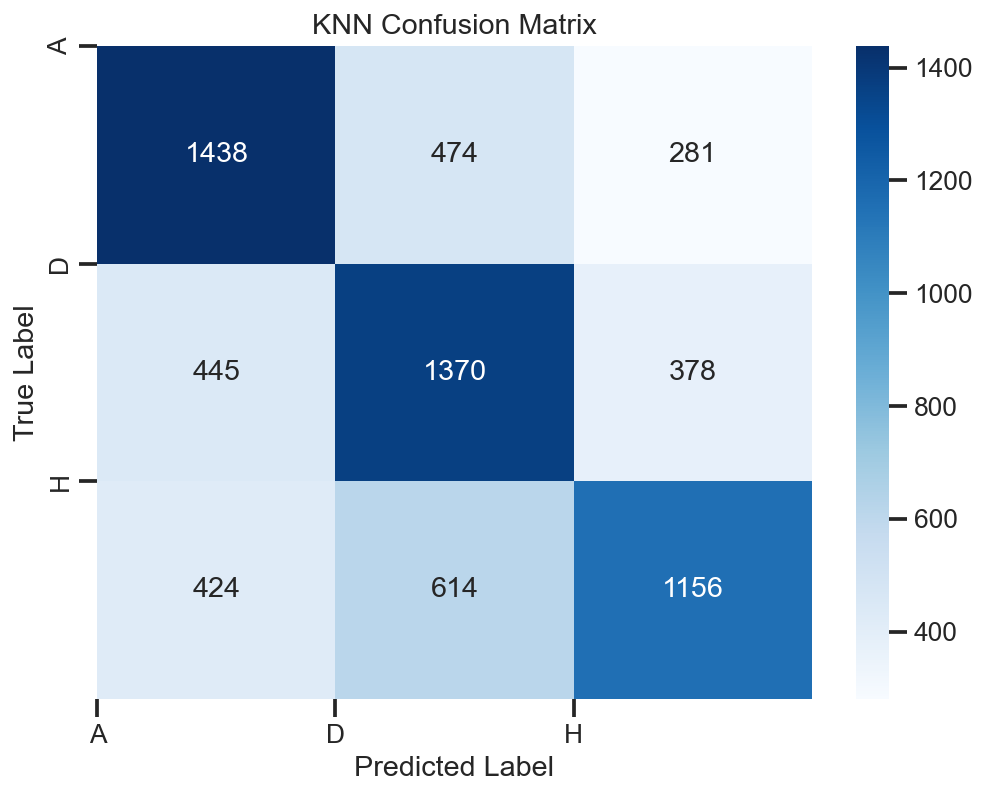

In [178]:
# Assuming you have the y_val and y_pred data

# Define the class names explicitly
class_names = ['A', 'D', 'H']

# Label encode the target variable 'FTR' for y_test and y_pred
label_encoder = LabelEncoder()
encoded_y_val = label_encoder.fit_transform(y_val)
encoded_y_pred3 = label_encoder.transform(knn_best_pred3)

# Create a confusion matrix
cm_knn = confusion_matrix(encoded_y_val, encoded_y_pred3)

# Create a heatmap of the confusion matrix
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")

# Add labels and title
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("KNN Confusion Matrix")

# Set x and y tick labels as class names
plt.xticks(ticks=range(len(class_names)), labels=class_names)
plt.yticks(ticks=range(len(class_names)), labels=class_names)

# Show the plot
plt.show()


### 5.4 Multi_layer Perceptron(MLP)

In [179]:
!pip install tensorflow scikit-learn pandas

Defaulting to user installation because normal site-packages is not writeable


In [180]:
# Create an instance of MLP Classifier
mlp_classifier = MLPClassifier(random_state=42)

# Train the classifier on the training data
mlp_classifier.fit(X_train, y_train)

C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(random_state=42)

In [181]:
# Make prediction on the validation data
mlp_pred4 = mlp_classifier.predict(X_val)


# Calculate the accuracy
mlp_accuracy = accuracy_score(y_val, mlp_pred4)
print(f"Accuracy: {mlp_accuracy:.2f}")

# # Generate a classification report
print("MLP Base Classification Report:")
print(classification_report(y_val, mlp_pred4))

Accuracy: 0.61
MLP Base Classification Report:
              precision    recall  f1-score   support

           A       0.62      0.65      0.64      2193
           D       0.59      0.61      0.60      2193
           H       0.62      0.57      0.59      2194

    accuracy                           0.61      6580
   macro avg       0.61      0.61      0.61      6580
weighted avg       0.61      0.61      0.61      6580



#Hyperparameter tuning
hidden_layer_sizes=(100,50), max_iter=300, Accuracy= 0.48
learning_rate= 'invscaling', alpha=0.0001, solver= 'adam', Accuracy= 0.48.4
activation ='tanh'. accuracy= 49.2
hidden_layer_sizes=(100,50), max_iter= 100, activation ='tanh'. Accuracy= .47
hidden_layer_sizes=(200,300), max_iter= 700, activation ='tanh'. Accuracy= .4884
hidden_layer_sizes=(100,50), max_iter= 500, activation ='tanh'. Accuracy= .4723
hidden_layer_sizes=(200,100), max_iter= 500, activation ='tanh'. Accuracy= .4846
hidden_layer_sizes=(200,300), max_iter= 500, activation ='tanh'. Accuracy= .4884
hidden_layer_sizes=(400,300), max_iter= 500, activation ='tanh'. Accuracy= .4688
hidden_layer_sizes=(300,300), max_iter= 500, activation ='tanh'. Accuracy= .4879
hidden_layer_sizes=(300,200), max_iter= 500, activation ='tanh'. Accuracy= .4738
hidden_layer_sizes=(activation ='tanh'). Accuracy= .4804
batch_size = 64, hidden_layer_sizes=(200,300), max_iter= 500, activation ='tanh'.Accuracy = .4809
batch_size = 32, hidden_layer_sizes=(200,300), max_iter= 500, activation ='tanh'.Accuracy = .4854
learning_rate= 'adaptive', hidden_layer_sizes=(200,300), max_iter= 500, activation ='tanh'.Accuracy = .4884


In [182]:
# # Create an instance of MLP Classifier
# mlp_classifier = MLPClassifier(learning_rate= 'adaptive', hidden_layer_sizes=(200,300), max_iter= 500, activation ='tanh', random_state=42)

# # Train the classifier on the training data
# mlp_classifier.fit(X_train, y_train)

In [183]:
# # Make prediction on the validation data
# mlp_y_pred4 = mlp_classifier.predict(X_val)


# # Calculate the accuracy
# mlp_accuracy = accuracy_score(y_val, mlp_y_pred4)
# print(f"Accuracy: {mlp_accuracy:.2f}")

# # # Generate a classification report
# print("MLP Classification Report:")
# print(classification_report(y_val, mlp_y_pred4))

In [184]:
# For tuning hyper parameters, define the grid
mlp_param_grid = {
    'hidden_layer_sizes': [(100,150), (150,200)],   # Number of neurons in the hidden layer
    'activation' : ['tanh'],    # The activation function for the hidden layers
    'alpha': [ 0.0001],  # L2 regularization parameter
    'max_iter' : [700],
    'solver' : ['adam'],   # Solver for the weight optimization
    'learning_rate': ['constant'],
    'random_state': [42]
}

In [185]:
# Let's creats the object of gridsearch
mlp_grid_search = GridSearchCV(mlp_classifier, mlp_param_grid, cv=3, scoring= 'accuracy')

# Perform the Grid Search
mlp_grid_search.fit(X_val, y_val)

GridSearchCV(cv=3, estimator=MLPClassifier(random_state=42),
             param_grid={'activation': ['tanh'], 'alpha': [0.0001],
                         'hidden_layer_sizes': [(100, 150), (150, 200)],
                         'learning_rate': ['constant'], 'max_iter': [700],
                         'random_state': [42], 'solver': ['adam']},
             scoring='accuracy')

In [186]:
# Get the best parameter and the best model
mlp_best_params = mlp_grid_search.best_params_
best_mlp_model = mlp_grid_search.best_estimator_

In [187]:
# Get the best RF model
best_mlp_model= mlp_grid_search.best_estimator_

In [188]:
# Train the best model with combined train & validation data as with concatenate X_train and X_val and y_train and y_val
# X_train_val = pd.concat([X_train, X_val], axis=0)
# y_train_val = pd.concat([y_train, y_val], axis=0)

# Train the best model
best_mlp_model.fit(X_train, y_train)

MLPClassifier(activation='tanh', hidden_layer_sizes=(150, 200), max_iter=700,
              random_state=42)

In [189]:
# Make predictions on the validation data
best_mlp_pred4 = best_mlp_model.predict(X_val)

# Calculate the accuracy on testing data
best_mlp_accuracy = accuracy_score(y_val, best_mlp_pred4)
print(f"Accuracy: {best_mlp_accuracy: 2f}")

# Generate a classification report
print("MLP Best Classification Report:")
print(classification_report(y_val, best_mlp_pred4))

Accuracy:  0.627508
MLP Best Classification Report:
              precision    recall  f1-score   support

           A       0.66      0.66      0.66      2193
           D       0.59      0.65      0.62      2193
           H       0.64      0.58      0.61      2194

    accuracy                           0.63      6580
   macro avg       0.63      0.63      0.63      6580
weighted avg       0.63      0.63      0.63      6580



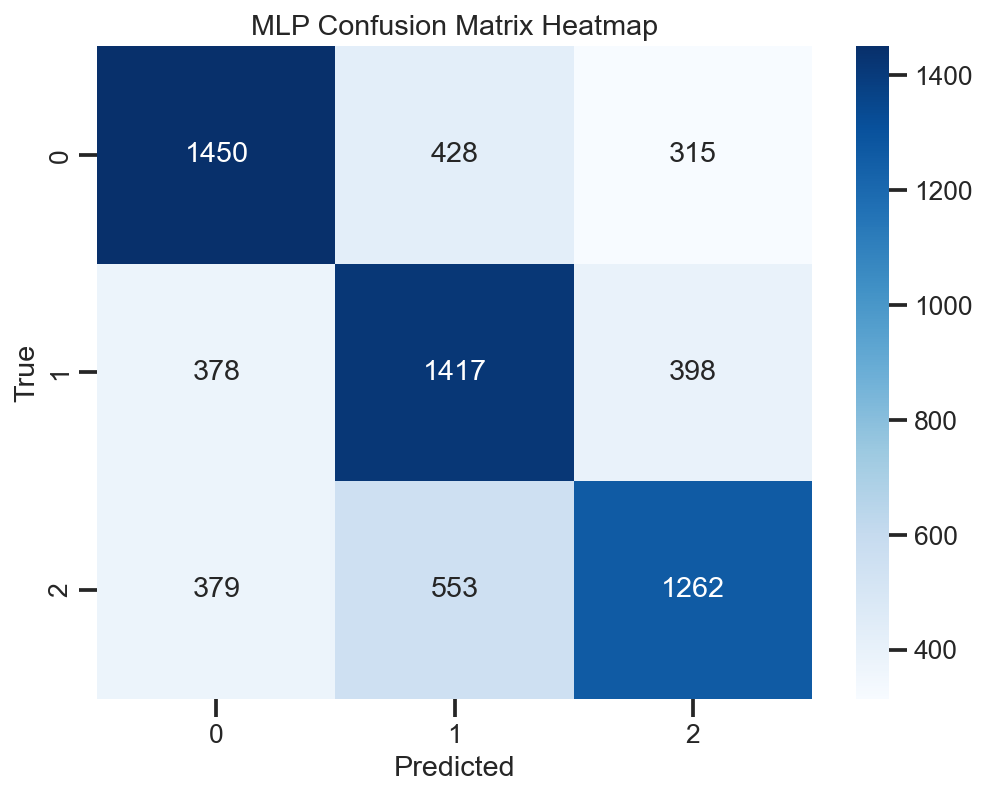

In [190]:
# Create a confusion matrix
cm_mlp = confusion_matrix(y_val, best_mlp_pred4)
#print("Confusion Matrix:")
#print(cm_mlp)

# Create a heatmap of the confusion matrix
# Add labels and title
plt.figure(figsize=(8,6))
sns.heatmap(cm_mlp, annot=True, fmt="g", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("MLP Confusion Matrix Heatmap")

# Show the plot
plt.show()

### 5.5 Gradient Boost Classifier

In [191]:
# Create instance of the Gradient Boosting Classifier
gb_classifier= GradientBoostingClassifier(random_state=42)

# Train the classifier on the training data
gb_classifier.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [192]:
# Make prediction on the validation data
gbc_pred5 = gb_classifier.predict(X_val)

# Calculate the accuracy
gbc_accuracy = accuracy_score(y_val, gbc_pred5)
print(f"Accuracy: {gbc_accuracy:.2f}")

# # Generate a classification report
print("GBC Base Classification Report:")
print(classification_report(y_val, gbc_pred5))

Accuracy: 0.58
GBC Base Classification Report:
              precision    recall  f1-score   support

           A       0.57      0.61      0.59      2193
           D       0.53      0.46      0.49      2193
           H       0.63      0.67      0.65      2194

    accuracy                           0.58      6580
   macro avg       0.58      0.58      0.58      6580
weighted avg       0.58      0.58      0.58      6580



Hyperparameter testings(completed):
Accuracy=.5685 (n_estimators= 300, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.559 (n_estimators= 500, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.570 (n_estimators= 200, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.5738 (n_estimators= 100, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.5718 (n_estimators= 80, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.5745 (n_estimators= 90, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.5726 (n_estimators= 300, learning_rate=0.2, min_samples_split= 10, min_samples_leaf= 1)
Accuracy=.5735 (n_estimators= 300, learning_rate=0.1, min_samples_split= 20, min_samples_leaf= 1)
Accuracy=.5738 (n_estimators= 300, learning_rate=0.1, min_samples_split= 5, min_samples_leaf= 1)
Accuracy=.5733 (n_estimators= 300, learning_rate=0.1, min_samples_split= 10, min_samples_leaf=3)
Accuracy=.4663 (n_estimators= 300, learning_rate=0.1, min_samples_split= 10, min_samples_leaf=.5)
Accuracy=.57458 (n_estimators= 300, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1, max_depth=3)
Accuracy=.5685 (n_estimators= 300, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1, max_depth=5)
Accuracy=.57458(n_estimators= 90, learning_rate=0.1, min_samples_split= 10, min_samples_leaf= 1, max_depth=3, max_features= None )


In [193]:
# For tuning hyper parameters, define the grid
gbc_param_grid = {
    'n_estimators': [80, 100,],   # Number of trees in the forest
    'learning_rate':[0.1],
    #'max_depth' : [3,8]    # The max depth of trees
    #'min_samples_split': [2,5,10],  # Max no of samples required to split internal node
    #'min_samples_leaf' : [1,2,4],   # Max no of samples required to be at a leaf node
    #'max_features': ['sqrt', 'log2', None], # No of features in looking fo the best split
    #'class_weight' : [None, 'balanced']       # weight to address class imbalance
}

In [194]:
# Let's creats the object of gridsearch  & Perform the Grid Search using training data
gbc_grid_search = GridSearchCV(gb_classifier, gbc_param_grid, cv=3, scoring= 'accuracy')
gbc_grid_search.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'learning_rate': [0.1], 'n_estimators': [80, 100]},
             scoring='accuracy')

In [195]:
# Get the best RF model
best_gbc_model= gbc_grid_search.best_estimator_

In [196]:
# Train the best model on the combined training and validation data
# Let's concatenate X_train and X_val and y_train and y_val
# X_train_val = pd.concat([X_train, X_val], axis=0)
# y_train_val = pd.concat([y_train, y_val], axis=0)

best_gbc_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [197]:
# Make predictions on testing data on best model(Check X-test)
best_gbc_pred5 = best_gbc_model.predict(X_val)

# Calculate the accuracy on the testing data
gbc_best_accuracy = accuracy_score(y_val, best_gbc_pred5)
print(f"Accuracy: {gbc_best_accuracy: 2f}")

# Generate a classification report for validation data
print(" Best GBC Classification Report for:")
print(classification_report(y_val, best_gbc_pred5))

Accuracy:  0.581155
 Best GBC Classification Report for:
              precision    recall  f1-score   support

           A       0.57      0.61      0.59      2193
           D       0.53      0.46      0.49      2193
           H       0.63      0.67      0.65      2194

    accuracy                           0.58      6580
   macro avg       0.58      0.58      0.58      6580
weighted avg       0.58      0.58      0.58      6580



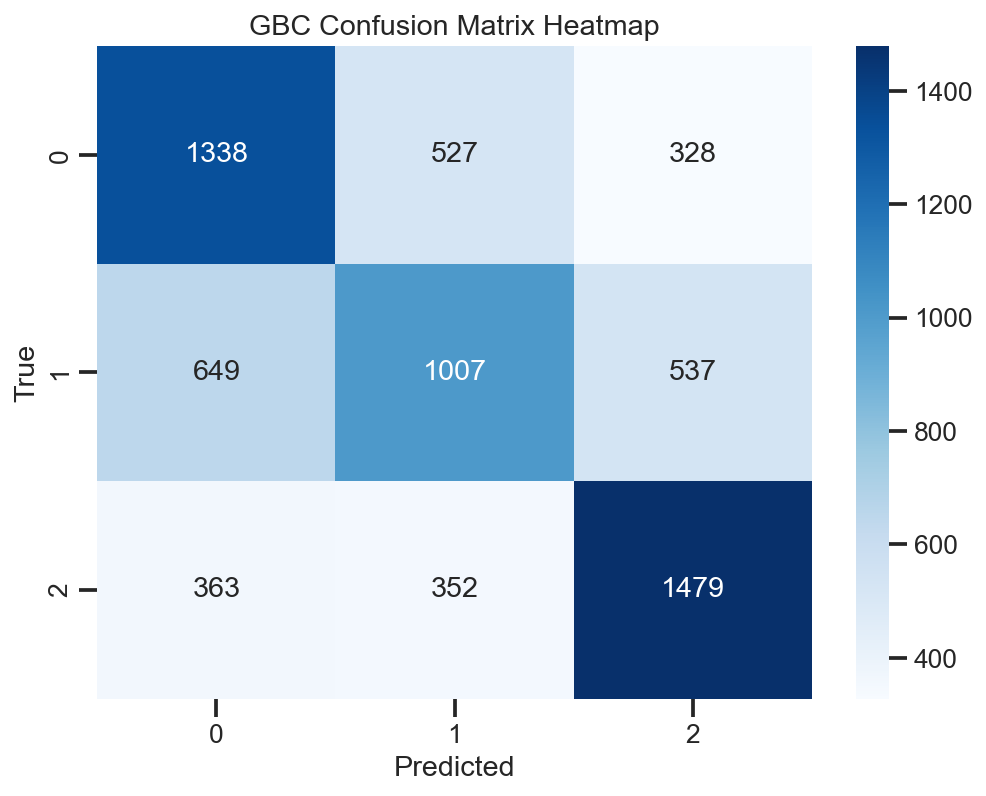

In [198]:
# Create a confusion matrix
cm_gbc = confusion_matrix(y_val, best_gbc_pred5)

# Create a heatmap of the confusion matrix
# Add labels and title
plt.figure(figsize=(8,6))
sns.heatmap(cm_gbc, annot=True, fmt="g", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("GBC Confusion Matrix Heatmap")

# Show the plot
plt.show()

# 5.6. Voter  Ensembler

In [199]:
from sklearn.ensemble import VotingClassifier

# lets weigh the models with high importance for the best model
weights = [2,1,2,1]

# Create the list of tuples for the Voting Classifier
estimators = [
    ('rf', best_rf_model),
    ('knn', best_knn_model),
    ('mlp', best_mlp_model),
    ('gb', best_gbc_model)
]

# Initialize the voting classifier with soft voting (voting='soft')
voting_classifier = VotingClassifier(estimators, voting='soft')

# Trian the VotingClassifier on the training data
voting_classifier.fit(X_train, y_train)

# Predict on the voting set
voting_preds6 = voting_classifier.predict(X_val)

# Evaluate the ensemble's performance on the validation set
voting_accuracy= accuracy_score(y_val, voting_preds6)
print("Voting Classifier Accuracy on Validation Set:", voting_accuracy)

Voting Classifier Accuracy on Validation Set: 0.653951367781155


C:\Users\chint\AppData\Roaming\Python\Python39\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


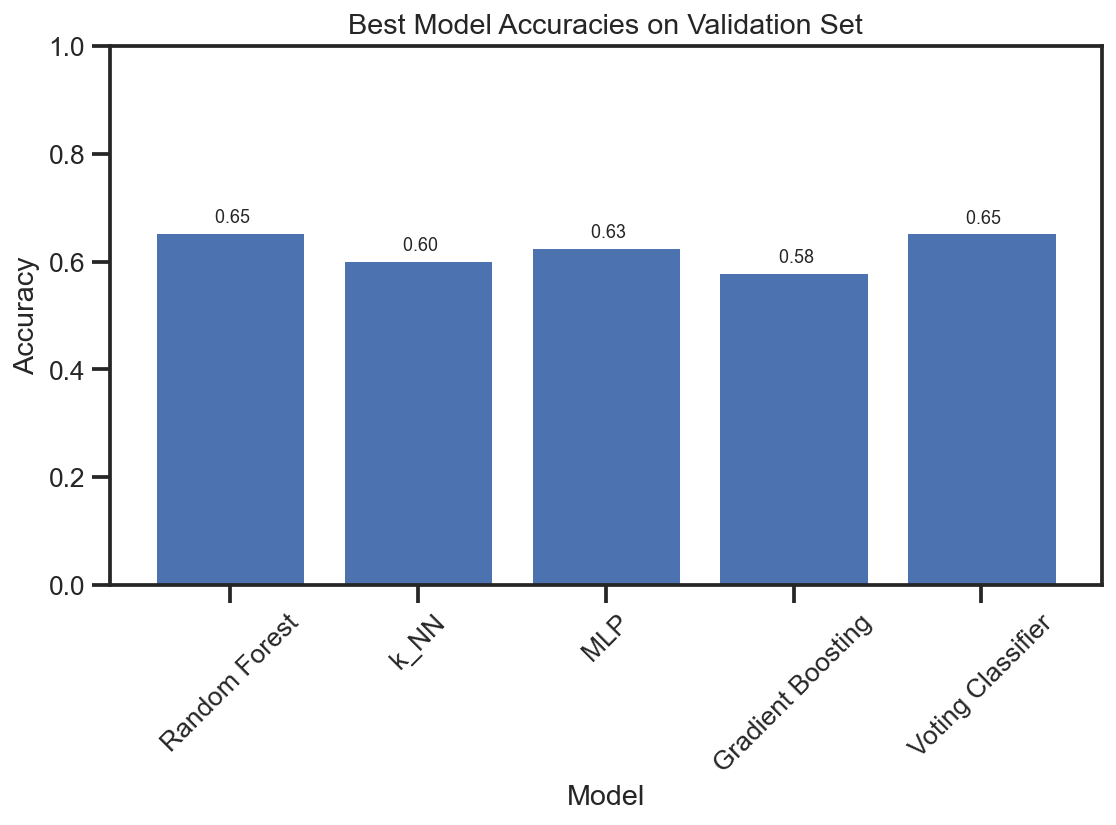

In [200]:
mlp_classifier.fit(X_train, y_train) # As weights changed

# Define the accuracy

accuracies = {
    'Random Forest': best_rf_model.score(X_val, y_val),
    'k_NN' : best_knn_model.score(X_val, y_val),
    'MLP': best_mlp_model.score(X_val, y_val),
    'Gradient Boosting': best_gbc_model.score(X_val, y_val),
    'Voting Classifier': voting_accuracy
}

# Create a bar chart to display accuracies
plt.figure(figsize=(8,6))
plt.bar(accuracies.keys(), accuracies.values())
plt.ylim(0,1)
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Best Model Accuracies on Validation Set')
plt.xticks(rotation=45)

# Display the accuracies on top of the bars
for model, accuracy in accuracies.items():
    plt.text(model, accuracy + 0.01, f'{accuracy: .2f}' , ha = 'center', va='bottom', fontsize=9)

    plt.tight_layout()
plt.show()

In [201]:
# Make predictions on testing data on best model(Check X-test)
voting_preds6 = voting_classifier.predict(X_val)

# Calculate the accuracy on the testing data
voting_accuracy = accuracy_score(y_val, voting_preds6)
print(f"Accuracy: {voting_accuracy: 2f}")

# Generate a classification report for validation data
print(" Voting Classification Report for:")
print(classification_report(y_val, voting_preds6))

Accuracy:  0.653951
 Voting Classification Report for:
              precision    recall  f1-score   support

           A       0.67      0.70      0.69      2193
           D       0.62      0.65      0.63      2193
           H       0.67      0.61      0.64      2194

    accuracy                           0.65      6580
   macro avg       0.65      0.65      0.65      6580
weighted avg       0.65      0.65      0.65      6580



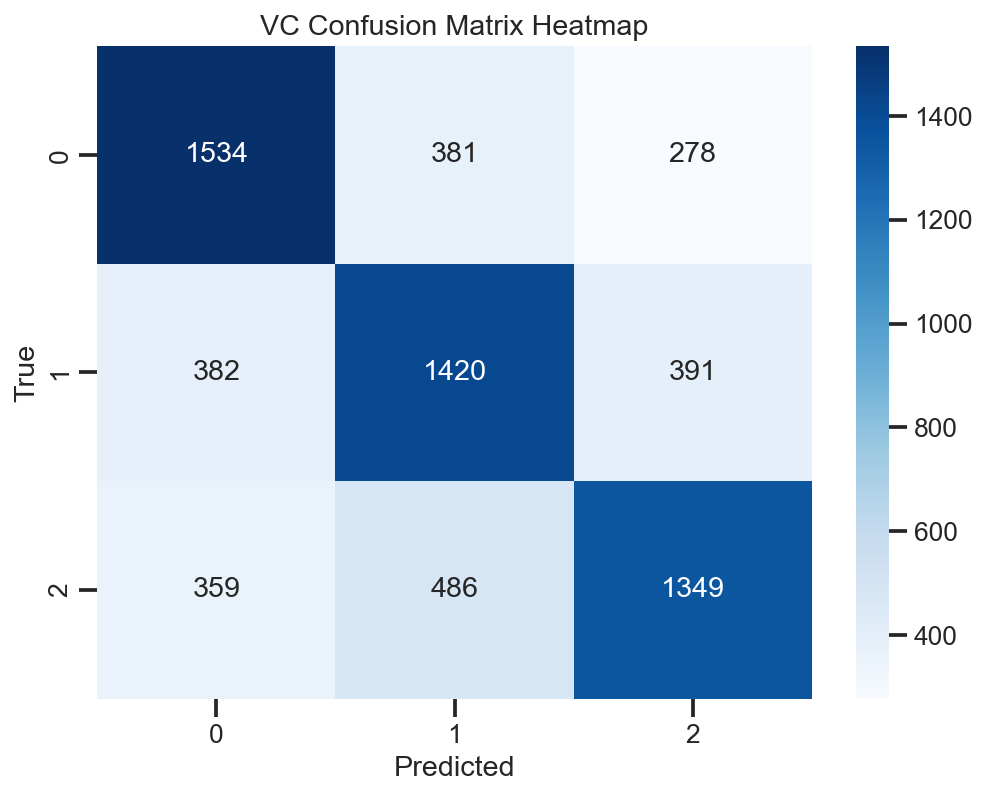

In [202]:
# Create a confusion matrix
cm_vc = confusion_matrix(y_val, voting_preds6)

# Create a heatmap of the confusion matrix
# Add labels and title
plt.figure(figsize=(8,6))
sns.heatmap(cm_vc, annot=True, fmt="g", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("VC Confusion Matrix Heatmap")

# Show the plot
plt.show()

## 6. Model Evaluation

### 6.1. Overall Performance with Cross Validation

In [203]:
# List the models
models = [best_rf_model, best_knn_model, best_mlp_model, best_gbc_model, voting_classifier]
model_names = ["RFC", "k_NN", "MLP", "GBC", "VC"]

# Create a function to evaluate each model
def evaluate_model(model, name, X_test, y_test):
    # Make prediction on the test set
    y_pred_test = model.predict(X_test)
    
    # Calculate the accuracy on the test set by sklearn accuracy score
    accuracy_test = accuracy_score(y_test, y_pred_test)
    
    # Generate a classification report for the test set
    print("f{name} ~ testing Accuracy: {accuracy_test:.2f}")
    print("Testing Classification Report:")
    print(classification_report(y_test, y_pred_test))
    
# Evaluate each model on the test set
for model, name in zip(models, model_names):
    evaluate_model(model, name, X_test, y_test)

f{name} ~ testing Accuracy: {accuracy_test:.2f}
Testing Classification Report:
              precision    recall  f1-score   support

           A       0.67      0.70      0.69      1080
           D       0.69      0.59      0.64      1081
           H       0.64      0.70      0.67      1080

    accuracy                           0.66      3241
   macro avg       0.67      0.66      0.66      3241
weighted avg       0.67      0.66      0.66      3241

f{name} ~ testing Accuracy: {accuracy_test:.2f}
Testing Classification Report:
              precision    recall  f1-score   support

           A       0.62      0.64      0.63      1080
           D       0.58      0.66      0.62      1081
           H       0.66      0.54      0.60      1080

    accuracy                           0.62      3241
   macro avg       0.62      0.62      0.62      3241
weighted avg       0.62      0.62      0.62      3241

f{name} ~ testing Accuracy: {accuracy_test:.2f}
Testing Classification Report:
 

RFC - Average CV Score: 0.6285
k_NN - Average CV Score: 0.5746
MLP - Average CV Score: 0.5939
GBC - Average CV Score: 0.5822
VC - Average CV Score: 0.6285


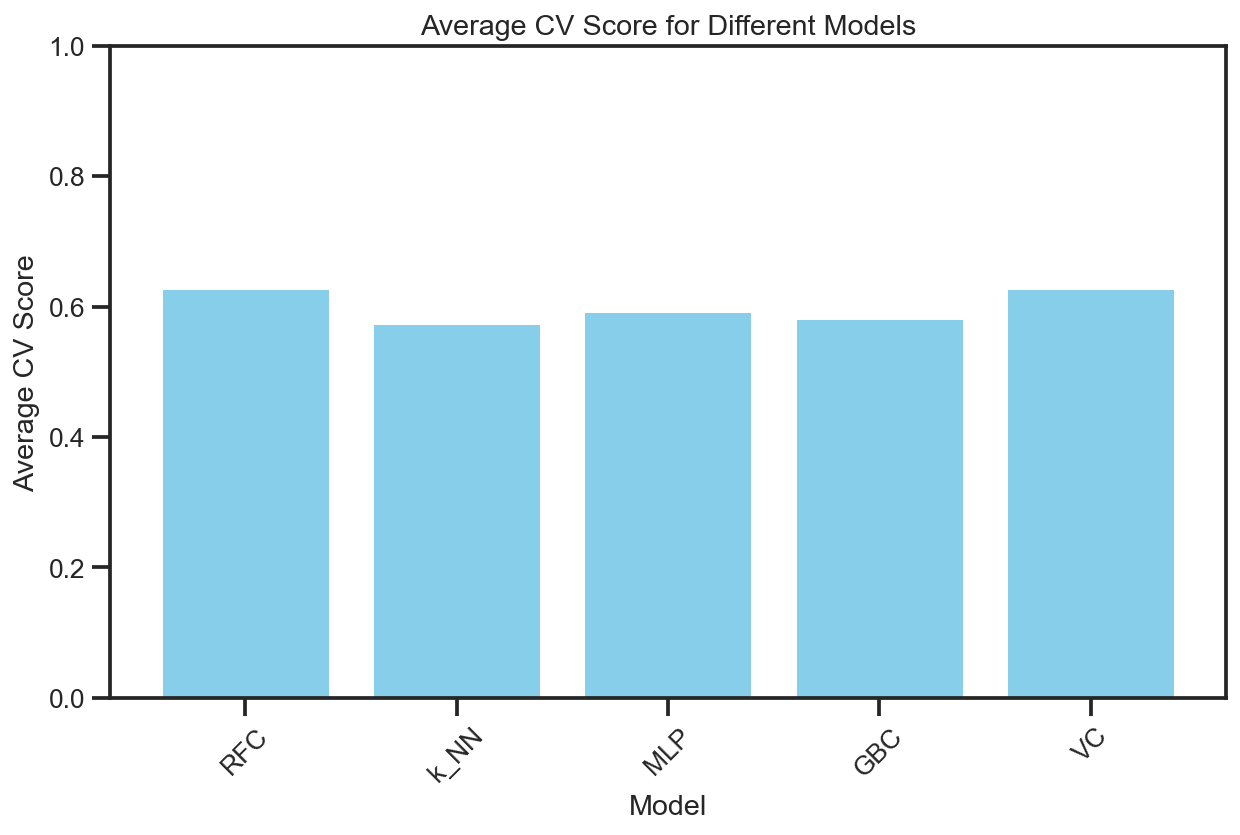

In [204]:
# Get the models
models = [('RFC', best_rf_model),
        ('k_NN', best_knn_model),
        ('MLP', best_mlp_model),
        ('GBC', best_gbc_model),
        ('VC', voting_classifier)]

# List to store model names and the average CV scores
model_names = []
avg_cv_scores = []

# Perform cross validation for each model and store the results
for model_name,model in models:
    cv_scores = cross_val_score(model, X_train, y_train, cv=3, scoring='f1_micro')
    avg_cv_score = np.mean(cv_scores)
    model_names.append(model_name)
    avg_cv_scores.append(avg_cv_score)
    print(f"{model_name} - Average CV Score: {avg_cv_score:.4f}")

# Create bar plot to visualize the average CV scores of each model
plt.figure(figsize=(10,6))
plt.bar(model_names, avg_cv_scores, color='skyblue')
plt.xlabel('Model')
plt.ylabel('Average CV Score')
plt.title('Average CV Score for Different Models')
plt.xticks(rotation=45)
plt.ylim(0, 1.0)
plt.show()

### 6.2.Overall Performance with Cross Validation on the Best moodel-RF Classifier

CV Scores: [0.63324607 0.64912281 0.64310029 0.64624247 0.63917256 0.64755172]
Average CV Score: 0.6430726522617919


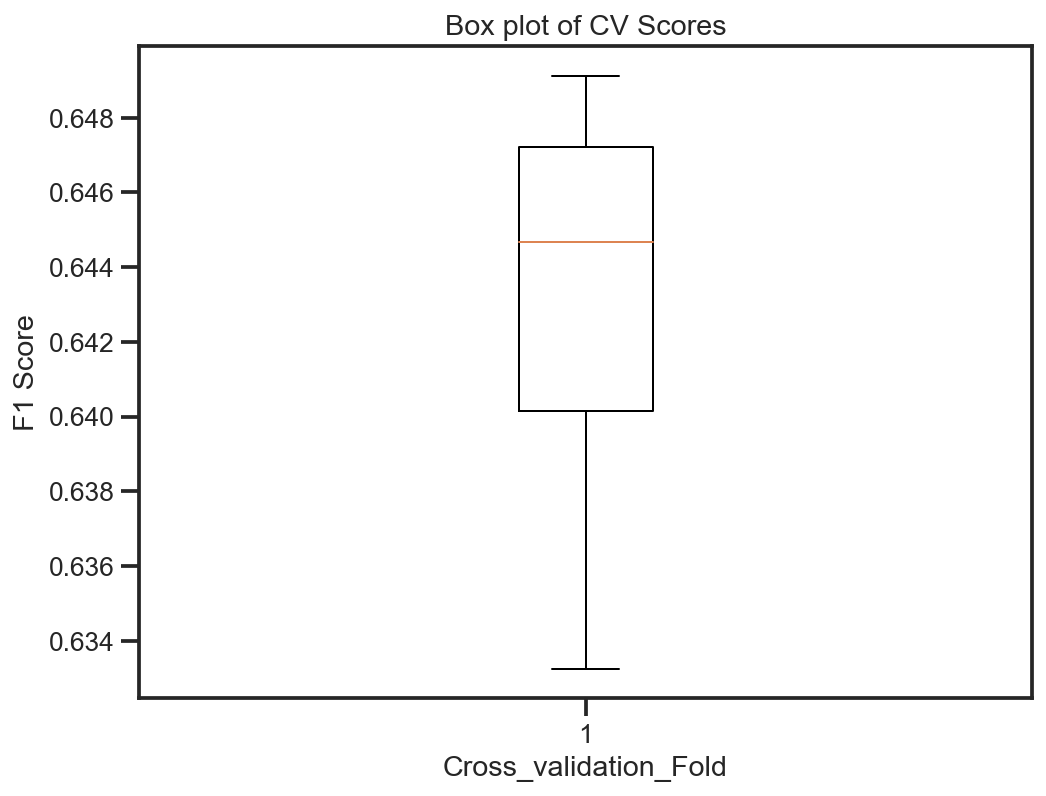

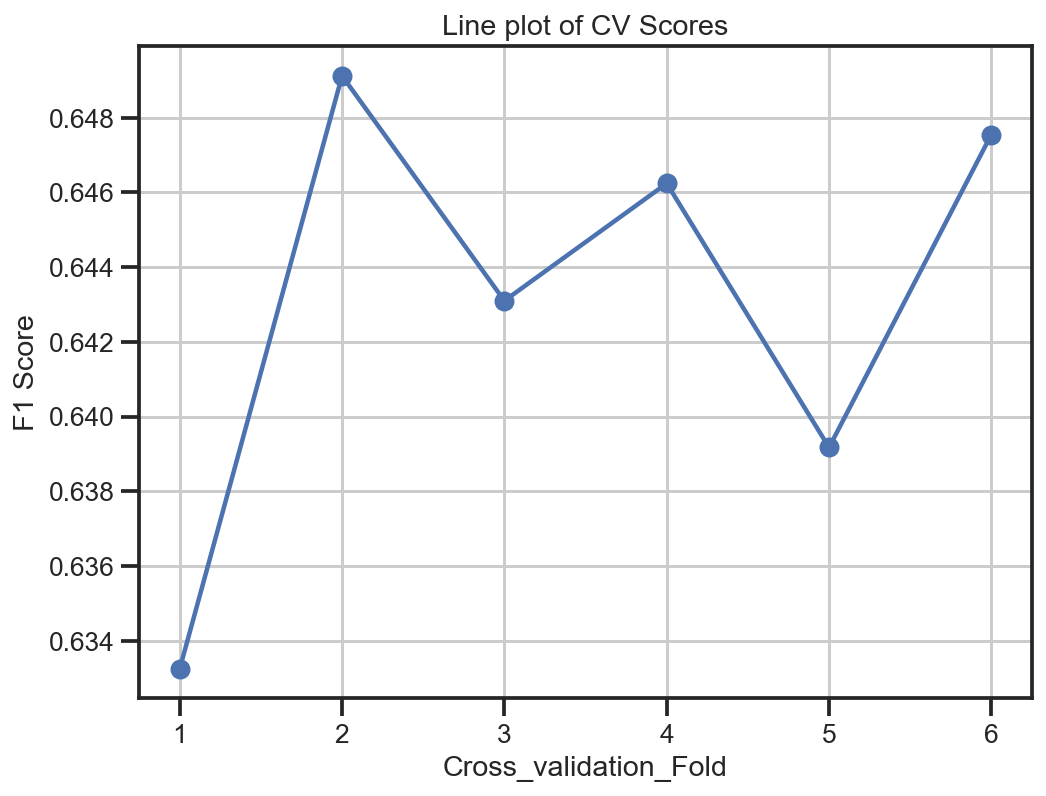

In [205]:
# Create an instance of the VotingClassifier with selected hyperparameters
# voting_classifier = VotingClassifier(estimators, voting='soft')

# Perform cross-validation and get the CV scores (F1 score)
cv_scores = cross_val_score(best_rf_model, X_train, y_train, cv=6, scoring='f1_micro')

# Print the CV scores and the average CV score
print("CV Scores:", cv_scores)
print("Average CV Score:", np.mean(cv_scores))

# Get box plot of the CV scores
plt.figure(figsize=(8,6))
plt.boxplot(cv_scores)
plt.xlabel('Cross_validation_Fold')
plt.ylabel('F1 Score')
plt.title('Box plot of CV Scores')
plt.show()

# Get line plot of the CV scores
plt.figure(figsize=(8,6))
plt.plot(np.arange(1,len(cv_scores) +1), cv_scores, marker='o')
plt.xlabel('Cross_validation_Fold')
plt.ylabel('F1 Score')
plt.title('Line plot of CV Scores')
plt.xticks(np.arange(1, len(cv_scores) + 1))
plt.grid(True)
plt.show()

### 6.2. Verify the Model Performance through ROC-AUC Curves

In [206]:
# Lets verify the unique clases in validation set of y
print(np.unique(y_val))

['A' 'D' 'H']


In [207]:
from sklearn.metrics import roc_auc_score, roc_curve, auc

# Create instance of the Gradient Boosting Classifier
voting_classifier= VotingClassifier(estimators, voting='soft')

# Train the classifier on the training data
rf_classifier.fit(X_train, y_train)

# start with make prediction using trained gbc model
y_pred_proba = rf_classifier.predict_proba(X_val)

# # Compute the macro_averaged ROC_AUC
mean_roc_auc = roc_auc_score(y_val, y_pred_proba, multi_class= 'ovr', average='macro')

print("Mean ROC-AUC:", mean_roc_auc)

Mean ROC-AUC: 0.8195191130603735


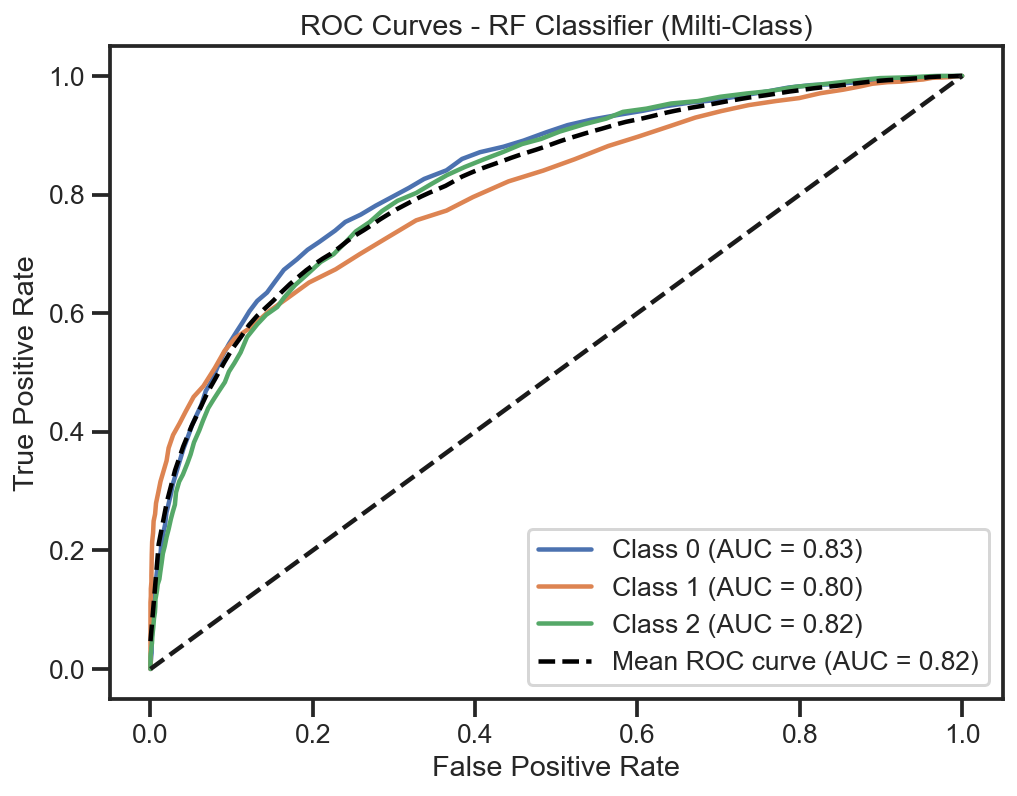

In [208]:
from sklearn.metrics import roc_auc_score, roc_curve, auc

# Let's converts the class labels from strings to integers in mapping them
class_mapping = {'A': 0, 'D': 1, 'H': 2}
y_val_int = np.array([class_mapping[label] for label in y_val])

# Make predictions using the trained data of the model
y_pred_proba = rf_classifier.predict_proba(X_val)

# Calculate the macro-averaged ROC-AUC
mean_roc_auc = roc_auc_score(y_val_int, y_pred_proba, multi_class='ovr', average='macro')

# Generate ROC curves for each class
n_classes = 3
fpr = dict()
tpr = dict()
roc_auc = dict()


for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve((y_val_int == i), y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Let's Plot ROC curves for each class

plt.figure(figsize=(8, 6))
for i in range(n_classes):   
    plt.plot(fpr[i], tpr[i], label= f'Class {i} (AUC = {roc_auc[i]:.2f})')

# Plot mean ROC curve taking the averages
mean_fpr = np.linspace(0, 1, 100)
mean_tpr = np.zeros_like(mean_fpr)
for i in range(n_classes):    
    mean_tpr += np.interp(mean_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes
mean_auc = auc(mean_fpr, mean_tpr)

plt.plot(mean_fpr, mean_tpr, label=f'Mean ROC curve (AUC = {mean_auc:.2f})', color='black', linestyle='--')

# Plot the diagonal line representing random guessing in taking references
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - RF Classifier (Milti-Class)')
plt.legend()
plt.show()

### 5.8. True vs Predicted analysis of the best model RFC

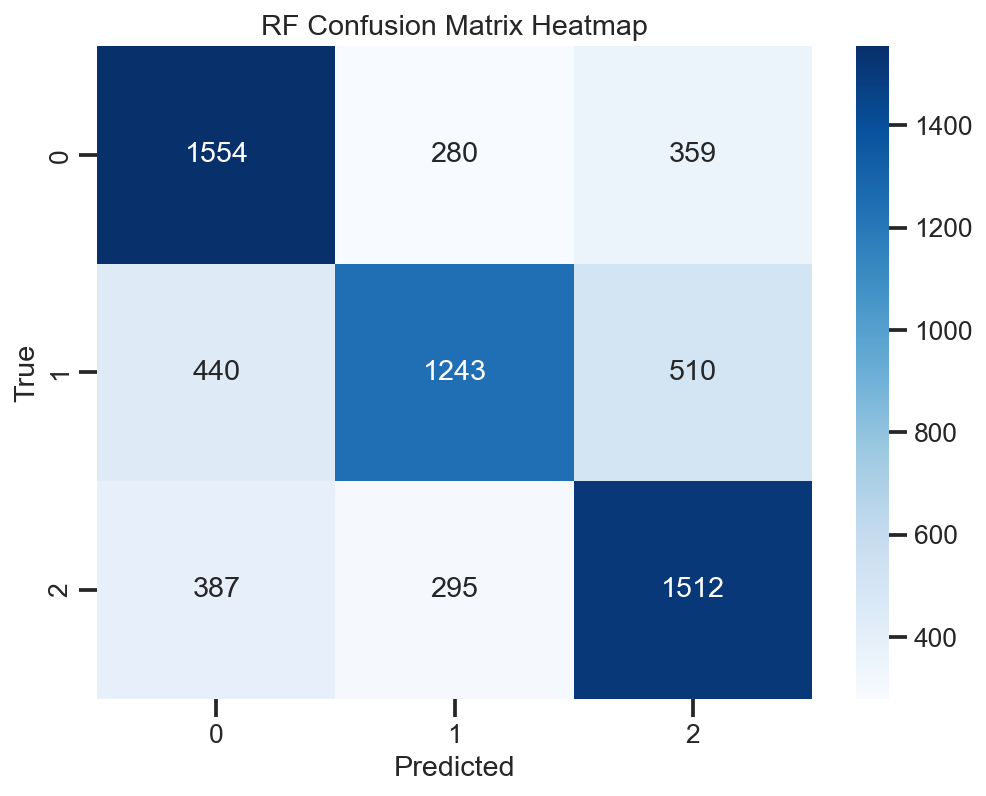

In [209]:
# Create a confusion matrix
cm_rf = confusion_matrix(y_val, rfc_best_pred2)

# Create a heatmap of the confusion matrix
# Add labels and title
plt.figure(figsize=(8,6))
sns.heatmap(cm_rf, annot=True, fmt="g", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("RF Confusion Matrix Heatmap")

# Show the plot
plt.show()

In [210]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate the evaluation metrics for the best model, GBC
accuracy = accuracy_score(y_val, rfc_best_pred2)
precision = precision_score(y_val, rfc_best_pred2, average= 'micro')
recall = recall_score(y_val, rfc_best_pred2, average= 'micro')
f1 = f1_score(y_val, rfc_best_pred2, average= 'micro')

# Print evaluation metrics
print("Confusion Matrix:")
print(confusion_matrix)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Confusion Matrix:
<function confusion_matrix at 0x000002B4F4514670>
Accuracy: 0.6548632218844985
Precision: 0.6548632218844985
Recall: 0.6548632218844985
F1 Score: 0.6548632218844985


### 5.9 Global & Local Explanation with SHAP

#### 5.9.1. Global Explanation

In [211]:
pip install --user --upgrade numba

Note: you may need to restart the kernel to use updated packages.


In [212]:
#!pip install -q shap

In [213]:
#pip install shap --user

In [214]:
#pip uninstall shap

In [215]:
pip install --user shap==0.42.1

Note: you may need to restart the kernel to use updated packages.


In [216]:
# import numba
# print(numba.__version__)

In [217]:
import shap
shap.initjs()

Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)


In [218]:
print("SHAP version:", shap.__version__)

SHAP version: 0.42.1


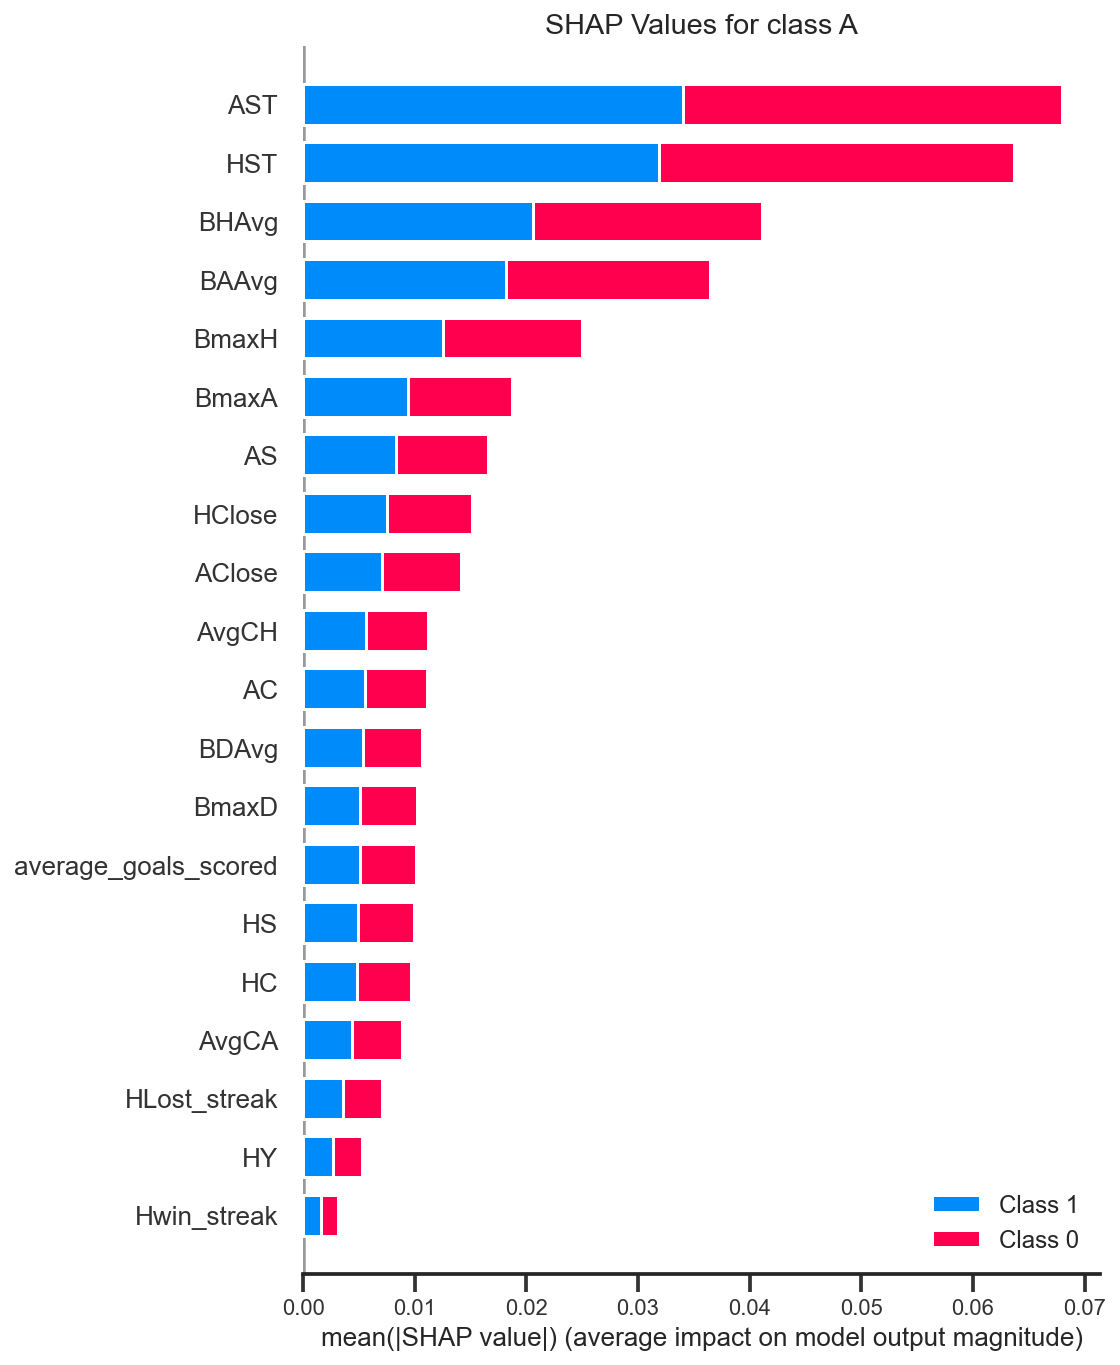

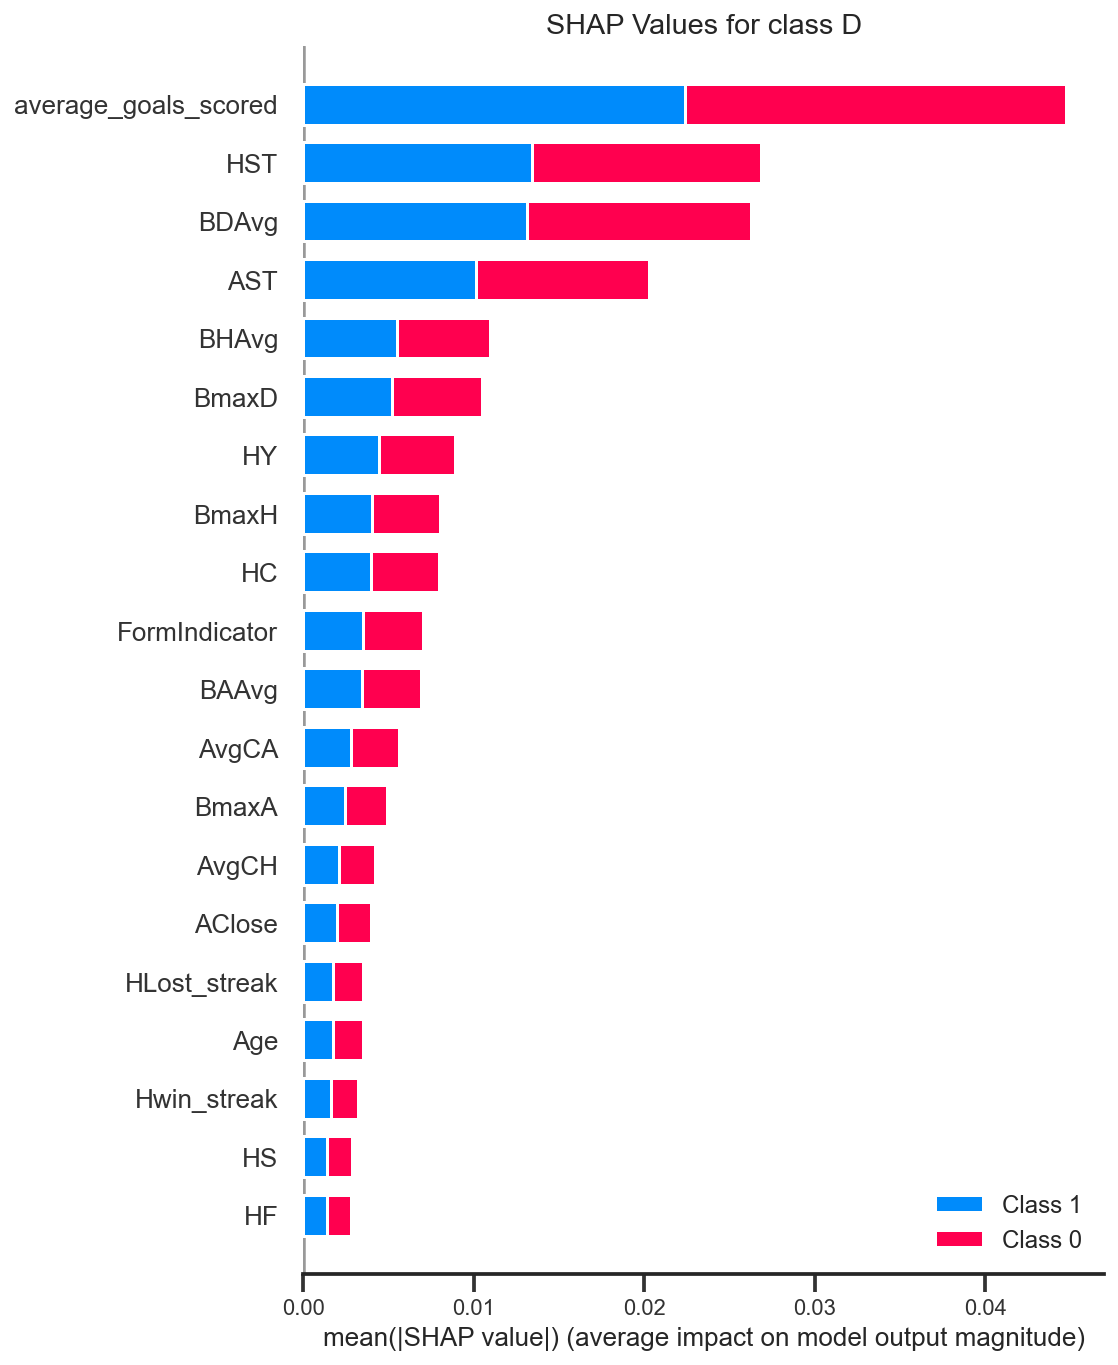

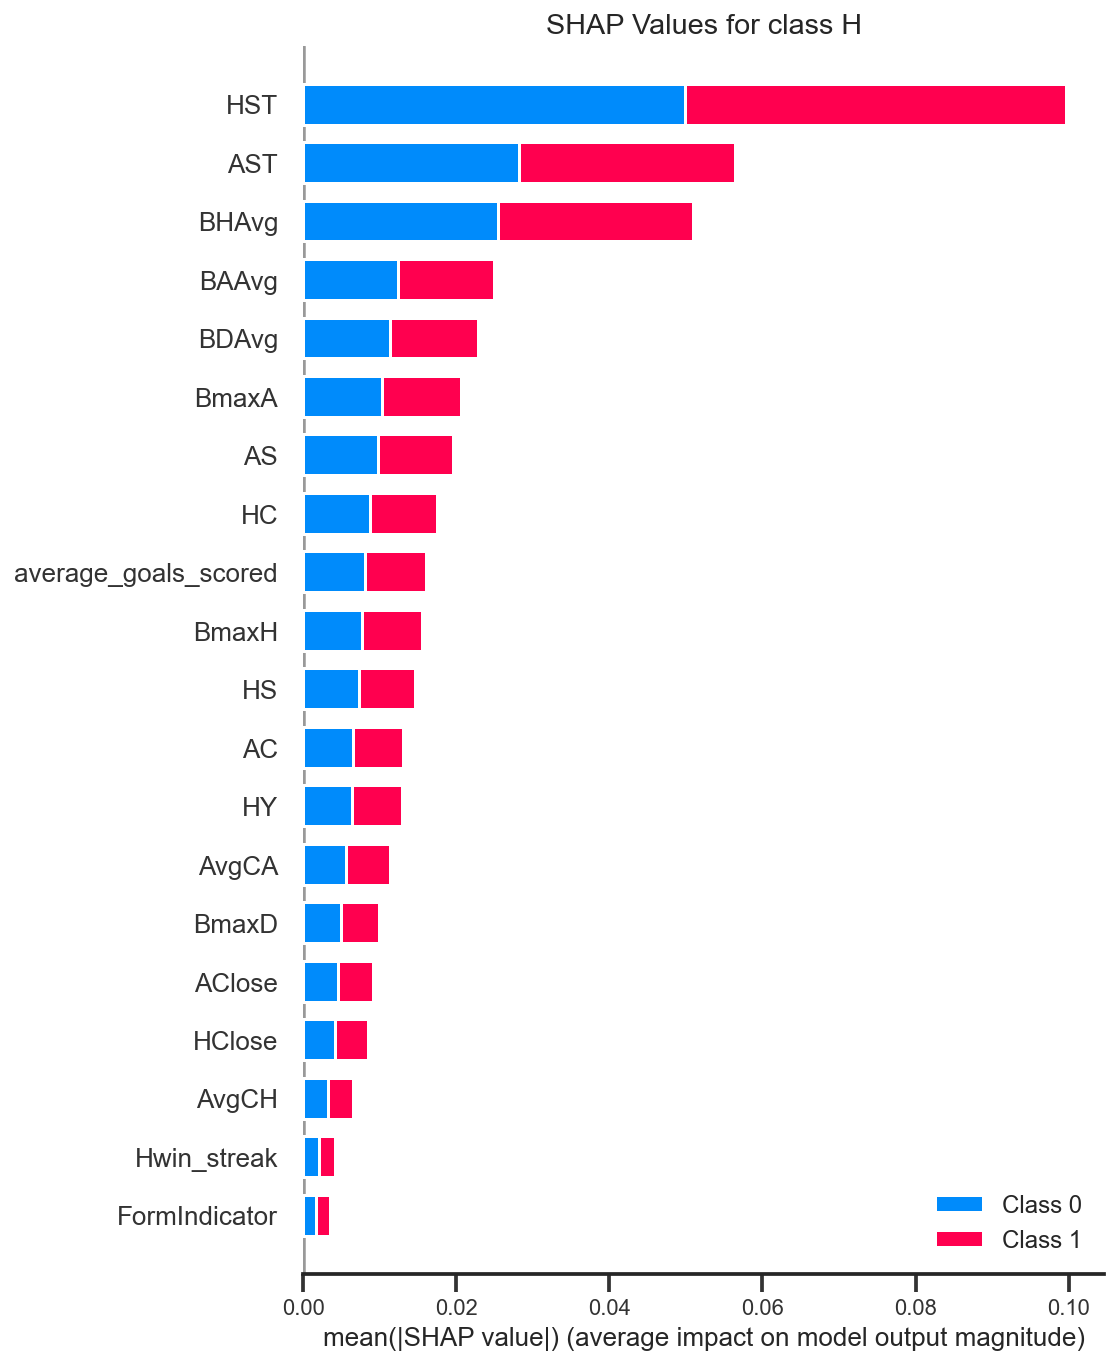

In [219]:
from sklearn.multiclass import OneVsRestClassifier

# Label Encode categorical target
label_encoder =  LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

# Create an instance of GBC
rf_classifier = RandomForestClassifier(class_weight='balanced', max_depth= 10, n_estimators=50, random_state=42)

# Convert the multi cladss into binary
ovr_classifier = OneVsRestClassifier(rf_classifier)

# Train the classifier
ovr_classifier.fit(X_train, y_train_encoded)

# Create a list of binary classifiers
binary_classifiers = ovr_classifier.estimators_

# Create a list of shap explainers for each binary classifier
explainers = [shap.TreeExplainer(classifier) for classifier in binary_classifiers] 

# Calculate the shap values for the validation set using the binary classifier
shap_values = [explainer.shap_values(X_val) for explainer in explainers]

# Define class names in correct order
# class_names = label_encoder.classes_

# Summary plot for each class
for i, class_name in enumerate(label_encoder.classes_):
    # plot the summary pplot for each class
    shap.summary_plot(shap_values[i], features = X_val, plot_type='bar', show=False)
    # Add a title to the plot for the spesific class
    plt.title(f"SHAP Values for class {class_name}")
    plt.show()

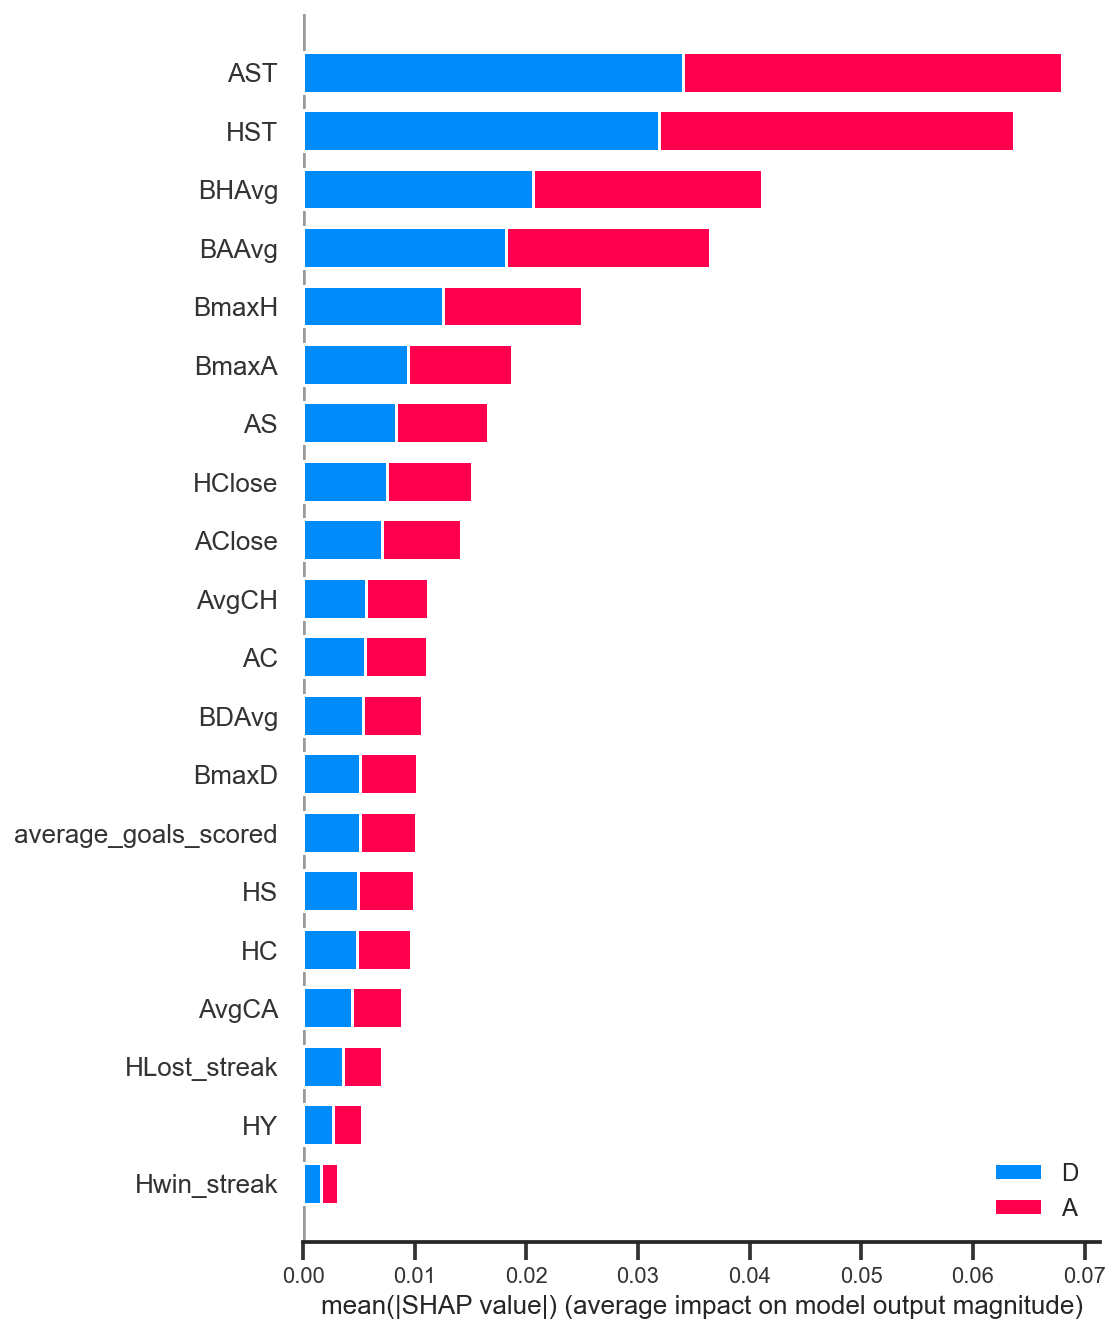

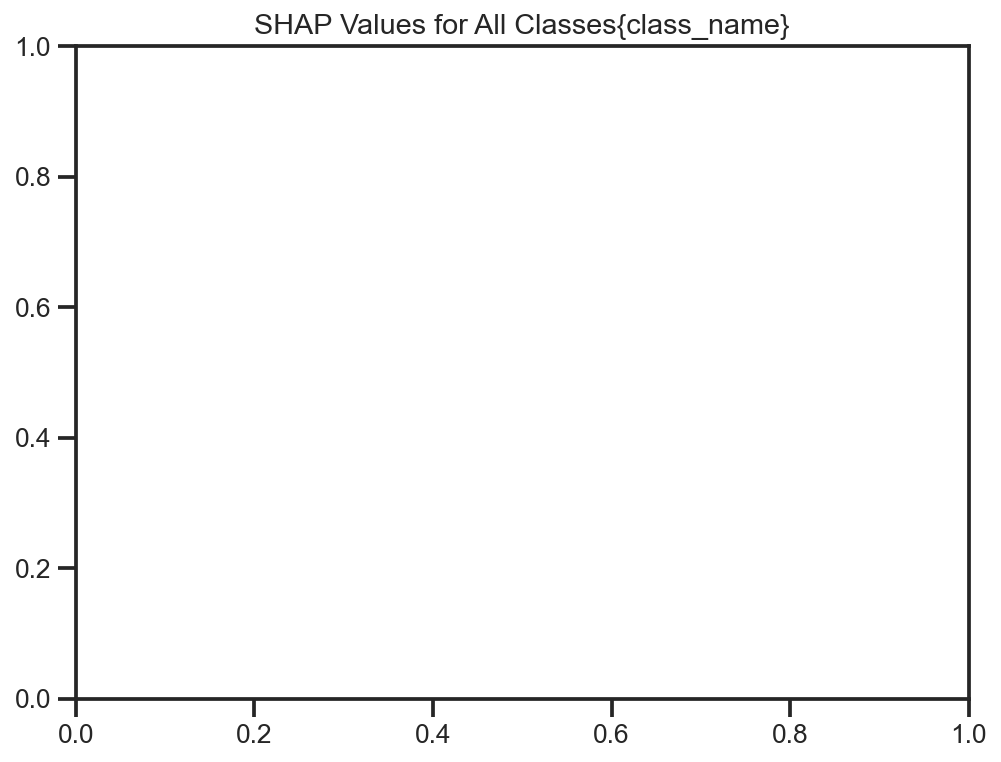

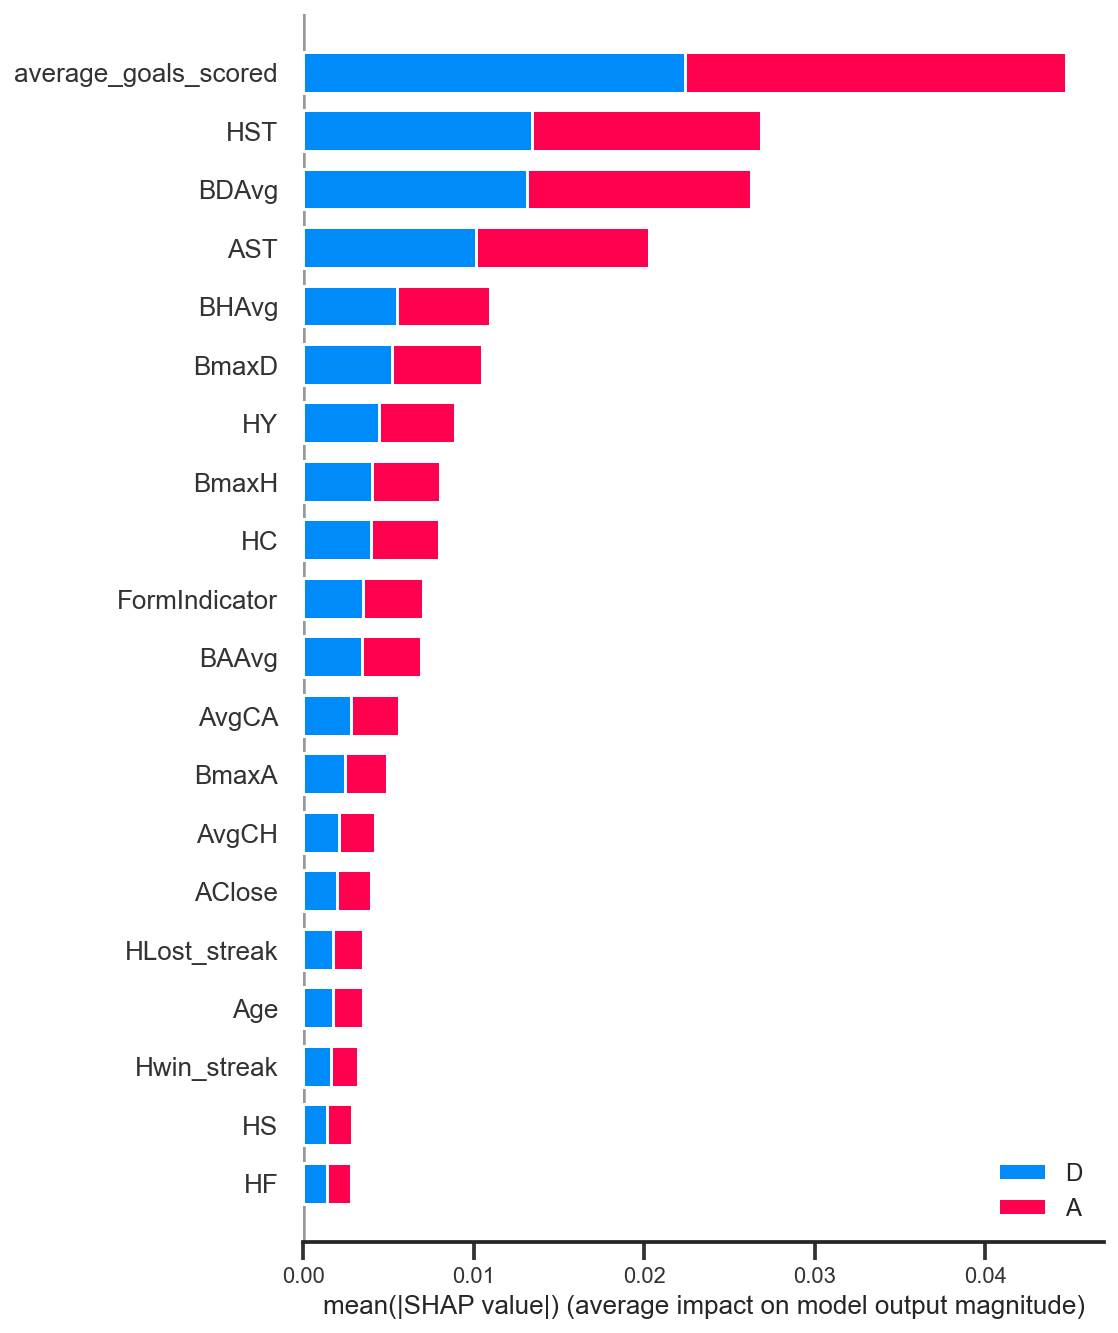

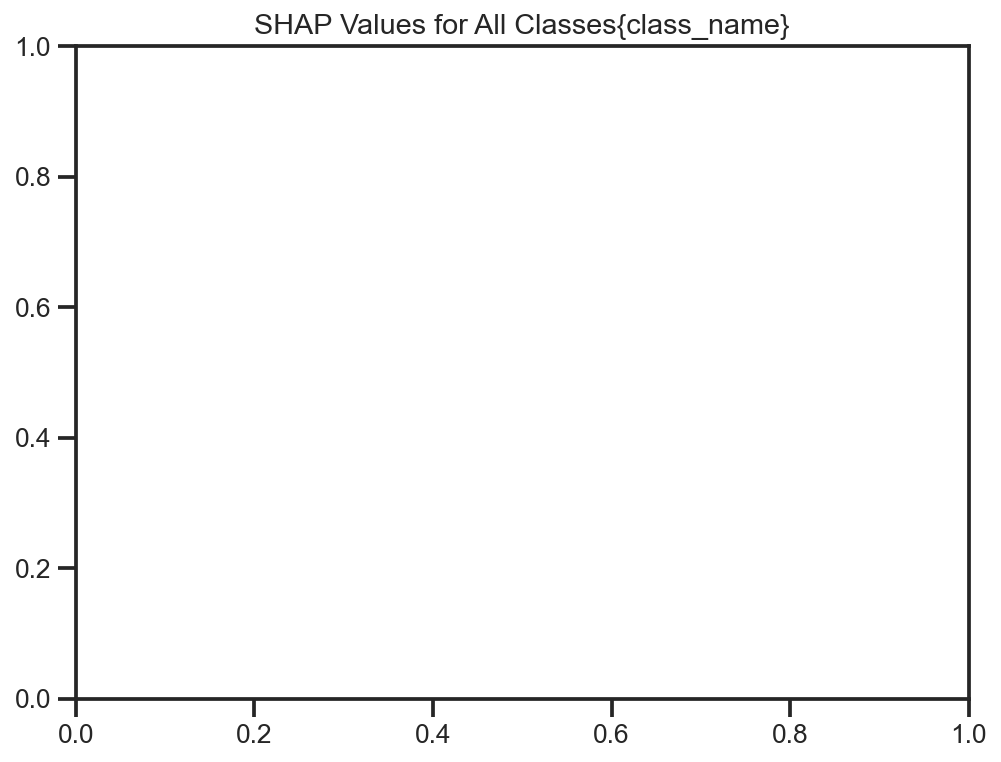

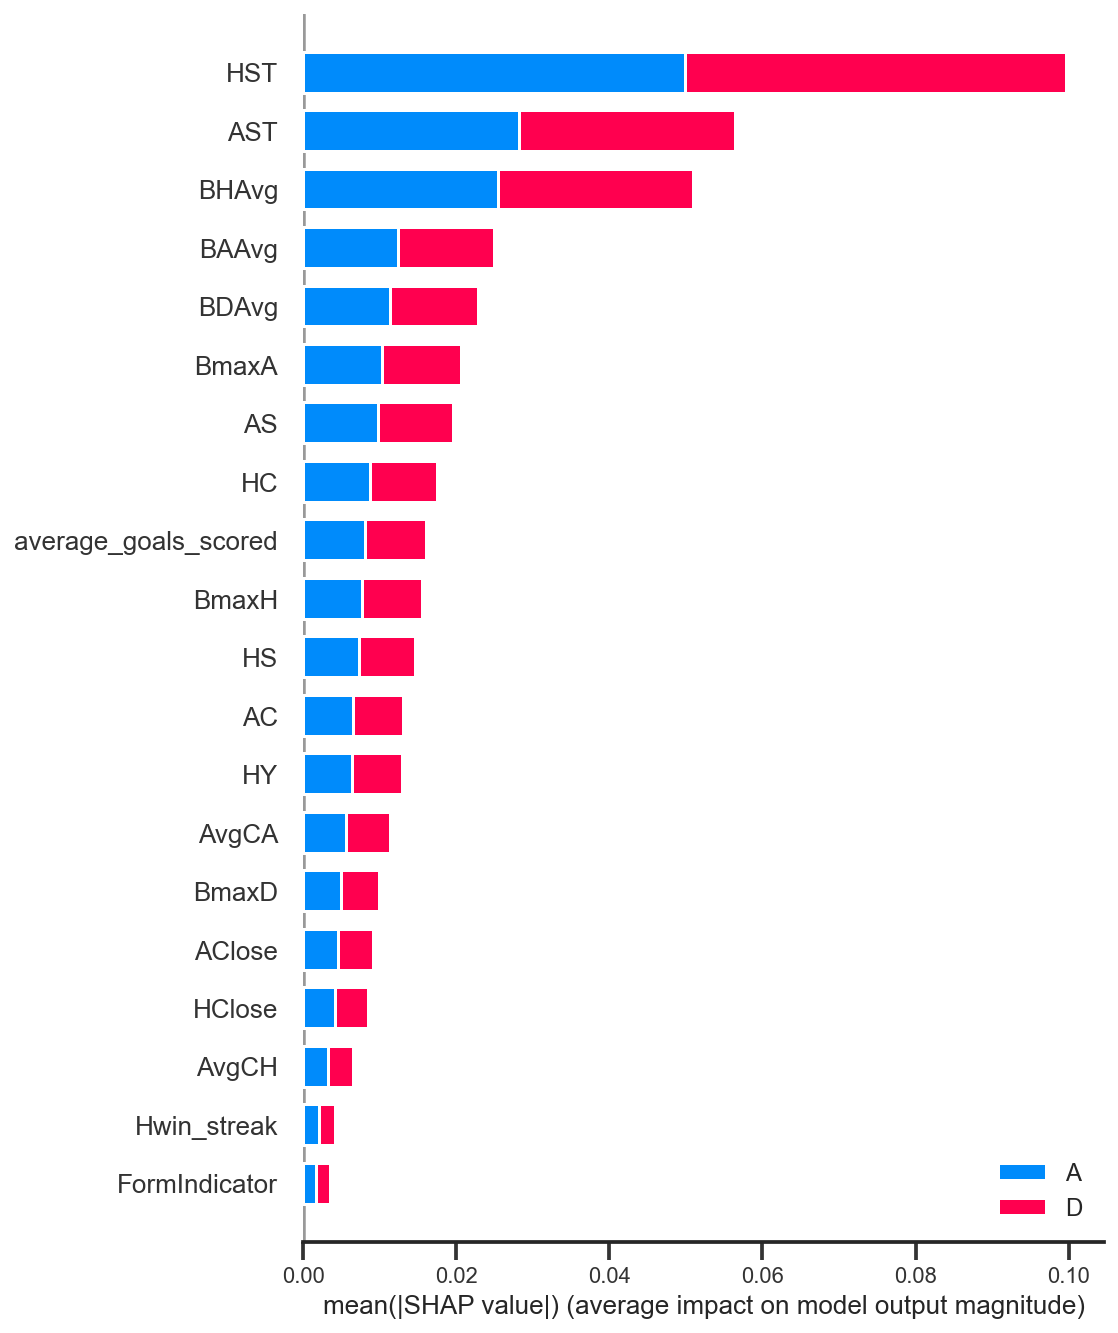

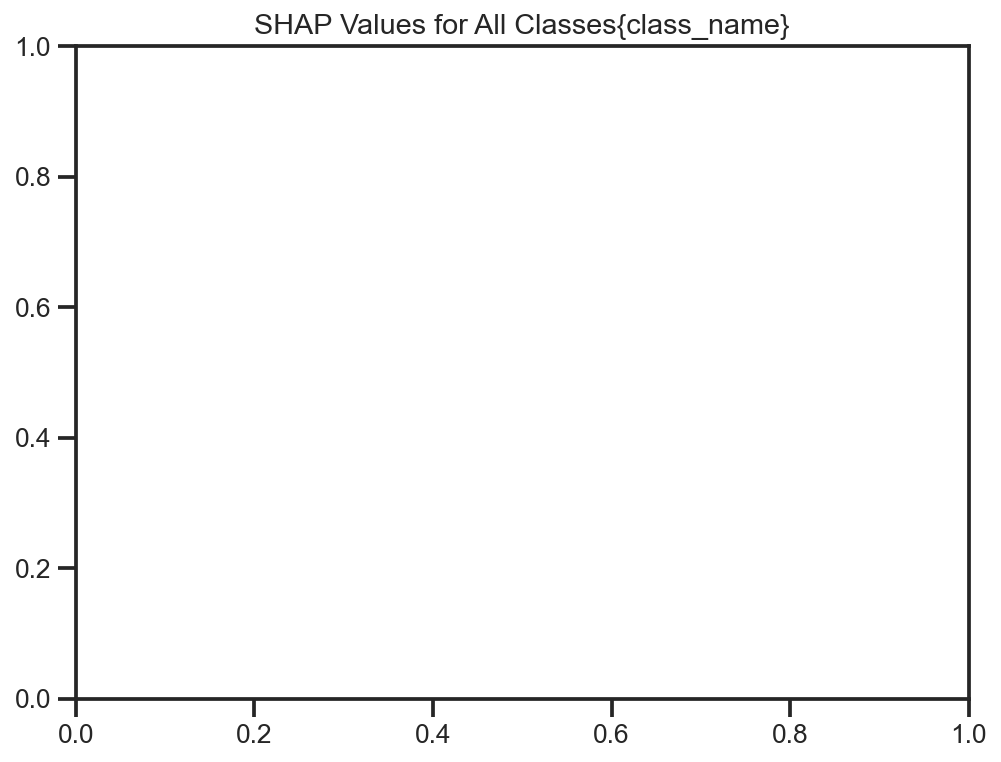

In [220]:
# Flatten the list of shap_values
# flattened_shap_values = [shap_value for class_shap_values in shap_values for shap_value in class_shap_values]

# List of class_names
class_names = label_encoder.classes_

# Create a single plot for all classes
for i, class_name in enumerate(class_names):
    shap.summary_plot(shap_values[i], features = X_val, class_names =class_names, plot_type='bar')
    plt.title("SHAP Values for All Classes{class_name}")
    plt.show()

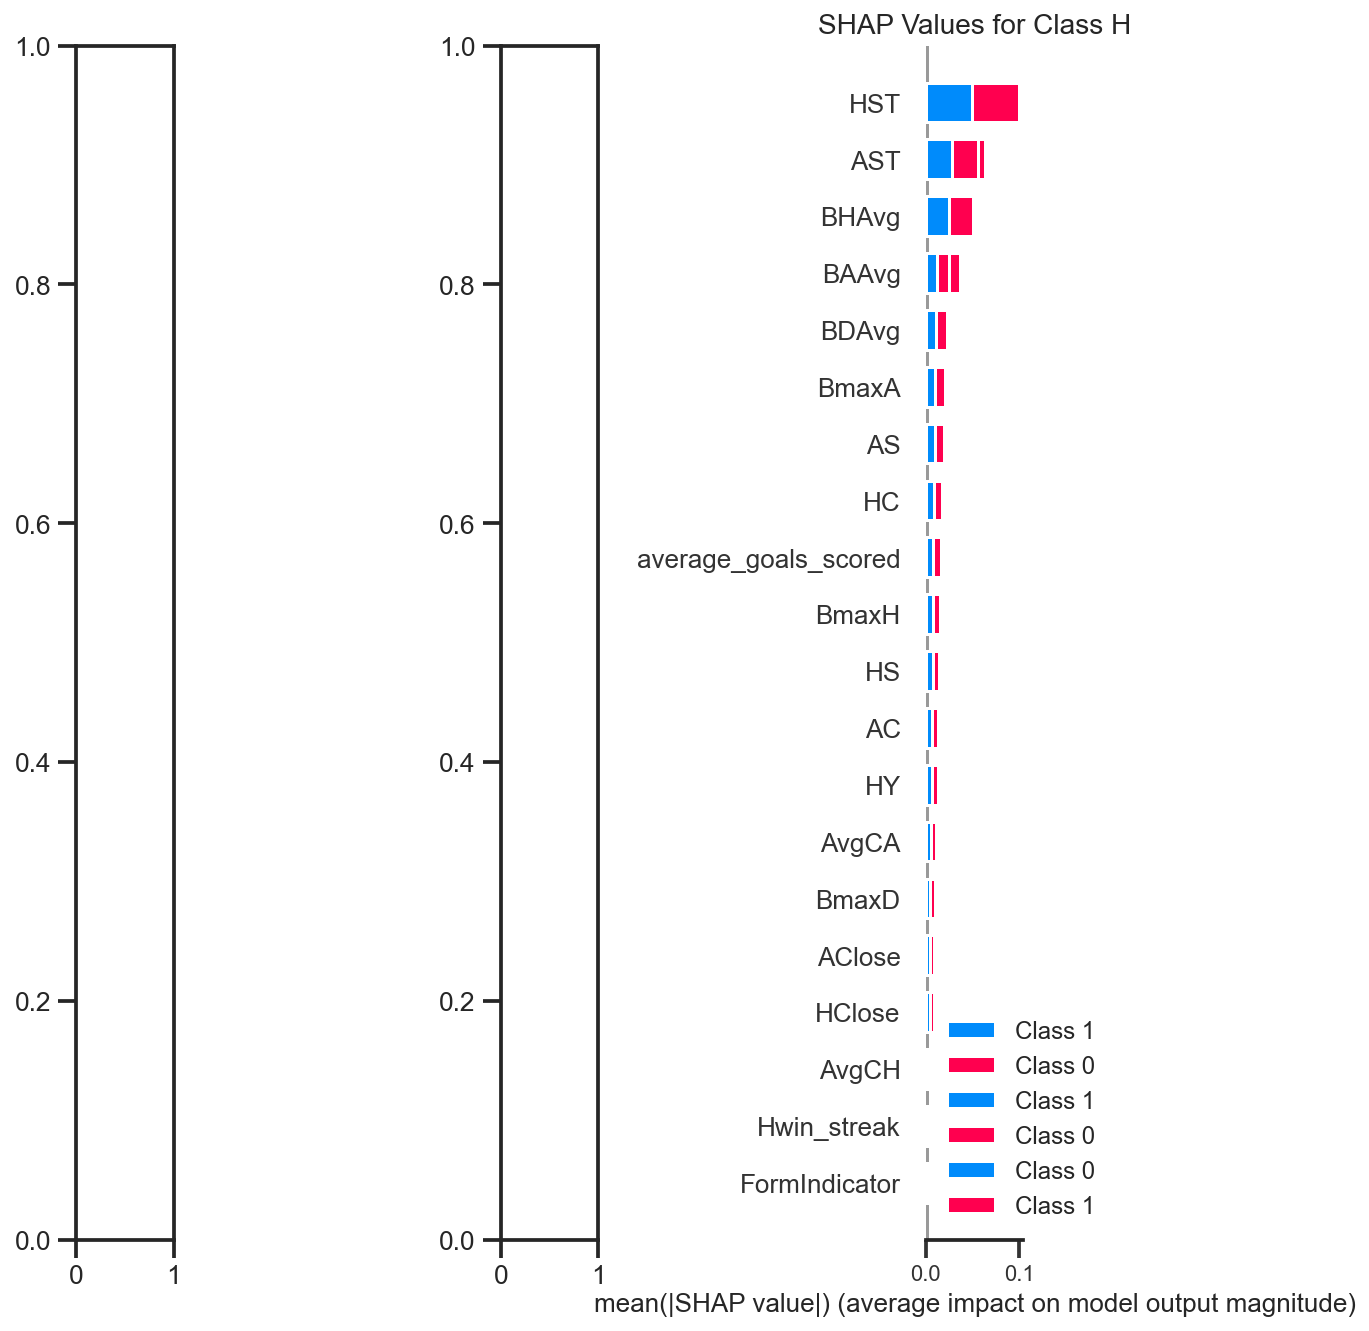

In [221]:
import matplotlib.pyplot as plt

# Assuming you have the 'shap_values' and 'X_val' ready

# Summary plot for each class
fig, axes = plt.subplots(nrows=1, ncols=len(label_encoder.classes_), figsize=(20, 5))
for i, class_name in enumerate(label_encoder.classes_):
    # Plot the summary plot for each class
    shap.summary_plot(shap_values[i], features=X_val, plot_type='bar', show=False)
    # Get the current axis and set the title for the specific class
    ax = plt.gca()
    ax.set_title(f"SHAP Values for Class {class_name}", fontsize=14)
    # Adjust the layout to prevent overlapping of subplots
    plt.tight_layout()

# Display the plot
plt.show()


#### 5.9.2 Local Explanation

In [222]:
# Individual shap valu plot for the spesific match prediction
#index_to_plot =0 # can change this index to plot shap values for different predictions
#shap.force_plot(explainer_expected_val;u, shap_values[index_to_plot], X_test.iloc[index_to_plot])


In [223]:
# Creat an instance of the best RFC model
# best_rfc_model = RandomForestClassifier(class_weight='balanced', max_depth= 10, n_estimators=50, random_state=42)

In [224]:
# Craete a sample data set for using shap
#background_summary = shap.sample(X_train, 100)

In [225]:
# Create an explainer for the best mode with Explainer
#explainer = shap.TreeExplainer(best_rfc_model, background_summary)

In [226]:
# Compute SHAP valus for sample of testing data
# sample_index = 0
# shap_values = explainer.shap_values(X_test.iloc[sample_index])

# # Print the shape of shap values for each class
# for i, shap_values_class in enumerate(shap_values):
#     print(f"Shape of SHAP_values for class {i}: {shap_values_class.shape}")
# print("Shape of X_test:", X_test.shape)

In [227]:
# get the number of classes
#num_classes = len(shap_values) if isinstance(shap_values, list) else 1

In [228]:
# # Replace the sample index with index of sample needs to visalize
# #class_index = 0

# # Get summary plot for the sample (Global view) for each class
# for class_index in range(num_classes):
#     # Create a single class shap array for the current class
#     shap_values_class = shap_values[class_index]
    
#     # Converts the vector of shap values into a 2d matrix for the current class
#     #Matrix should have only one row since we are plotting for a single sample
#     shap_values_class = np.expand_dims(shap_values_class, axis=0)
    
#     # Get the feature names for the current class
#     feature_names_class = X_test.columns if X_test.columns is not None else None
    
#     # Visualize the SHAPO values using force_plot for the current class and sample
#     shap.force_plot(explainer.expected_value[class_index], shap_values_class, X_test.iloc[sample_index], feature_names_class)

In [229]:
# # Get summary plot for the sample (Global view) for each class
# for class_index in range(num_classes):
#     # Reshape the shap values to 2d matrix (if needed)
#     if len(shap_values[class_index].shape) == 1:
#         shap_value_class = shap_values[class_index].reshape(1, -1)
#     else:
#         shap_values_class = shap_values[class_index]
        
#     shap.summary_plot(shap_values_class, X_test.iloc[sample_index], plot_type="bar")

In [230]:
#shap.summary_plot(shap_values, X_test, max_display=8)

In [231]:
## Get the best RF model
#best_gbc_model= gbc_grid_search.best_estimator_

In [232]:
# Train the best model on combine train and validation data
##best_gbc_model.fit(X_train.append(X_val), y_train.append(y_val))

In [233]:
# verify that best_gbc_model is  a valid Gradient Boosting Classifier with predict_proba method
#print(callable(voting_classifier.predict_proba))

# # Check the shape and content of X_test to ensure it's in the correct format
# print(X_test.shape)
# print(X_test.head())

# # Check if the predict_proba method works correctly on a small sample of data
# sample_data = X_test.iloc[0:1]
# try:
#     predictions = best_gbc_model.predict_proba(sample_data)
#     print(predictions)
# except Exceptions as e:
#     print(f"Error: {e}")

## 7. Model Demonstration

In [234]:
import pickle
from sklearn.ensemble import RandomForestClassifier

In [235]:
# Get the best RF model
# best_rfc_classifier= best_rf_model

In [236]:
# Save the trained model to a file using pickle
with open('F:/Project Demo/best_rf_model.pkl', 'wb') as model_file:
    pickle.dump(best_rf_model, model_file)

In [237]:
# Load the saved Voting Classifire model from the file
with open('F:/Project Demo/best_rf_model.pkl', 'rb') as model_file:
    loaded_model = pickle.load(model_file)

In [238]:
import random

# Define the number of demos needs to make
num_demo_examples = 10

# Let's make it random in selecting 'num_demo_examples'
demo_indices = random.sample(range(len(X_test)), num_demo_examples)

# Generate the subset for the demo with the aid of selected indices
X_demo = X_test.iloc[demo_indices]
y_demo = y_test.iloc[demo_indices]

In [239]:
# Fit the loaded model with the demo data
loaded_model.fit(X_demo, y_demo)

RandomForestClassifier(class_weight='balanced', max_depth=40, n_estimators=200,
                       random_state=42)

In [240]:
# X_new is the new data fed for the prediction of the results
predictions = loaded_model.predict(X_demo)

In [241]:
all_teams = team_counts.index.tolist()

# Display total list of teams and the number of matches they played as home and away teams
for team in all_teams:
    home_matches = home_team_counts.get(team, 0)
    away_matches = away_team_counts.get(team, 0)
    total_matches = home_matches + away_matches
    print(f"{team}: Home Matches - ({home_matches}, Away Matches- {away_matches}, Total Matches-{total_matches}")

AFC Wimbledon: Home Matches - (225, Away Matches- 224, Total Matches-449
Accrington: Home Matches - (224, Away Matches- 225, Total Matches-449
Aldershot: Home Matches - (223, Away Matches- 225, Total Matches-448
Alfreton Town: Home Matches - (46, Away Matches- 46, Total Matches-92
Altrincham: Home Matches - (112, Away Matches- 113, Total Matches-225
Arsenal: Home Matches - (189, Away Matches- 190, Total Matches-379
Aston Villa: Home Matches - (201, Away Matches- 202, Total Matches-403
Barnet: Home Matches - (220, Away Matches- 224, Total Matches-444
Barnsley: Home Matches - (244, Away Matches- 244, Total Matches-488
Barrow: Home Matches - (180, Away Matches- 179, Total Matches-359
Birmingham: Home Matches - (230, Away Matches- 230, Total Matches-460
Blackburn: Home Matches - (230, Away Matches- 230, Total Matches-460
Blackpool: Home Matches - (224, Away Matches- 225, Total Matches-449
Bolton: Home Matches - (224, Away Matches- 224, Total Matches-448
Boreham Wood: Home Matches - (176, A

In [242]:
# Print the columns of X_demo
print(X_demo.columns)

# Print the head
# print(X_demo.head())

Index(['HomeTeam_AFC Wimbledon', 'HomeTeam_Accrington', 'HomeTeam_Aldershot',
       'HomeTeam_Alfreton Town', 'HomeTeam_Altrincham', 'HomeTeam_Arsenal',
       'HomeTeam_Aston Villa', 'HomeTeam_Barnet', 'HomeTeam_Barnsley',
       'HomeTeam_Barrow',
       ...
       'BAAvg', 'BmaxH', 'BmaxD', 'BmaxA', 'HClose', 'AClose', 'HLost_streak',
       'Hwin_streak', 'average_goals_scored', 'FormIndicator'],
      dtype='object', length=304)


In [243]:
#Display all the columns
columns_list = X_demo.columns.tolist()

# Print the columns of X_demo
print(columns_list)

['HomeTeam_AFC Wimbledon', 'HomeTeam_Accrington', 'HomeTeam_Aldershot', 'HomeTeam_Alfreton Town', 'HomeTeam_Altrincham', 'HomeTeam_Arsenal', 'HomeTeam_Aston Villa', 'HomeTeam_Barnet', 'HomeTeam_Barnsley', 'HomeTeam_Barrow', 'HomeTeam_Birmingham', 'HomeTeam_Blackburn', 'HomeTeam_Blackpool', 'HomeTeam_Bolton', 'HomeTeam_Boreham Wood', 'HomeTeam_Bournemouth', 'HomeTeam_Bradford', 'HomeTeam_Braintree Town', 'HomeTeam_Brentford', 'HomeTeam_Brighton', 'HomeTeam_Bristol City', 'HomeTeam_Bristol Rvs', 'HomeTeam_Bromley', 'HomeTeam_Burnley', 'HomeTeam_Burton', 'HomeTeam_Bury', 'HomeTeam_Cambridge', 'HomeTeam_Cardiff', 'HomeTeam_Carlisle', 'HomeTeam_Charlton', 'HomeTeam_Chelsea', 'HomeTeam_Cheltenham', 'HomeTeam_Chester', 'HomeTeam_Chesterfield', 'HomeTeam_Chorley', 'HomeTeam_Colchester', 'HomeTeam_Coventry', 'HomeTeam_Crawley Town', 'HomeTeam_Crewe', 'HomeTeam_Crystal Palace', 'HomeTeam_Dag and Red', 'HomeTeam_Dartford', 'HomeTeam_Derby', 'HomeTeam_Doncaster', 'HomeTeam_Dorking', 'HomeTeam_Dove

In [244]:
print("Features inencoded_data")
for feature_name, feature_value in encoded_data.items():
   print(f"{feature_name}: {feature_value}") 

Features inencoded_data
HomeTeam_AFC Wimbledon: 0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
25393    0.0
25394    0.0
25395    0.0
25396    0.0
25397    0.0
Name: HomeTeam_AFC Wimbledon, Length: 25398, dtype: float64
HomeTeam_Accrington: 0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
25393    0.0
25394    0.0
25395    0.0
25396    0.0
25397    0.0
Name: HomeTeam_Accrington, Length: 25398, dtype: float64
HomeTeam_Aldershot: 0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
25393    0.0
25394    0.0
25395    0.0
25396    0.0
25397    0.0
Name: HomeTeam_Aldershot, Length: 25398, dtype: float64
HomeTeam_Alfreton Town: 0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
25393    0.0
25394    0.0
25395    0.0
25396    0.0
25397    0.0
Name: HomeTeam_Alfreton Town, Length: 25398, dtype: float64
HomeTeam_Altrincham: 0        0.0
1        0.0
2        0.0
3        0.0
4        

In [247]:
# Let's filter the data to include only the matches involving 'Man City' as the home team in the demo subset
matches_involving_man_city = X_demo[(X_demo['HomeTeam_Man City']==1.0) | (X_demo['AwayTeam_Man City']==1.0)]

# Check if there are matches available for prediction in the demo set
if not matches_involving_man_city.empty:
    # Make predictions  for the matched involving "Man City" as the home team in the demo subset
    predictions_man_city = loaded_model.predict(matches_involving_man_city)
    
    # Map the predicted labels to the corresponding outcomes (H, A or D)
    predicted_outcomes = ['H' if prediction == 0 else 'D' if prediction == 1 else 'A' for prediction in predictions_man_city]
       
    # Print the predictions for "Man City" matches as the home team in the demo subset
    for i, match_outcome in enumerate(predicted_outcomes):
        home_team = X_demo.loc[matches_involving_man_city.index[i], 'HomeTeam_Man City']
        away_team = X_demo.loc[matches_involving_man_city.index[i], 'AwayTeam_Man City']
        print(f"Match {i+1}: {home_team} vs {away_team}- Predicted outcome: {match_outcome}")
else:
    print("No matches involving 'Man City' available for the prediction in the demo subset.")

No matches involving 'Man City' available for the prediction in the demo subset.


In [248]:
# Let's filter the data to include only the matches involving 'Man City' as the home team in the demo subset
mask_man_city_home = X_demo['HomeTeam_Man City'] == 1.0
mask_man_city_away = X_demo['AwayTeam_Man City'] == 1.0
matches_involving_man_city = X_demo[mask_man_city_home | mask_man_city_away]

# Check if there are matches available for prediction in the demo set
if not matches_involving_man_city.empty:
    # Make predictions  for the matched involving "Man City" as the home team in the demo subset
    predictions_Man_City = loaded_model.predict(matches_involving_man_city)
    
    # Map the predicted labels to the corresponding outcomes (H, A or D)
    predicted_outcomes = ['H' if prediction == 0 else 'D' if prediction == 1 else 'A' for prediction in predictions_man_city]
       
    # Print the predictions for "Man City" matches as the home team in the demo subset
    for i, match_outcome in enumerate(predicted_outcomes):
        home_team = 'HomeTeam_Man_City' if mask_man_city_home.iloc[i] else X_demo['HomeTeam'][i]
        away_team = 'AwayTeam_Man_City' if mask_man_city_away.iloc[i] else X_demo['AwayTeam'][i]
        print(f"Match {i+1}: {home_team} vs {away_team}- Predicted outcome: {match_outcome}")
else:
    print("No matches involving 'Man City' available for the prediction in the demo subset.")

No matches involving 'Man City' available for the prediction in the demo subset.
